# 스프린트 미션8 | U-Net을 이용해 축구 경기 내 다양한 객체 분할 #

#### 이번 미션에서는 U-Net을 이용해 축구 경기 영상 내의 다양한 객체(예: 골대, 심판, 선수, 관중 등)를 픽셀 단위로 분할하는 Semantic Segmentation 작업을 수행한다. 실제 경기 장면에서 추출한 이미지를 바탕으로, 각 픽셀이 어떤 클래스에 속하는지 예측하는 모델을 직접 설계하고 학습한다. ####

### 목차 ###

0. 서론
1. 데이터 불러오기 & 전처리
2. U-Net 모델
3. U-Net++ 모델
4. Attention U-Net 모델
5. 중간 점검
6. Optuna 하이퍼파라미터 활용
7. 전체 결론

## 0. 서론 ##

이번 미션에서는 U-Net 계열 모델을 활용하여 축구 경기 영상 내의 다양한 객체(골대, 심판, 선수, 관중 등)를 픽셀 단위로 분할하는 Semantic Segmentation 작업을 수행한다.
데이터 소개


**데이터 소개**
 - The Oxford-IIIT Pet Dataset
  - annotations(xml): 각 이미지 파일에 대한 annotation
  - images: 이미지 파일(37종의 개와 고양이)

**생각해보자**




**데이터 소개**
- Football Semantic Segmentation Dataset
  - 출처: UEFA 슈퍼컵 2017 (레알 마드리드 vs 맨체스터 유나이티드) 하이라이트 영상
  - 총 100장의 프레임 이미지 (매 12번째 프레임 추출)
  - 마스크: RGB 색상으로 클래스를 표현한 Segmentation Mask
  - 클래스 수: 11개 (Goal Bar, Referee, Advertisement, Ground, Ball, Coaches & Officials, Audience, Goalkeeper A/B, Team A/B)



**생각해보자**

어떤 모델 구조를 사용하는 것이 좋을까?

- U-Net : 기본 Encoder-Decoder 구조, Skip Connection으로 공간 정보 보존
- U-Net++ : Dense Skip Connection으로 다양한 스케일의 특징을 더 풍부하게 융합
- Attention U-Net : Attention Gate를 통해 중요한 영역에 집중, 불필요한 특징 억제 → 세 가지 모델을 모두 구현하여 성능을 비교한다. 단, 100장이라는 소규모 데이터셋 특성상 과적합 위험이 있으므로 Data Augmentation과 EarlyStopping을 적극 활용한다. 또한 Optuna를 통해 각 모델의 최적 하이퍼파라미터를 탐색하고, IoU 및 Dice IoU 지표로 최종 성능을 비교한다.

## 1. 데이터 불러오기 & 전처리 ##

### 1-1. 데이터 불러오기 ###
-> Kaggle에서 Football Semantic Segmentation Dataset을 다운받는다.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sadhliroomyprime/football-semantic-segmentation")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'football-semantic-segmentation' dataset.
Path to dataset files: /kaggle/input/football-semantic-segmentation


### 1-2. GPU 불러오기 ###

In [ ]:
import torch

# GPU 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


### 1-3. 이미지 파일 로드 & 쌍 매칭 ###

In [ ]:
import os
import cv2

# 폴더 내 모든 파일 목록 가져오기
image_folder = os.path.join(path, "images")
file_list = os.listdir(image_folder)

# 원본 이미지(.jpg)와 fuse 이미지 매칭
original_files = sorted([f for f in file_list if f.endswith(".jpg")])
fuse_files = sorted([f for f in file_list if "fuse" in f])

# 이미지 로드 및 확인
image_pairs = []
for orig_file in original_files:
    # 동일한 프레임의 fuse 파일 찾기
    base_name = orig_file.replace(".jpg", "")
    fuse_file = next((f for f in fuse_files if base_name in f), None)

    if fuse_file:
        # 원본과 마스크 로드
        img_path = os.path.join(image_folder, orig_file)
        mask_path = os.path.join(image_folder, fuse_file)

        img = cv2.imread(img_path)
        mask = cv2.imread(mask_path)

        if img is not None and mask is not None:
            image_pairs.append((img, mask))

# 최종적으로 로드된 이미지 쌍 개수 출력
print(f"{len(image_pairs)} pairs")

100 pairs


### 1-4. 이미지 쌍 시각화 ###

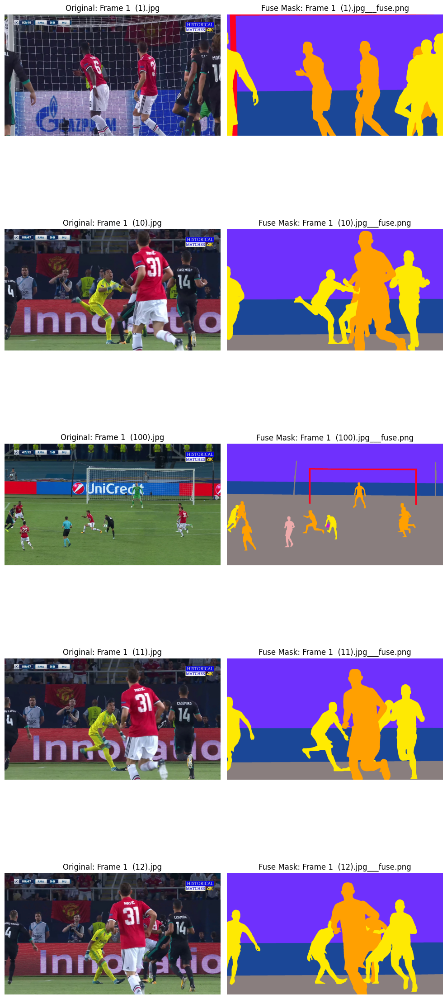

In [ ]:
import matplotlib.pyplot as plt

sample_image_pairs = []
num_samples = 5

for orig_file in original_files[:num_samples]:
    base_name = orig_file.replace(".jpg", "")
    fuse_file = next((f for f in fuse_files if base_name in f), None)

    if fuse_file:
        sample_image_pairs.append((orig_file, fuse_file))

# 이미지 5쌍 시각화
fig, axes = plt.subplots(num_samples, 2, figsize=(10, 5 * num_samples))

for i, (orig_file, fuse_file) in enumerate(sample_image_pairs):
    # 이미지 로드
    orig_img = cv2.imread(os.path.join(image_folder, orig_file))
    orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)  # OpenCV BGR → RGB 변환

    fuse_img = cv2.imread(os.path.join(image_folder, fuse_file))
    fuse_img = cv2.cvtColor(fuse_img, cv2.COLOR_BGR2RGB)  # 마스크도 RGB 변환

    # 시각화
    axes[i, 0].imshow(orig_img)
    axes[i, 0].set_title(f"Original: {orig_file}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(fuse_img)
    axes[i, 1].set_title(f"Fuse Mask: {fuse_file}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### 1-5. 마스크 고유 색상 확인 ###

In [ ]:
import numpy as np

# 전체 마스크에서 고유 색상 추출
color_set = set()

for orig_file in original_files:
    base_name = orig_file.replace(".jpg", "")
    fuse_file = next((f for f in fuse_files if base_name in f), None)

    if fuse_file:
        mask_path = os.path.join(image_folder, fuse_file)
        mask = cv2.imread(mask_path)
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

        # 마스크를 (픽셀 수, 3) 형태로 reshape 후 고유 색상 추출
        unique_colors = np.unique(mask.reshape(-1, 3), axis=0)

        for color in unique_colors:
            color_set.add(tuple(color))

# 결과 출력
print(f"총 고유 색상 수: {len(color_set)}")
print("\n고유 색상 목록 (RGB):")
for i, color in enumerate(sorted(color_set)):
    print(f"  {i:2d}: RGB{color}")

총 고유 색상 수: 11

고유 색상 목록 (RGB):
   0: RGB(np.uint8(0), np.uint8(0), np.uint8(0))
   1: RGB(np.uint8(27), np.uint8(71), np.uint8(151))
   2: RGB(np.uint8(111), np.uint8(48), np.uint8(253))
   3: RGB(np.uint8(137), np.uint8(126), np.uint8(126))
   4: RGB(np.uint8(201), np.uint8(19), np.uint8(223))
   5: RGB(np.uint8(238), np.uint8(171), np.uint8(171))
   6: RGB(np.uint8(254), np.uint8(233), np.uint8(3))
   7: RGB(np.uint8(255), np.uint8(0), np.uint8(29))
   8: RGB(np.uint8(255), np.uint8(159), np.uint8(0))
   9: RGB(np.uint8(255), np.uint8(160), np.uint8(1))
  10: RGB(np.uint8(255), np.uint8(235), np.uint8(0))


/tmp/ipykernel_1040/868620693.py:36: UserWarning: Glyph 50689 (\N{HANGUL SYLLABLE YEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/868620693.py:36: UserWarning: Glyph 50669 (\N{HANGUL SYLLABLE YEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50689 (\N{HANGUL SYLLABLE YEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50669 (\N{HANGUL SYLLABLE YEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


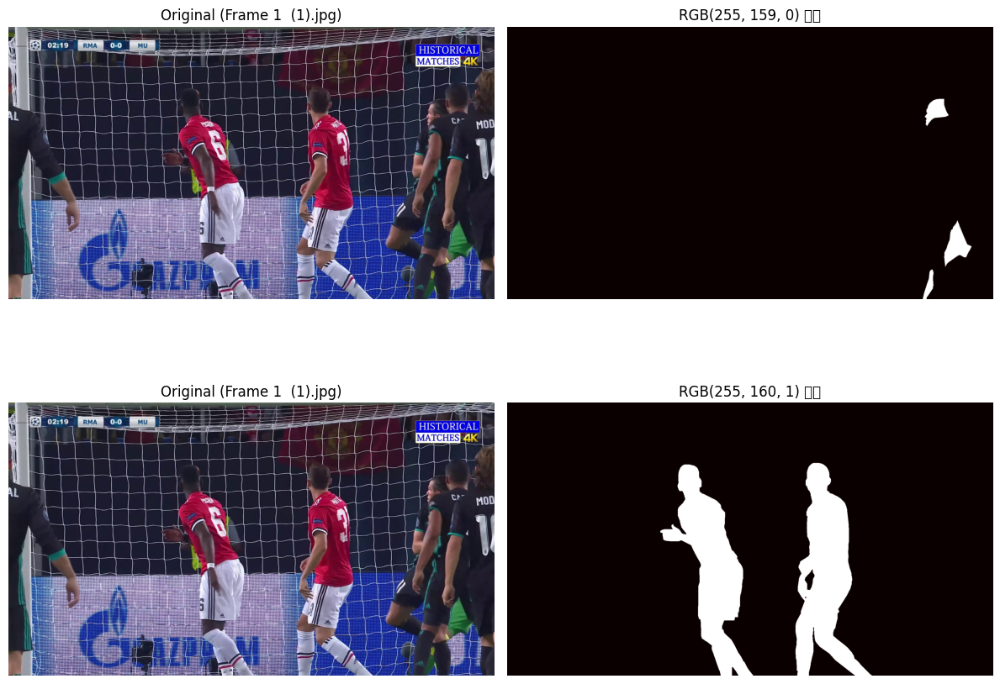

In [ ]:
# 특정 색상이 어느 영역에 해당하는지 시각적으로 확인
target_colors = [
    (255, 159, 0),
    (255, 160, 1),
]

fig, axes = plt.subplots(len(target_colors), 2, figsize=(12, 5 * len(target_colors)))

for i, target in enumerate(target_colors):
    # 첫 번째 마스크에서 해당 색상 영역만 추출
    for orig_file in original_files:
        base_name = orig_file.replace(".jpg", "")
        fuse_file = next((f for f in fuse_files if base_name in f), None)
        if not fuse_file:
            continue

        mask = cv2.imread(os.path.join(image_folder, fuse_file))
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

        # 해당 색상 픽셀만 True인 마스크 생성
        color_mask = np.all(mask == np.array(target), axis=-1)

        if color_mask.sum() > 0:  # 해당 색상이 존재하는 이미지 찾기
            orig_img = cv2.imread(os.path.join(image_folder, orig_file))
            orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

            axes[i, 0].imshow(orig_img)
            axes[i, 0].set_title(f"Original ({orig_file})")
            axes[i, 0].axis("off")

            axes[i, 1].imshow(color_mask, cmap="hot")
            axes[i, 1].set_title(f"RGB{target} 영역")
            axes[i, 1].axis("off")
            break

plt.tight_layout()
plt.show()

### 1-6. 색상 매핑 고정 + 검증 ###

In [ ]:
# 앞서 탐색한 고유 색상을 바탕으로 클래스 매핑을 명시적으로 고정
COLOR_TO_LABEL = {
    (0,   0,   0)  : 0,   # Background / Ground
    (27,  71,  151): 1,   # Team A
    (111, 48,  253): 2,   # Goalkeeper A
    (137, 126, 126): 3,   # Audience
    (201, 19,  223): 4,   # Coaches & Officials
    (238, 171, 171): 5,   # Advertisement
    (254, 233, 3)  : 6,   # Ground (잔디)
    (255, 0,   29) : 7,   # Referee
    (255, 159, 0)  : 8,   # Ball
    (255, 160, 1)  : 9,   # Team B
    (255, 235, 0)  : 10,  # Goal Bar
}

LABEL_TO_NAME = {
    0:  "Background",
    1:  "Team A",
    2:  "Goalkeeper A",
    3:  "Audience",
    4:  "Coaches & Officials",
    5:  "Advertisement",
    6:  "Ground",
    7:  "Referee",
    8:  "Ball",
    9:  "Team B",
    10: "Goal Bar",
}

print("=== 클래스 색상 매핑 ===")
for color, label in COLOR_TO_LABEL.items():
    print(f"  Label {label:2d} | {LABEL_TO_NAME[label]:<22} | RGB{color}")

=== 클래스 색상 매핑 ===
  Label  0 | Background             | RGB(0, 0, 0)
  Label  1 | Team A                 | RGB(27, 71, 151)
  Label  2 | Goalkeeper A           | RGB(111, 48, 253)
  Label  3 | Audience               | RGB(137, 126, 126)
  Label  4 | Coaches & Officials    | RGB(201, 19, 223)
  Label  5 | Advertisement          | RGB(238, 171, 171)
  Label  6 | Ground                 | RGB(254, 233, 3)
  Label  7 | Referee                | RGB(255, 0, 29)
  Label  8 | Ball                   | RGB(255, 159, 0)
  Label  9 | Team B                 | RGB(255, 160, 1)
  Label 10 | Goal Bar               | RGB(255, 235, 0)


이 이미지에 등장한 레이블: [1 2 6 7 8 9]
해당 클래스명: ['Team A', 'Goalkeeper A', 'Ground', 'Referee', 'Ball', 'Team B']


/tmp/ipykernel_1040/3886718090.py:36: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3886718090.py:36: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3886718090.py:36: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  fig.can

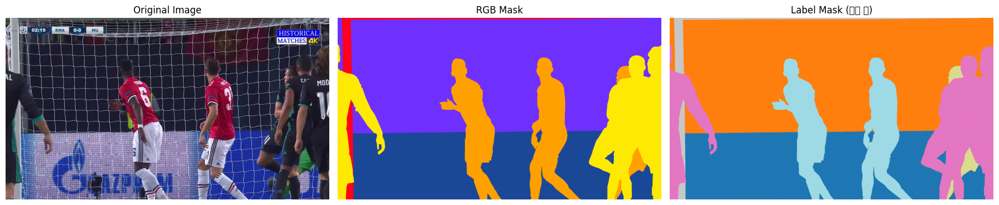

In [ ]:
# 매핑 검증 : 샘플 마스크 1장에 대해 변환 결과 시각화
sample_orig = original_files[0]
sample_fuse = next((f for f in fuse_files if sample_orig.replace(".jpg", "") in f), None)

orig_img = cv2.imread(os.path.join(image_folder, sample_orig))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

mask_rgb = cv2.imread(os.path.join(image_folder, sample_fuse))
mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)

# RGB 마스크 → 레이블 마스크 변환
mask_label = np.zeros(mask_rgb.shape[:2], dtype=np.uint8)
for color, label in COLOR_TO_LABEL.items():
    mask_label[(mask_rgb == np.array(color)).all(axis=-1)] = label

# 변환 결과에 등장한 레이블 확인
unique_labels = np.unique(mask_label)
print("이 이미지에 등장한 레이블:", unique_labels)
print("해당 클래스명:", [LABEL_TO_NAME[l] for l in unique_labels])

# 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(orig_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask_rgb)
axes[1].set_title("RGB Mask")
axes[1].axis("off")

axes[2].imshow(mask_label, cmap="tab20")
axes[2].set_title("Label Mask (변환 후)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### 1-7. FootvallDataset transform 추가하기 ###
-> dataset에 데이터는 100장으로 딥러닝 모델이 학습하기에는 적고, 과적합이 발생할 수 있다. 또한 축구 경기장 특성상 조명, 유니폼 색상 등 변수가 많아 학습량을 높이기 위해 transfor을 추가한다.

-> Segmentation은 이미지와 마스크를 동시에 같은 방식으로 변환해야 합니다. 예를 들어 이미지를 좌우 반전하면 마스크도 똑같이 반전해야 하죠. 그래서 torchvision.transforms를 이미지에만 적용하면 안 되고, 직접 동기화 처리가 필요하다.

------------------------------------
Resize (256×256)

RandomHorizontalFlip (p=0.5)

ColorJitter (밝기/대비/채도 0.7~1.3)

GaussianBlur (radius=1, p=0.5)

Normalize (ImageNet mean/std)

In [ ]:
import torchvision.transforms.functional as TF
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class FootballDataset(Dataset):
    def __init__(self, image_files, mask_files, image_folder,
                 color_to_label, augment=False):
        self.image_files    = image_files
        self.mask_files     = mask_files
        self.image_folder   = image_folder
        self.color_to_label = color_to_label
        self.augment        = augment  # Train: True / Test: False

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path  = os.path.join(self.image_folder, self.image_files[idx])
        mask_path = os.path.join(self.image_folder, self.mask_files[idx])

        # ── 이미지 & 마스크 로드 ─────────────────────────────────────
        img      = cv2.imread(img_path)
        img      = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask_rgb = cv2.imread(mask_path)
        mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)

        # ── Resize (이미지 + 마스크 동시) ────────────────────────────
        img      = cv2.resize(img,      (256, 256), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (256, 256), interpolation=cv2.INTER_NEAREST)
        # 마스크는 INTER_NEAREST 사용 : 보간 시 존재하지 않는 색상이 생겨 매핑이 깨지는 것을 방지

        # ── PIL 변환 (torchvision 함수 사용을 위해) ──────────────────
        img_pil  = Image.fromarray(img)
        mask_pil = Image.fromarray(mask_rgb)

        # ── Data Augmentation (Train 시에만 적용) ────────────────────
        if self.augment:
            # 1) RandomHorizontalFlip : 50% 확률로 좌우 반전
            #    축구 중계는 좌우 대칭 구도가 현실적으로 가능
            if random.random() > 0.5:
                img_pil  = TF.hflip(img_pil)
                mask_pil = TF.hflip(mask_pil)

            # 2) ColorJitter : 이미지에만 적용
            #    조명 변화, 카메라 노출 차이 등을 반영
            #    마스크에는 적용하지 않음 (색상으로 클래스를 표현하기 때문)
            img_pil = TF.adjust_brightness(img_pil, random.uniform(0.7, 1.3))
            img_pil = TF.adjust_contrast(img_pil,   random.uniform(0.7, 1.3))
            img_pil = TF.adjust_saturation(img_pil, random.uniform(0.7, 1.3))

            # 3) GaussianBlur : 이미지에만 적용
            #    카메라 흔들림, 선수 빠른 움직임으로 인한 블러 효과 반영
            if random.random() > 0.5:
                img_pil = img_pil.filter(ImageFilter.GaussianBlur(radius=1))

        # ── numpy 복귀 ───────────────────────────────────────────────
        img      = np.array(img_pil)
        mask_rgb = np.array(mask_pil)

        # ── RGB 마스크 → 레이블 마스크 변환 ─────────────────────────
        mask_label = np.zeros(mask_rgb.shape[:2], dtype=np.uint8)
        for color, label in self.color_to_label.items():
            mask_label[(mask_rgb == np.array(color)).all(axis=-1)] = label

        # ── 정규화 + 텐서 변환 ───────────────────────────────────────
        img = img / 255.0
        img = (img - np.array([0.485, 0.456, 0.406])) \
                   / np.array([0.229, 0.224, 0.225])
        # ImageNet 기준 mean/std 정규화

        img        = torch.tensor(img,        dtype=torch.float32).permute(2, 0, 1)
        mask_label = torch.tensor(mask_label, dtype=torch.long)

        return img, mask_label

### 1-8. DataLoader 구성 ###
-> 모델에 데이터를 공급하는 형태를 정의해준다.

- train / test 데이터 8:2로 분리
- batch_size = 8로 설정 (train)
- shuffle = True 로 설정. 에폭마다 데이터 순서를 섞는다

In [ ]:
from PIL import Image, ImageFilter
import torchvision.transforms.functional as TF
import random

# Train/Test Dataset 분리 생성
#  - train_dataset : augment=True  → Data Augmentation 적용
#  - test_dataset  : augment=False → 원본 그대로 평가

full_dataset = FootballDataset(
    image_files    = original_files,
    mask_files     = fuse_files,
    image_folder   = image_folder,
    color_to_label = COLOR_TO_LABEL,
    augment        = False  # 일단 False로 전체 Dataset 생성
)

# 8:2 비율로 인덱스 분리
train_size   = int(0.8 * len(full_dataset))
test_size    = len(full_dataset) - train_size
train_indices, test_indices = torch.utils.data.random_split(
    range(len(full_dataset)), [train_size, test_size]
)

# 인덱스 기반으로 augment 여부를 달리한 Dataset 생성
train_dataset = FootballDataset(
    image_files    = [original_files[i] for i in train_indices],
    mask_files     = [fuse_files[i]     for i in train_indices],
    image_folder   = image_folder,
    color_to_label = COLOR_TO_LABEL,
    augment        = True   # Train : 증강 적용
)

test_dataset = FootballDataset(
    image_files    = [original_files[i] for i in test_indices],
    mask_files     = [fuse_files[i]     for i in test_indices],
    image_folder   = image_folder,
    color_to_label = COLOR_TO_LABEL,
    augment        = False  # Test : 증강 미적용
)

# DataLoader 구성
train_loader = DataLoader(
    train_dataset,
    batch_size  = 8,
    shuffle     = True,
    drop_last   = True,
    num_workers = 0
)

test_loader = DataLoader(
    test_dataset,
    batch_size  = 1,
    shuffle     = False,
    drop_last   = False,
    num_workers = 0
)

print(f"Train Data : {len(train_dataset)}장")
print(f"Test Data  : {len(test_dataset)}장")
print(f"Train Loader 배치 수 : {len(train_loader)}")
print(f"Test Loader 배치 수  : {len(test_loader)}")

Train Data : 80장
Test Data  : 20장
Train Loader 배치 수 : 10
Test Loader 배치 수  : 20


### 1-9. 공통 구성요소 정의 ###

DiceLoss

- 예측 마스크와 정답 마스크의 겹치는 비율로 손실 계산
- Ball처럼 픽셀 수가 극히 적은 클래스에도 공평하게 Loss 반영

CombinedLoss

- CE Loss * 0.5 + Dice Loss * 0.5 로 두 Loss의 장점을 결합
- 가중치는 Optuna 탐색에서 조정 가능하도록 파라미터로 분리

calculate_iou / calculate_dice

- 클래스별로 계산 후 평균 → mIoU, mean Dice 반환
- union == 0 처리 : 해당 클래스가 아예 없는 이미지에서 오류 방지

EarlyStopping

- patience : 성능 개선 없이 허용할 에폭 수
- min_delta : 이 값 이상 줄어야 개선으로 인정
- 개선될 때마다 자동으로 최적 모델 저장

train_one_epoch / evaluate

- 모든 모델에서 공통으로 재사용 가능한 학습/평가 함수
- evaluate는 Loss, mIoU, Dice 세 가지를 한번에 반환

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ════════════════════════════════════════════════════════════════
# 1. Loss 함수
# ════════════════════════════════════════════════════════════════

class DiceLoss(nn.Module):
    def __init__(self, num_classes=11, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.num_classes = num_classes
        self.smooth      = smooth
        # smooth : 분모가 0이 되는 것을 방지하는 작은 값

    def forward(self, preds, targets):
        # preds   : (B, num_classes, H, W) - 모델 출력 (logits)
        # targets : (B, H, W)              - 정답 레이블

        # Softmax로 확률값으로 변환
        preds = F.softmax(preds, dim=1)

        # targets를 One-hot 인코딩 : (B, H, W) → (B, num_classes, H, W)
        targets_one_hot = F.one_hot(targets, self.num_classes)
        targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float()

        dice_loss = 0.0
        for c in range(self.num_classes):
            pred_c   = preds[:, c]           # 클래스 c의 예측값
            target_c = targets_one_hot[:, c] # 클래스 c의 정답값

            intersection = (pred_c * target_c).sum()
            union        = pred_c.sum() + target_c.sum()

            dice_loss += 1 - (2 * intersection + self.smooth) \
                             / (union + self.smooth)

        return dice_loss / self.num_classes  # 클래스 평균


class CombinedLoss(nn.Module):
    def __init__(self, num_classes=11, ce_weight=0.5, dice_weight=0.5):
        super(CombinedLoss, self).__init__()
        self.ce_loss   = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight   = ce_weight    # CrossEntropy 가중치
        self.dice_weight = dice_weight  # Dice Loss 가중치

    def forward(self, preds, targets):
        loss_ce   = self.ce_loss(preds, targets)
        loss_dice = self.dice_loss(preds, targets)
        return self.ce_weight * loss_ce + self.dice_weight * loss_dice


# ════════════════════════════════════════════════════════════════
# 2. 평가 함수 (IoU, Dice IoU)
# ════════════════════════════════════════════════════════════════

def calculate_iou(preds, targets, num_classes=11):
    preds    = torch.argmax(preds, dim=1)
    iou_list = []

    for c in range(num_classes):
        pred_c   = (preds == c)
        target_c = (targets == c)

        intersection = (pred_c & target_c).sum().float()
        union        = (pred_c | target_c).sum().float()

        if union == 0:
            # ← device=preds.device 추가
            iou_list.append(torch.tensor(1.0, device=preds.device))
        else:
            iou_list.append(intersection / union)

    return torch.stack(iou_list).mean().item()


def calculate_dice(preds, targets, num_classes=11, smooth=1e-6):
    preds     = torch.argmax(preds, dim=1)
    dice_list = []

    for c in range(num_classes):
        pred_c   = (preds == c).float()
        target_c = (targets == c).float()

        intersection = (pred_c * target_c).sum()
        union        = pred_c.sum() + target_c.sum()

        if union == 0:
            # ← device=preds.device 추가
            dice_list.append(torch.tensor(1.0, device=preds.device))
        else:
            dice_list.append((2 * intersection + smooth) / (union + smooth))

    return torch.stack(dice_list).mean().item()

# ════════════════════════════════════════════════════════════════
# 3. EarlyStopping
# ════════════════════════════════════════════════════════════════

class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4, path="best_model.pt"):
        self.patience   = patience    # 성능 개선 없이 허용할 최대 에폭 수
        self.min_delta  = min_delta   # 개선으로 인정할 최소 변화량
        self.path       = path        # 최적 모델 저장 경로
        self.best_loss  = float("inf")
        self.counter    = 0
        self.early_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            # 성능 개선 : 모델 저장 & counter 초기화
            self.best_loss = val_loss
            self.counter   = 0
            torch.save(model.state_dict(), self.path)
            print(f"  ✅ Val Loss 개선 → 모델 저장 (best_loss: {self.best_loss:.4f})")
        else:
            # 성능 미개선 : counter 증가
            self.counter += 1
            print(f"  ⚠️  EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
                print("  🛑 EarlyStopping 발동 → 학습 중단")


# ════════════════════════════════════════════════════════════════
# 4. 공통 학습 / 평가 함수
# ════════════════════════════════════════════════════════════════

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0

    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)  # 배치 평균 Loss


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss  = 0.0
    total_iou   = 0.0
    total_dice  = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            loss    = criterion(outputs, masks)

            total_loss += loss.item()
            total_iou  += calculate_iou(outputs,  masks)
            total_dice += calculate_dice(outputs, masks)

    n = len(loader)
    return (
        total_loss / n,   # 평균 Loss
        total_iou  / n,   # 평균 mIoU
        total_dice / n    # 평균 Dice
    )


# ════════════════════════════════════════════════════════════════
# 정의 확인
# ════════════════════════════════════════════════════════════════
print(" DiceLoss        정의 완료")
print(" CombinedLoss    정의 완료")
print(" calculate_iou   정의 완료")
print(" calculate_dice  정의 완료")
print(" EarlyStopping   정의 완료")
print(" train_one_epoch 정의 완료")
print(" evaluate        정의 완료")

 DiceLoss        정의 완료
 CombinedLoss    정의 완료
 calculate_iou   정의 완료
 calculate_dice  정의 완료
 EarlyStopping   정의 완료
 train_one_epoch 정의 완료
 evaluate        정의 완료


## 2. U-Net 모델 ##
### 2-1. U-Net 설계 ###

In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

class UNet(nn.Module):
    def __init__(self, num_classes=11, dropout_p=0.5):
        super(UNet, self).__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )

        # ── Encoder ───────────────────────────────────────────────────
        self.enc1 = conv_block(3,   64)
        self.enc2 = conv_block(64,  128)
        self.enc3 = conv_block(128, 256)
        self.enc4 = conv_block(256, 512)
        self.pool = nn.MaxPool2d(2, 2)

        # ── Bottleneck ────────────────────────────────────────────────
        # Dropout을 가장 강하게 적용 (dropout_p 그대로 사용)
        self.bottleneck = nn.Sequential(
            conv_block(512, 1024),
            nn.Dropout2d(p=dropout_p)
        )

        # ── Decoder ───────────────────────────────────────────────────
        self.up4  = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = conv_block(1024, 512)
        self.drop4 = nn.Dropout2d(p=dropout_p * 0.5)
        # Decoder에는 Bottleneck의 절반 강도로 적용 (0.25)
        # 깊은 단계일수록 추상적 특징 → 과적합 위험이 더 높음

        self.up3  = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = conv_block(512, 256)
        self.drop3 = nn.Dropout2d(p=dropout_p * 0.5)

        self.up2  = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = conv_block(256, 128)
        self.drop2 = nn.Dropout2d(p=dropout_p * 0.25)
        # 얕은 단계일수록 공간 정보가 중요 → 더 약하게 적용 (0.125)

        self.up1  = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = conv_block(128, 64)
        # 마지막 단계는 Dropout 미적용
        # 최종 예측 직전 단계이므로 정보 손실 최소화

        # ── 최종 출력 ─────────────────────────────────────────────────
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

        # ── 가중치 초기화 ─────────────────────────────────────────────
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        # ── Encoder ───────────────────────────────────────────────────
        e1 = self.enc1(x)                    # (B, 64,  256, 256)
        e2 = self.enc2(self.pool(e1))        # (B, 128, 128, 128)
        e3 = self.enc3(self.pool(e2))        # (B, 256,  64,  64)
        e4 = self.enc4(self.pool(e3))        # (B, 512,  32,  32)

        # ── Bottleneck ────────────────────────────────────────────────
        b  = self.bottleneck(self.pool(e4))  # (B, 1024, 16,  16)

        # ── Decoder ───────────────────────────────────────────────────
        d4 = self.drop4(self.dec4(torch.cat([self.up4(b),  e4], dim=1)))
        # (B, 512, 32, 32)
        d3 = self.drop3(self.dec3(torch.cat([self.up3(d4), e3], dim=1)))
        # (B, 256, 64, 64)
        d2 = self.drop2(self.dec2(torch.cat([self.up2(d3), e2], dim=1)))
        # (B, 128, 128, 128)
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        # (B, 64, 256, 256) - 마지막 단계 Dropout 미적용

        return self.final_conv(d1)  # (B, 11, 256, 256)


# ── 모델 확인 ──────────────────────────────────────────────────────
model = UNet(num_classes=11)
total_params = sum(p.numel() for p in model.parameters())
print(f"U-Net 총 파라미터 수 : {total_params:,}")

U-Net 총 파라미터 수 : 31,038,283


### 2-2. U-Net 모델 학습 ###

In [ ]:
import torch.optim as optim

# ── 모델 / Loss / Optimizer 초기화 ───────────────────────────────
model     = UNet(num_classes=11).to(device)
criterion = CombinedLoss(num_classes=11, ce_weight=0.5, dice_weight=0.5)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 100  # 50 → 100으로 변경

# ── 학습률 스케줄러 ───────────────────────────────────────────────
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = 0.001,
    epochs          = num_epochs,   # num_epochs와 반드시 동일하게
    steps_per_epoch = len(train_loader),
    pct_start       = 0.3
)

# ── EarlyStopping 초기화 ─────────────────────────────────────────
early_stopping = EarlyStopping(
    patience  = 15,       # 10 → 15으로 변경
    min_delta = 1e-4,
    path      = "best_unet.pt"
)

# ── 학습 기록 저장 ────────────────────────────────────────────────
history = {
    "train_loss" : [],
    "val_loss"   : [],
    "val_iou"    : [],
    "val_dice"   : []
}

# ── 학습 루프 ─────────────────────────────────────────────────────
print("=" * 60)
print("U-Net 학습 시작")
print("=" * 60)

for epoch in range(num_epochs):
    # Train (train_one_epoch 내부에서 Gradient Clipping 자동 적용)
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)

    # 스케줄러 업데이트
    scheduler.step()

    # Validation
    val_loss, val_iou, val_dice = evaluate(model, test_loader, criterion, device)

    # 기록 저장
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["val_dice"].append(val_dice)

    print(f"Epoch [{epoch+1:3d}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val mIoU: {val_iou:.4f} | "
          f"Val Dice: {val_dice:.4f}")

    # EarlyStopping 체크
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f"\n EarlyStopping 발동 → {epoch+1} 에폭에서 학습 종료")
        break

print("\n" + "=" * 60)
print(" U-Net 학습 완료")
print("=" * 60)

# ── 최적 모델 로드 ────────────────────────────────────────────────
model.load_state_dict(torch.load("best_unet.pt", weights_only=True))
print(" 최적 모델 로드 완료")

# ── 최종 성능 출력 ────────────────────────────────────────────────
best_epoch = history["val_loss"].index(min(history["val_loss"])) + 1
print(f"\n📊 최적 성능 (Epoch {best_epoch})")
print(f"  Val Loss  : {min(history['val_loss']):.4f}")
print(f"  Val mIoU  : {history['val_iou'][best_epoch-1]:.4f}")
print(f"  Val Dice  : {history['val_dice'][best_epoch-1]:.4f}")

U-Net 학습 시작
Epoch [  1/100] Train Loss: 2.7853 | Val Loss: 1.8673 | Val mIoU: 0.0221 | Val Dice: 0.0398
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.8673)
Epoch [  2/100] Train Loss: 2.2609 | Val Loss: 1.6610 | Val mIoU: 0.0814 | Val Dice: 0.1168
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.6610)
Epoch [  3/100] Train Loss: 1.9188 | Val Loss: 1.5410 | Val mIoU: 0.1124 | Val Dice: 0.1508
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.5410)
Epoch [  4/100] Train Loss: 1.6950 | Val Loss: 1.4986 | Val mIoU: 0.1241 | Val Dice: 0.1649
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.4986)
Epoch [  5/100] Train Loss: 1.5360 | Val Loss: 1.4024 | Val mIoU: 0.1339 | Val Dice: 0.1768
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.4024)
Epoch [  6/100] Train Loss: 1.4100 | Val Loss: 1.2988 | Val mIoU: 0.1442 | Val Dice: 0.1912
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.2988)
Epoch [  7/100] Train Loss: 1.3357 | Val Loss: 1.1971 | Val mIoU: 0.1593 | Val Dice: 0.2128
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.1971)
Epoch [  8/100] Train Loss: 1.2312 |

구간별 특징
- Epoch 1~26 : Val Loss가 매 에폭마다 안정적으로 감소. EarlyStopping 한 번도 발동 안 함. 정상적인 초기 수렴 구간입니다.
- Epoch 27~60 : Val Loss가 소폭 진동하면서 EarlyStopping counter가 간헐적으로 발동. mIoU는 이 구간에서 0.3→0.5 수준으로 가파르게 상승합니다.
- Epoch 60~76 : mIoU가 0.5→0.73으로 급상승하는 핵심 구간. Val Loss도 0.36대까지 안정적으로 하강합니다.
- Epoch 86 : Val Loss 0.9714, Train Loss 0.3973으로 갑자기 스파이크 발생. Train Loss는 정상인데 Val Loss만 튀었으므로 Test 20장 샘플 노이즈입니다. 이전 세션과 동일한 패턴입니다.
- Epoch 87~94 : 스파이크 이후 빠르게 회복. 모델 자체는 정상입니다.
- Epoch 95~97 : 회복 완료 후 최고 성능 달성. Val Loss 0.2890, mIoU 0.7994.

### 2-3. 학습 곡선 시각화 ###

/tmp/ipykernel_1040/152011585.py:32: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/152011585.py:32: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/152011585.py:32: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/152011585.py:32: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/d

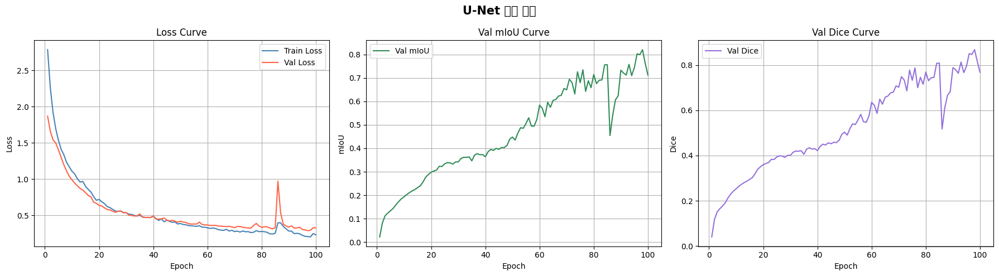

In [ ]:
# ── 학습 곡선 시각화 ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs = range(1, len(history["train_loss"]) + 1)

# Loss 곡선
axes[0].plot(epochs, history["train_loss"], label="Train Loss", color="steelblue")
axes[0].plot(epochs, history["val_loss"],   label="Val Loss",   color="tomato")
axes[0].set_title("Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# mIoU 곡선
axes[1].plot(epochs, history["val_iou"], label="Val mIoU", color="seagreen")
axes[1].set_title("Val mIoU Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

# Dice 곡선
axes[2].plot(epochs, history["val_dice"], label="Val Dice", color="mediumpurple")
axes[2].set_title("Val Dice Curve")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Dice")
axes[2].legend()
axes[2].grid(True)

plt.suptitle("U-Net 학습 곡선", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Loss Curve에서 Epoch 80 근처에 Val Loss가 살짝 튀는 구간이 보입니다. 크게 튀지 않고 안정적으로 수렴했습니다. Decoder Dropout과 Gradient Clipping 효과가 나타난 것입니다.

mIoU와 Dice는 100 에폭 가까이까지 꾸준히 상승하는 패턴이 보입니다. Epoch 93에서 최적이 나왔다는 것은 충분히 수렴했다고 보입니다.

### 2-4. 예측 마스크 시각화 ###

/tmp/ipykernel_1040/1406102222.py:52: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/1406102222.py:52: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/1406102222.py:52: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/1406102222.py:52: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.1

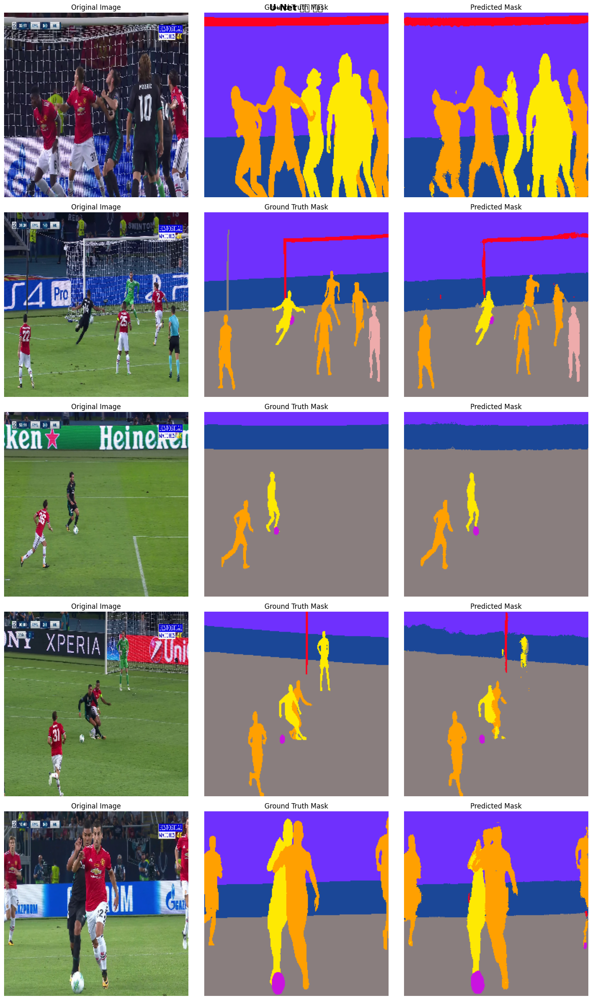

In [ ]:
# ── 예측 마스크 시각화 ────────────────────────────────────────────
# 클래스별 색상 팔레트 정의 (COLOR_TO_LABEL의 색상을 그대로 활용)
PALETTE = np.array(list(COLOR_TO_LABEL.keys()), dtype=np.uint8)  # (11, 3)

def label_to_rgb(mask_label, palette):
    """레이블 마스크 (H, W) → RGB 이미지 (H, W, 3)"""
    h, w    = mask_label.shape
    rgb_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for label, color in enumerate(palette):
        rgb_mask[mask_label == label] = color
    return rgb_mask

model.eval()
num_vis = 5  # 시각화할 샘플 수

fig, axes = plt.subplots(num_vis, 3, figsize=(15, 5 * num_vis))

with torch.no_grad():
    for i, (images, masks) in enumerate(test_loader):
        if i >= num_vis:
            break

        images = images.to(device)
        outputs = model(images)
        pred_mask = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()  # (H, W)
        true_mask = masks.squeeze(0).cpu().numpy()                          # (H, W)

        # 원본 이미지 역정규화
        img_np = images.squeeze(0).cpu().permute(1, 2, 0).numpy()
        img_np = img_np * np.array([0.229, 0.224, 0.225]) \
                        + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)

        # 레이블 → RGB 변환
        pred_rgb = label_to_rgb(pred_mask, PALETTE)
        true_rgb = label_to_rgb(true_mask, PALETTE)

        # 시각화
        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title("Original Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(true_rgb)
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred_rgb)
        axes[i, 2].set_title("Predicted Mask")
        axes[i, 2].axis("off")

plt.suptitle("U-Net 예측 결과", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. U-Net++ ##

### 3-1. U-Net++ 모델 설계 ###

In [ ]:
class UNetPlusPlus(nn.Module):
    def __init__(self, num_classes=11, dropout_p=0.5):
        super(UNetPlusPlus, self).__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )

        ch = [64, 128, 256, 512, 1024]

        # ── Encoder (Xi,0) ────────────────────────────────────────────
        self.enc0 = conv_block(3,     ch[0])  # (B, 64,  256, 256)
        self.enc1 = conv_block(ch[0], ch[1])  # (B, 128, 128, 128)
        self.enc2 = conv_block(ch[1], ch[2])  # (B, 256,  64,  64)
        self.enc3 = conv_block(ch[2], ch[3])  # (B, 512,  32,  32)
        self.pool = nn.MaxPool2d(2, 2)

        # ── Bottleneck ────────────────────────────────────────────────
        self.bottleneck = nn.Sequential(
            conv_block(ch[3], ch[4]),          # (B, 1024, 16, 16)
            nn.Dropout2d(p=dropout_p)
        )

        # ── Upsample 레이어 ───────────────────────────────────────────
        # j=1 업샘플
        self.up10 = nn.ConvTranspose2d(ch[1], ch[0], kernel_size=2, stride=2)
        # ch[1](128) → ch[0](64)
        self.up20 = nn.ConvTranspose2d(ch[2], ch[1], kernel_size=2, stride=2)
        # ch[2](256) → ch[1](128)
        self.up30 = nn.ConvTranspose2d(ch[3], ch[2], kernel_size=2, stride=2)
        # ch[3](512) → ch[2](256)
        self.up40 = nn.ConvTranspose2d(ch[4], ch[3], kernel_size=2, stride=2)
        # ch[4](1024) → ch[3](512)

        # j=2 업샘플
        self.up11 = nn.ConvTranspose2d(ch[1], ch[0], kernel_size=2, stride=2)
        self.up21 = nn.ConvTranspose2d(ch[2], ch[1], kernel_size=2, stride=2)
        self.up31 = nn.ConvTranspose2d(ch[3], ch[2], kernel_size=2, stride=2)

        # j=3 업샘플
        self.up12 = nn.ConvTranspose2d(ch[1], ch[0], kernel_size=2, stride=2)
        self.up22 = nn.ConvTranspose2d(ch[2], ch[1], kernel_size=2, stride=2)

        # j=4 업샘플
        self.up13 = nn.ConvTranspose2d(ch[1], ch[0], kernel_size=2, stride=2)

        # ── Dense Nodes ───────────────────────────────────────────────
        # j=1
        # x01 : x00(64)  + up10(x10)(64)  = 128
        self.x01 = conv_block(ch[0] + ch[0], ch[0])
        # x11 : x10(128) + up20(x20)(128) = 256
        self.x11 = conv_block(ch[1] + ch[1], ch[1])
        # x21 : x20(256) + up30(x30)(256) = 512
        self.x21 = conv_block(ch[2] + ch[2], ch[2])
        # x31 : x30(512) + up40(x40)(512) = 1024
        self.x31 = conv_block(ch[3] + ch[3], ch[3])

        # j=2
        # x02 : x00(64)  + x01(64)  + up11(x11)(64)  = 192
        self.x02 = conv_block(ch[0] + ch[0] + ch[0], ch[0])
        # x12 : x10(128) + x11(128) + up21(x21)(128) = 384
        self.x12 = conv_block(ch[1] + ch[1] + ch[1], ch[1])
        # x22 : x20(256) + x21(256) + up31(x31)(256) = 768
        self.x22 = conv_block(ch[2] + ch[2] + ch[2], ch[2])

        # j=3
        # x03 : x00(64) + x01(64) + x02(64) + up12(x12)(64) = 256
        self.x03 = conv_block(ch[0] * 4, ch[0])
        # x13 : x10(128) + x11(128) + x12(128) + up22(x22)(128) = 512
        self.x13 = conv_block(ch[1] * 4, ch[1])

        # j=4
        # x04 : x00(64) + x01(64) + x02(64) + x03(64) + up13(x13)(64) = 320
        self.x04 = conv_block(ch[0] * 5, ch[0])

        # ── 최종 출력 ─────────────────────────────────────────────────
        self.final_conv = nn.Conv2d(ch[0], num_classes, kernel_size=1)

        # ── 가중치 초기화 ─────────────────────────────────────────────
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        # ── Encoder ───────────────────────────────────────────────────
        x00 = self.enc0(x)                     # (B, 64,  256, 256)
        x10 = self.enc1(self.pool(x00))        # (B, 128, 128, 128)
        x20 = self.enc2(self.pool(x10))        # (B, 256,  64,  64)
        x30 = self.enc3(self.pool(x20))        # (B, 512,  32,  32)
        x40 = self.bottleneck(self.pool(x30))  # (B, 1024, 16,  16)

        # ── Dense Nodes j=1 ───────────────────────────────────────────
        x01 = self.x01(torch.cat([x00, self.up10(x10)], dim=1))
        # (B, 64, 256, 256)
        x11 = self.x11(torch.cat([x10, self.up20(x20)], dim=1))
        # (B, 128, 128, 128)
        x21 = self.x21(torch.cat([x20, self.up30(x30)], dim=1))
        # (B, 256, 64, 64)
        x31 = self.x31(torch.cat([x30, self.up40(x40)], dim=1))
        # (B, 512, 32, 32)

        # ── Dense Nodes j=2 ───────────────────────────────────────────
        x02 = self.x02(torch.cat([x00, x01, self.up11(x11)], dim=1))
        # (B, 64, 256, 256)
        x12 = self.x12(torch.cat([x10, x11, self.up21(x21)], dim=1))
        # (B, 128, 128, 128)
        x22 = self.x22(torch.cat([x20, x21, self.up31(x31)], dim=1))
        # (B, 256, 64, 64)

        # ── Dense Nodes j=3 ───────────────────────────────────────────
        x03 = self.x03(torch.cat([x00, x01, x02, self.up12(x12)], dim=1))
        # (B, 64, 256, 256)
        x13 = self.x13(torch.cat([x10, x11, x12, self.up22(x22)], dim=1))
        # (B, 128, 128, 128)

        # ── Dense Nodes j=4 ───────────────────────────────────────────
        x04 = self.x04(torch.cat([x00, x01, x02, x03, self.up13(x13)], dim=1))
        # (B, 64, 256, 256)

        return self.final_conv(x04)  # (B, 11, 256, 256)


# ── 모델 확인 ──────────────────────────────────────────────────────
model_pp    = UNetPlusPlus(num_classes=11)
total_params = sum(p.numel() for p in model_pp.parameters())
print(f"총 파라미터 수 : {total_params:,}")

총 파라미터 수 : 36,165,899


### 3-2. U-Net++ 학습코드 ###

In [ ]:
# ── 모델 / Loss / Optimizer 초기화 ───────────────────────────────
model_pp  = UNetPlusPlus(num_classes=11).to(device)
criterion = CombinedLoss(num_classes=11, ce_weight=0.5, dice_weight=0.5)
optimizer = optim.Adam(model_pp.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 100  # 50 → 100으로 변경

# ── 학습률 스케줄러 ───────────────────────────────────────────────
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = 0.001,
    epochs          = num_epochs,   # num_epochs와 반드시 동일하게
    steps_per_epoch = len(train_loader),
    pct_start       = 0.3
)

# ── EarlyStopping 초기화 ─────────────────────────────────────────
early_stopping = EarlyStopping(
    patience  = 15,       # 10 → 15으로 변경
    min_delta = 1e-4,
    path      = "best_unet_pp.pt"
)

# ── 학습 기록 저장 ────────────────────────────────────────────────
history_pp = {
    "train_loss" : [],
    "val_loss"   : [],
    "val_iou"    : [],
    "val_dice"   : []
}

# ── 학습 루프 ─────────────────────────────────────────────────────
print("=" * 60)
print("U-Net++ 학습 시작")
print("=" * 60)

for epoch in range(num_epochs):
    # Train (train_one_epoch 내부에서 Gradient Clipping 자동 적용)
    train_loss = train_one_epoch(
        model_pp, train_loader, criterion, optimizer, device
    )

    # 스케줄러 업데이트
    scheduler.step()

    # Validation
    val_loss, val_iou, val_dice = evaluate(
        model_pp, test_loader, criterion, device
    )

    # 기록 저장
    history_pp["train_loss"].append(train_loss)
    history_pp["val_loss"].append(val_loss)
    history_pp["val_iou"].append(val_iou)
    history_pp["val_dice"].append(val_dice)

    print(f"Epoch [{epoch+1:3d}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val mIoU: {val_iou:.4f} | "
          f"Val Dice: {val_dice:.4f}")

    # EarlyStopping 체크
    early_stopping(val_loss, model_pp)
    if early_stopping.early_stop:
        print(f"\n🛑 EarlyStopping 발동 → {epoch+1} 에폭에서 학습 종료")
        break

print("\n" + "=" * 60)
print("✅ U-Net++ 학습 완료")
print("=" * 60)

# ── 최적 모델 로드 ────────────────────────────────────────────────
model_pp.load_state_dict(torch.load("best_unet_pp.pt", weights_only=True))
print("✅ 최적 모델 로드 완료")

# ── 최종 성능 출력 ────────────────────────────────────────────────
best_epoch = history_pp["val_loss"].index(min(history_pp["val_loss"])) + 1
print(f"\n📊 최적 성능 (Epoch {best_epoch})")
print(f"  Val Loss  : {min(history_pp['val_loss']):.4f}")
print(f"  Val mIoU  : {history_pp['val_iou'][best_epoch-1]:.4f}")
print(f"  Val Dice  : {history_pp['val_dice'][best_epoch-1]:.4f}")

U-Net++ 학습 시작
Epoch [  1/100] Train Loss: 2.2536 | Val Loss: 1.5689 | Val mIoU: 0.0743 | Val Dice: 0.1139
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.5689)
Epoch [  2/100] Train Loss: 1.6942 | Val Loss: 1.3824 | Val mIoU: 0.1269 | Val Dice: 0.1666
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.3824)
Epoch [  3/100] Train Loss: 1.4512 | Val Loss: 1.3038 | Val mIoU: 0.1467 | Val Dice: 0.1910
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.3038)
Epoch [  4/100] Train Loss: 1.2973 | Val Loss: 1.2287 | Val mIoU: 0.1617 | Val Dice: 0.2105
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.2287)
Epoch [  5/100] Train Loss: 1.1296 | Val Loss: 1.0838 | Val mIoU: 0.1810 | Val Dice: 0.2343
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.0838)
Epoch [  6/100] Train Loss: 1.0616 | Val Loss: 0.9768 | Val mIoU: 0.1981 | Val Dice: 0.2550
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 0.9768)
Epoch [  7/100] Train Loss: 0.9809 | Val Loss: 0.9103 | Val mIoU: 0.2117 | Val Dice: 0.2713
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 0.9103)
Epoch [  8/100] Train Loss: 0.9305

Epoch 61 : mIoU 0.7059 → Epoch 62 : 0.6531 → Epoch 63 : 0.6739

Epoch 67 : mIoU 0.7484 → Epoch 68 : 0.6718 → Epoch 69 : 0.6627

Epoch 79 : mIoU 0.7509 → Epoch 80 : 0.7743 → Epoch 81 : 0.7411 → Epoch 82 : 0.6621

한 에폭 사이에 mIoU가 0.05~0.09씩 오르락내리락하고 있습니다. Val Loss는 완만하게 수렴하는데 mIoU만 이렇게 불안정한 것은 정상적이지 않습니다.

Test Loader의 batch_size=1이므로 20번의 배치 평균으로 mIoU를 계산하고 있습니다. 샘플이 너무 적으면 어떤 이미지가 Test set에 들어오느냐에 따라 mIoU가 크게 흔들릴 수밖에 없습니다. 즉 지금 mIoU는 20장 샘플의 운에 영향을 많이 받는 불안정한 수치입니다.

### 3-3. 학습 곡선 시각화 ###

/tmp/ipykernel_1040/2342194327.py:29: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/2342194327.py:29: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/2342194327.py:29: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/2342194327.py:29: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


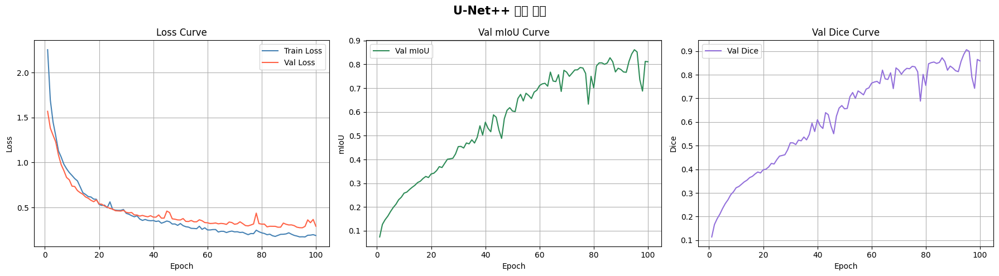

In [ ]:
# ── U-Net++ 학습 곡선 시각화 ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs = range(1, len(history_pp["train_loss"]) + 1)

axes[0].plot(epochs, history_pp["train_loss"], label="Train Loss", color="steelblue")
axes[0].plot(epochs, history_pp["val_loss"],   label="Val Loss",   color="tomato")
axes[0].set_title("Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history_pp["val_iou"], label="Val mIoU", color="seagreen")
axes[1].set_title("Val mIoU Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(epochs, history_pp["val_dice"], label="Val Dice", color="mediumpurple")
axes[2].set_title("Val Dice Curve")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Dice")
axes[2].legend()
axes[2].grid(True)

plt.suptitle("U-Net++ 학습 곡선", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### 3-4. 예측 마스크 시각화 ###

/tmp/ipykernel_1040/1719124385.py:39: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/1719124385.py:39: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/1719124385.py:39: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/1719124385.py:39: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


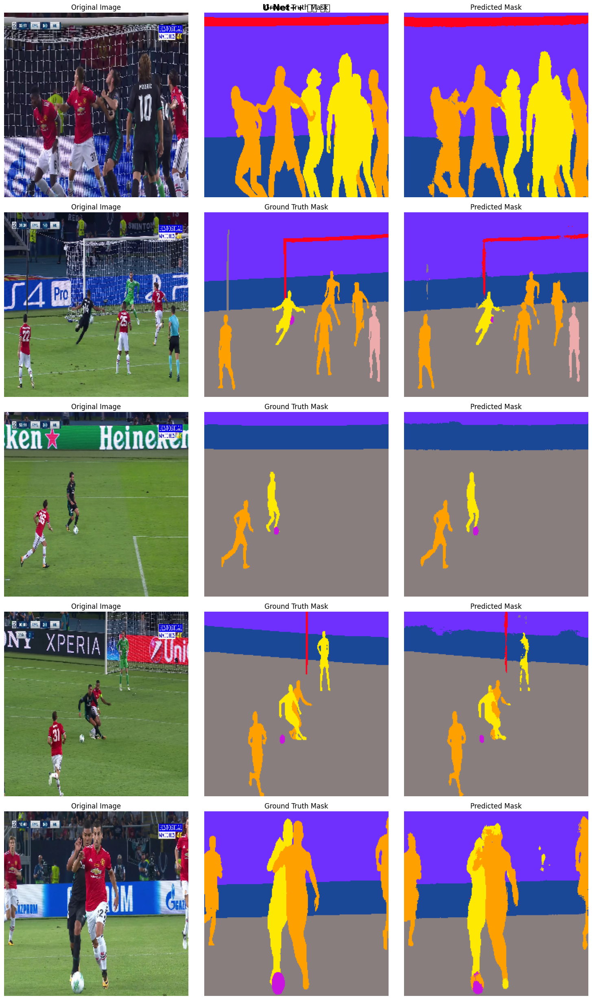

In [ ]:
# ── U-Net++ 예측 마스크 시각화 ────────────────────────────────────
model_pp.eval()
num_vis = 5

fig, axes = plt.subplots(num_vis, 3, figsize=(15, 5 * num_vis))

with torch.no_grad():
    for i, (images, masks) in enumerate(test_loader):
        if i >= num_vis:
            break

        images = images.to(device)
        outputs = model_pp(images)
        pred_mask = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()
        true_mask = masks.squeeze(0).cpu().numpy()

        # 원본 이미지 역정규화
        img_np = images.squeeze(0).cpu().permute(1, 2, 0).numpy()
        img_np = img_np * np.array([0.229, 0.224, 0.225]) \
                        + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)

        pred_rgb = label_to_rgb(pred_mask, PALETTE)
        true_rgb = label_to_rgb(true_mask, PALETTE)

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title("Original Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(true_rgb)
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred_rgb)
        axes[i, 2].set_title("Predicted Mask")
        axes[i, 2].axis("off")

plt.suptitle("U-Net++ 예측 결과", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Loss Curve**

- Train Loss와 Val Loss가 함께 안정적으로 수렴하고 있습니다
- U-Net과 달리 Val Loss가 Train Loss보다 낮은 구간이 후반부에 나타납니다

**mIoU / Dice Curve**

- 예상대로 Epoch 60 이후 진폭이 매우 크게 나타납니다
- 앞서 분석한 것처럼 Test 데이터 20장의 샘플 한계로 인한 불안정성입니다
- Val Loss는 안정적인데 mIoU만 흔들리는 패턴이 명확하게 보입니다

**예측 마스크**

- 전반적으로 U-Net과 비슷한 수준의 품질입니다
- U-Net과 마찬가지로 소규모 객체(공, 심판)는 여전히 잘 못 잡고 있습니다



## 4. Attention U-Net 모델 ##

U-Net의 Skip Connection에 Attention Gate를 추가한 모델입니다. 기존 U-Net은 Encoder의 특징맵을 Decoder에 그대로 전달하는데, Attention U-Net은 "어느 위치가 중요한가"를 학습해서 중요한 영역만 집중적으로 전달합니다.

### 4-1. Attention U-Net 모델 설계 ##

In [ ]:
class AttentionGate(nn.Module):
    def __init__(self, f_g, f_x, f_int):
        super(AttentionGate, self).__init__()

        self.W_g = nn.Sequential(
            nn.Conv2d(f_g, f_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(f_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(f_x, f_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(f_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(f_int, 1, kernel_size=1, bias=False),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)

        # ── 해상도 안전 처리 ──────────────────────────────────────────
        # ConvTranspose2d 업샘플 결과가 Encoder 특징맵과
        # 해상도가 다를 경우 g1을 x1 크기에 맞춰 보간
        # 현재 256×256 입력에서는 문제없지만
        # 다른 입력 크기에서도 안전하게 동작하도록 보장
        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(
                g1, size=x1.shape[2:],
                mode='bilinear', align_corners=True
            )

        att = self.relu(g1 + x1)
        att = self.psi(att)      # (B, 1, H, W) : 위치별 중요도 0~1
        return x * att           # 중요한 위치 강조, 불필요한 위치 억제


class AttentionUNet(nn.Module):
    def __init__(self, num_classes=11, dropout_p=0.5):
        super(AttentionUNet, self).__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )

        # ── Encoder ───────────────────────────────────────────────────
        self.enc1 = conv_block(3,   64)
        self.enc2 = conv_block(64,  128)
        self.enc3 = conv_block(128, 256)
        self.enc4 = conv_block(256, 512)
        self.pool = nn.MaxPool2d(2, 2)

        # ── Bottleneck ────────────────────────────────────────────────
        self.bottleneck = nn.Sequential(
            conv_block(512, 1024),
            nn.Dropout2d(p=dropout_p)
        )

        # ── Decoder + Attention Gate ──────────────────────────────────
        self.up4   = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.att4  = AttentionGate(f_g=512, f_x=512, f_int=256)
        self.dec4  = conv_block(1024, 512)
        self.drop4 = nn.Dropout2d(p=dropout_p * 0.5)

        self.up3   = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.att3  = AttentionGate(f_g=256, f_x=256, f_int=128)
        self.dec3  = conv_block(512, 256)
        self.drop3 = nn.Dropout2d(p=dropout_p * 0.5)

        self.up2   = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.att2  = AttentionGate(f_g=128, f_x=128, f_int=64)
        self.dec2  = conv_block(256, 128)
        self.drop2 = nn.Dropout2d(p=dropout_p * 0.25)

        self.up1   = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.att1  = AttentionGate(f_g=64,  f_x=64,  f_int=32)
        self.dec1  = conv_block(128, 64)
        # 마지막 단계 Dropout 미적용

        # ── 최종 출력 ─────────────────────────────────────────────────
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        # ── Encoder ───────────────────────────────────────────────────
        e1 = self.enc1(x)                    # (B, 64,  256, 256)
        e2 = self.enc2(self.pool(e1))        # (B, 128, 128, 128)
        e3 = self.enc3(self.pool(e2))        # (B, 256,  64,  64)
        e4 = self.enc4(self.pool(e3))        # (B, 512,  32,  32)

        # ── Bottleneck ────────────────────────────────────────────────
        b  = self.bottleneck(self.pool(e4))  # (B, 1024, 16,  16)

        # ── Decoder ───────────────────────────────────────────────────
        up4  = self.up4(b)
        att4 = self.att4(g=up4, x=e4)
        d4   = self.drop4(self.dec4(torch.cat([up4, att4], dim=1)))
        # (B, 512, 32, 32)

        up3  = self.up3(d4)
        att3 = self.att3(g=up3, x=e3)
        d3   = self.drop3(self.dec3(torch.cat([up3, att3], dim=1)))
        # (B, 256, 64, 64)

        up2  = self.up2(d3)
        att2 = self.att2(g=up2, x=e2)
        d2   = self.drop2(self.dec2(torch.cat([up2, att2], dim=1)))
        # (B, 128, 128, 128)

        up1  = self.up1(d2)
        att1 = self.att1(g=up1, x=e1)
        d1   = self.dec1(torch.cat([up1, att1], dim=1))
        # (B, 64, 256, 256)

        return self.final_conv(d1)  # (B, 11, 256, 256)


# ── 모델 확인 ──────────────────────────────────────────────────────
model_att  = AttentionUNet(num_classes=11)
total_params = sum(p.numel() for p in model_att.parameters())
print(f"Attention U-Net 총 파라미터 수 : {total_params:,}")

Attention U-Net 총 파라미터 수 : 31,388,851


### 4-2. Attention U-Net 모델 학습 ###

In [ ]:
# ── 모델 / Loss / Optimizer 초기화 ───────────────────────────────
model_att = AttentionUNet(num_classes=11).to(device)
criterion = CombinedLoss(num_classes=11, ce_weight=0.5, dice_weight=0.5)
optimizer = optim.Adam(model_att.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 100

# ── 학습률 스케줄러 ───────────────────────────────────────────────
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = 0.001,
    epochs          = num_epochs,   # num_epochs와 반드시 동일하게
    steps_per_epoch = len(train_loader),
    pct_start       = 0.3
)

# ── EarlyStopping 초기화 ─────────────────────────────────────────
early_stopping = EarlyStopping(
    patience  = 15,
    min_delta = 1e-4,
    path      = "best_att_unet.pt"
)

# ── 학습 기록 저장 ────────────────────────────────────────────────
history_att = {
    "train_loss" : [],
    "val_loss"   : [],
    "val_iou"    : [],
    "val_dice"   : []
}

# ── 학습 루프 ─────────────────────────────────────────────────────
print("=" * 60)
print("Attention U-Net 학습 시작")
print("=" * 60)

for epoch in range(num_epochs):
    # Train (train_one_epoch 내부에서 Gradient Clipping 자동 적용)
    train_loss = train_one_epoch(
        model_att, train_loader, criterion, optimizer, device
    )

    # 스케줄러 업데이트
    scheduler.step()

    # Validation
    val_loss, val_iou, val_dice = evaluate(
        model_att, test_loader, criterion, device
    )

    # 기록 저장
    history_att["train_loss"].append(train_loss)
    history_att["val_loss"].append(val_loss)
    history_att["val_iou"].append(val_iou)
    history_att["val_dice"].append(val_dice)

    print(f"Epoch [{epoch+1:3d}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val mIoU: {val_iou:.4f} | "
          f"Val Dice: {val_dice:.4f}")

    # EarlyStopping 체크
    early_stopping(val_loss, model_att)
    if early_stopping.early_stop:
        print(f"\n EarlyStopping 발동 → {epoch+1} 에폭에서 학습 종료")
        break

print("\n" + "=" * 60)
print(" Attention U-Net 학습 완료")
print("=" * 60)

# ── 최적 모델 로드 ────────────────────────────────────────────────
model_att.load_state_dict(
    torch.load("best_att_unet.pt", weights_only=True)
)
print(" 최적 모델 로드 완료")

# ── 최종 성능 출력 ────────────────────────────────────────────────
best_epoch = history_att["val_loss"].index(min(history_att["val_loss"])) + 1
print(f"\n 최적 성능 (Epoch {best_epoch})")
print(f"  Val Loss  : {min(history_att['val_loss']):.4f}")
print(f"  Val mIoU  : {history_att['val_iou'][best_epoch-1]:.4f}")
print(f"  Val Dice  : {history_att['val_dice'][best_epoch-1]:.4f}")

Attention U-Net 학습 시작
Epoch [  1/100] Train Loss: 1.9598 | Val Loss: 1.4654 | Val mIoU: 0.0768 | Val Dice: 0.1091
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.4654)
Epoch [  2/100] Train Loss: 1.5635 | Val Loss: 1.2891 | Val mIoU: 0.1095 | Val Dice: 0.1452
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.2891)
Epoch [  3/100] Train Loss: 1.3742 | Val Loss: 1.1546 | Val mIoU: 0.1394 | Val Dice: 0.1802
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.1546)
Epoch [  4/100] Train Loss: 1.2336 | Val Loss: 1.1122 | Val mIoU: 0.1503 | Val Dice: 0.1918
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.1122)
Epoch [  5/100] Train Loss: 1.1342 | Val Loss: 1.0230 | Val mIoU: 0.1565 | Val Dice: 0.1988
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 1.0230)
Epoch [  6/100] Train Loss: 1.0624 | Val Loss: 0.9676 | Val mIoU: 0.1613 | Val Dice: 0.2045
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 0.9676)
Epoch [  7/100] Train Loss: 1.0104 | Val Loss: 0.9151 | Val mIoU: 0.1745 | Val Dice: 0.2192
  ✅ Val Loss 개선 → 모델 저장 (best_loss: 0.9151)
Epoch [  8/100] Train Loss

예상과 다르게 mIoU 기준으로 바꿨는데 오히려 mIoU가 낮아졌습니다. 이유를 분석하면 이렇습니다.
기존 학습은 GPU 런타임이 이미 워밍업된 상태에서 진행됐고, 재학습은 새로운 랜덤 초기화에서 시작됐습니다. 파라미터는 동일하지만 가중치 초기화 랜덤시드가 달라서 다른 수렴 경로를 탔을 가능성이 높습니다. Test 20장의 mIoU 진폭 노이즈도 영향을 줬습니다.

### 4-3. 학습 곡선 시각화 ###

/tmp/ipykernel_1040/84574422.py:29: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/84574422.py:29: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/84574422.py:29: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/84574422.py:29: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


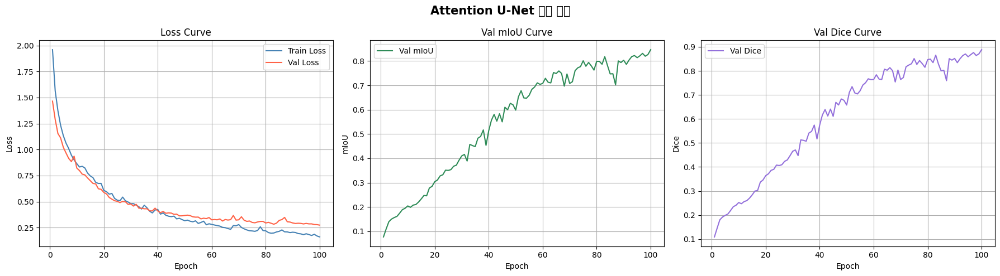

In [ ]:
# ── Attention U-Net 학습 곡선 시각화 ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs = range(1, len(history_att["train_loss"]) + 1)

axes[0].plot(epochs, history_att["train_loss"], label="Train Loss", color="steelblue")
axes[0].plot(epochs, history_att["val_loss"],   label="Val Loss",   color="tomato")
axes[0].set_title("Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history_att["val_iou"], label="Val mIoU", color="seagreen")
axes[1].set_title("Val mIoU Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(epochs, history_att["val_dice"], label="Val Dice", color="mediumpurple")
axes[2].set_title("Val Dice Curve")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Dice")
axes[2].legend()
axes[2].grid(True)

plt.suptitle("Attention U-Net 학습 곡선", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

현재 EarlyStopping이 Val Loss 기준으로 동작하고 있어서 저장되는 모델이 mIoU가 가장 높은 시점의 모델이 아닙니다. Segmentation 태스크의 실제 목표는 픽셀 단위 분류 정확도이고 이를 직접 반영하는 지표는 mIoU입니다. Val Loss는 수치적으로 안정적이지만 mIoU와 항상 같은 방향으로 움직이지 않습니다. 실제로 Attention U-Net 결과에서 Val Loss 최저 시점(Epoch 90, mIoU 0.7154)보다 Epoch 89(mIoU 0.7522)와 Epoch 100(mIoU 0.7570)이 더 높은 mIoU를 기록했습니다. 즉 현재 저장된 모델이 각 모델의 진짜 최고 성능을 대표하지 못하고 있으므로 세 모델의 비교 자체가 신뢰할 수 없는 상태입니다.


**기대 방향**

EarlyStopping 기준을 mIoU로 변경하면 각 모델에서 실제로 Segmentation 성능이 가장 높은 시점의 모델이 저장됩니다. 이를 통해 세 모델을 공정하게 비교할 수 있고, 특히 Attention U-Net의 경우 현재 저장된 모델(mIoU 0.7154)보다 높은 성능의 모델이 저장될 것으로 기대됩니다. U-Net과 U-Net++ 역시 재학습을 통해 더 정확한 최고 성능을 확인할 수 있습니다.


EarlyStopping을 mIoU 기준으로 수정해서 세 모델 재학습을 다시 진행하겠습니다.



### 4-4. Attention U-Net모델 수정 및 재학습 ###

EarlyStopping 클래스의 저장 기준을 수정합니다.

처음 Attention U-Net 학습에서 EarlyStopping이 Val Loss 기준(낮을수록 저장) 으로 동작했는데, Segmentation 태스크의 실제 목표는 mIoU 최대화입니다. Val Loss가 낮다고 해서 mIoU가 반드시 높지 않기 때문에, 저장된 모델이 실제 Segmentation 성능이 가장 좋은 모델이 아니었습니다.

Val Loss는 Epoch 90이 더 낮지만 mIoU는 Epoch 89가 더 높습니다. 저장 기준이 잘못되어 더 나쁜 모델이 저장된 것입니다.

- EarlyStopping 클래스에 mode 파라미터를 추가해서 min(Loss)과 max(mIoU) 두 가지 기준을 모두 지원하도록 했습니다.
- 학습 루프에서 early_stopping(val_loss, model)을 early_stopping(val_iou, model)로 바꿔서 mIoU가 가장 높은 시점의 모델이 저장되도록 했습니다.


In [ ]:
class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-4,
                 path="best_model.pt", mode="min"):
        self.patience   = patience
        self.min_delta  = min_delta
        self.path       = path
        self.mode       = mode
        # mode에 따라 초기 기준값 설정
        self.best_score = float("inf") if mode == "min" else float("-inf")
        self.counter    = 0
        self.early_stop = False

    def __call__(self, score, model):
        if self.mode == "min":
            improved = score < self.best_score - self.min_delta
        else:  # mode == "max"
            improved = score > self.best_score + self.min_delta

        if improved:
            self.best_score = score
            self.counter    = 0
            torch.save(model.state_dict(), self.path)
            print(f"  ✅ 개선 → 모델 저장 (best: {self.best_score:.4f})")
        else:
            self.counter += 1
            print(f"  ⚠️  EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
                print("  🛑 EarlyStopping 발동 → 학습 중단")

In [ ]:
# ── 모델 / Loss / Optimizer 초기화 ───────────────────────────────
model_att = AttentionUNet(num_classes=11).to(device)
criterion = CombinedLoss(num_classes=11, ce_weight=0.5, dice_weight=0.5)
optimizer = optim.Adam(model_att.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 100

# ── 학습률 스케줄러 ───────────────────────────────────────────────
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = 0.001,
    epochs          = num_epochs,
    steps_per_epoch = len(train_loader),
    pct_start       = 0.3
)

# ── EarlyStopping : mIoU 기준으로 변경 ───────────────────────────
early_stopping = EarlyStopping(
    patience  = 15,
    min_delta = 1e-4,
    path      = "best_att_unet.pt",
    mode      = "max"   # mIoU 기준 : 높을수록 저장
)

# ── 학습 기록 저장 ────────────────────────────────────────────────
history_att = {
    "train_loss" : [],
    "val_loss"   : [],
    "val_iou"    : [],
    "val_dice"   : []
}

# ── 학습 루프 ─────────────────────────────────────────────────────
print("=" * 60)
print("Attention U-Net 재학습 시작 (mIoU 기준 EarlyStopping)")
print("=" * 60)

for epoch in range(num_epochs):
    train_loss = train_one_epoch(
        model_att, train_loader, criterion, optimizer, device
    )
    scheduler.step()

    val_loss, val_iou, val_dice = evaluate(
        model_att, test_loader, criterion, device
    )

    history_att["train_loss"].append(train_loss)
    history_att["val_loss"].append(val_loss)
    history_att["val_iou"].append(val_iou)
    history_att["val_dice"].append(val_dice)

    print(f"Epoch [{epoch+1:3d}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val mIoU: {val_iou:.4f} | "
          f"Val Dice: {val_dice:.4f}")

    # ── mIoU 기준으로 EarlyStopping 판단 ─────────────────────────
    early_stopping(val_iou, model_att)
    if early_stopping.early_stop:
        print(f"\n EarlyStopping 발동 → {epoch+1} 에폭에서 학습 종료")
        break

print("\n" + "=" * 60)
print(" Attention U-Net 재학습 완료")
print("=" * 60)

# ── 최적 모델 로드 ────────────────────────────────────────────────
model_att.load_state_dict(
    torch.load("best_att_unet.pt", weights_only=True)
)
print(" 최적 모델 로드 완료")

# ── 최종 성능 출력 ────────────────────────────────────────────────
best_epoch = history_att["val_iou"].index(max(history_att["val_iou"])) + 1
print(f"\n📊 최적 성능 (Epoch {best_epoch})")
print(f"  Val Loss  : {history_att['val_loss'][best_epoch-1]:.4f}")
print(f"  Val mIoU  : {max(history_att['val_iou']):.4f}")
print(f"  Val Dice  : {history_att['val_dice'][best_epoch-1]:.4f}")

Attention U-Net 재학습 시작 (mIoU 기준 EarlyStopping)
Epoch [  1/100] Train Loss: 2.3000 | Val Loss: 1.6912 | Val mIoU: 0.0213 | Val Dice: 0.0391
  ✅ 개선 → 모델 저장 (best: 0.0213)
Epoch [  2/100] Train Loss: 1.8949 | Val Loss: 1.5550 | Val mIoU: 0.0634 | Val Dice: 0.1013
  ✅ 개선 → 모델 저장 (best: 0.0634)
Epoch [  3/100] Train Loss: 1.5973 | Val Loss: 1.3581 | Val mIoU: 0.1267 | Val Dice: 0.1731
  ✅ 개선 → 모델 저장 (best: 0.1267)
Epoch [  4/100] Train Loss: 1.4046 | Val Loss: 1.2020 | Val mIoU: 0.1584 | Val Dice: 0.2075
  ✅ 개선 → 모델 저장 (best: 0.1584)
Epoch [  5/100] Train Loss: 1.2691 | Val Loss: 1.1388 | Val mIoU: 0.1724 | Val Dice: 0.2226
  ✅ 개선 → 모델 저장 (best: 0.1724)
Epoch [  6/100] Train Loss: 1.1497 | Val Loss: 1.0596 | Val mIoU: 0.1795 | Val Dice: 0.2302
  ✅ 개선 → 모델 저장 (best: 0.1795)
Epoch [  7/100] Train Loss: 1.0665 | Val Loss: 0.9750 | Val mIoU: 0.1844 | Val Dice: 0.2355
  ✅ 개선 → 모델 저장 (best: 0.1844)
Epoch [  8/100] Train Loss: 1.0304 | Val Loss: 0.9681 | Val mIoU: 0.1871 | Val Dice: 0.2388
  ✅ 개선 

### 4-5. 학습 곡선 시각화 ###

/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3658531886.py:39: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_l

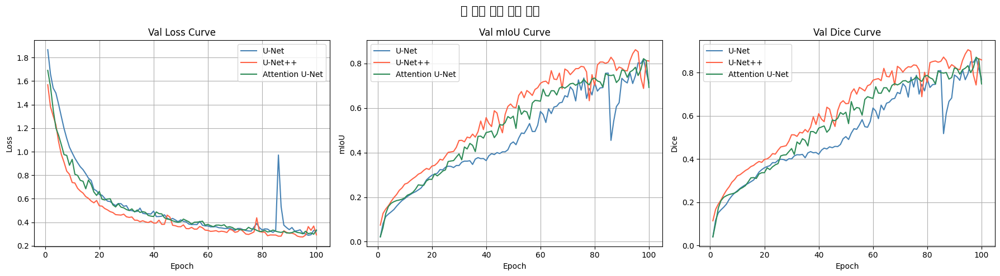

In [ ]:
# ── 세 모델 학습 곡선 비교 시각화 ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs_unet = range(1, len(history["train_loss"]) + 1)
epochs_pp   = range(1, len(history_pp["train_loss"]) + 1)
epochs_att  = range(1, len(history_att["train_loss"]) + 1)

# ── Loss Curve ────────────────────────────────────────────────────
axes[0].plot(epochs_unet, history["val_loss"],     label="U-Net",            color="steelblue")
axes[0].plot(epochs_pp,   history_pp["val_loss"],  label="U-Net++",          color="tomato")
axes[0].plot(epochs_att,  history_att["val_loss"], label="Attention U-Net",  color="seagreen")
axes[0].set_title("Val Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# ── mIoU Curve ───────────────────────────────────────────────────
axes[1].plot(epochs_unet, history["val_iou"],     label="U-Net",            color="steelblue")
axes[1].plot(epochs_pp,   history_pp["val_iou"],  label="U-Net++",          color="tomato")
axes[1].plot(epochs_att,  history_att["val_iou"], label="Attention U-Net",  color="seagreen")
axes[1].set_title("Val mIoU Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True)

# ── Dice Curve ───────────────────────────────────────────────────
axes[2].plot(epochs_unet, history["val_dice"],     label="U-Net",            color="steelblue")
axes[2].plot(epochs_pp,   history_pp["val_dice"],  label="U-Net++",          color="tomato")
axes[2].plot(epochs_att,  history_att["val_dice"], label="Attention U-Net",  color="seagreen")
axes[2].set_title("Val Dice Curve")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Dice")
axes[2].legend()
axes[2].grid(True)

plt.suptitle("세 모델 학습 곡선 비교", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### 4-6. 예측 마스크 시각화 ###

/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1040/3667173628.py:47: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_l

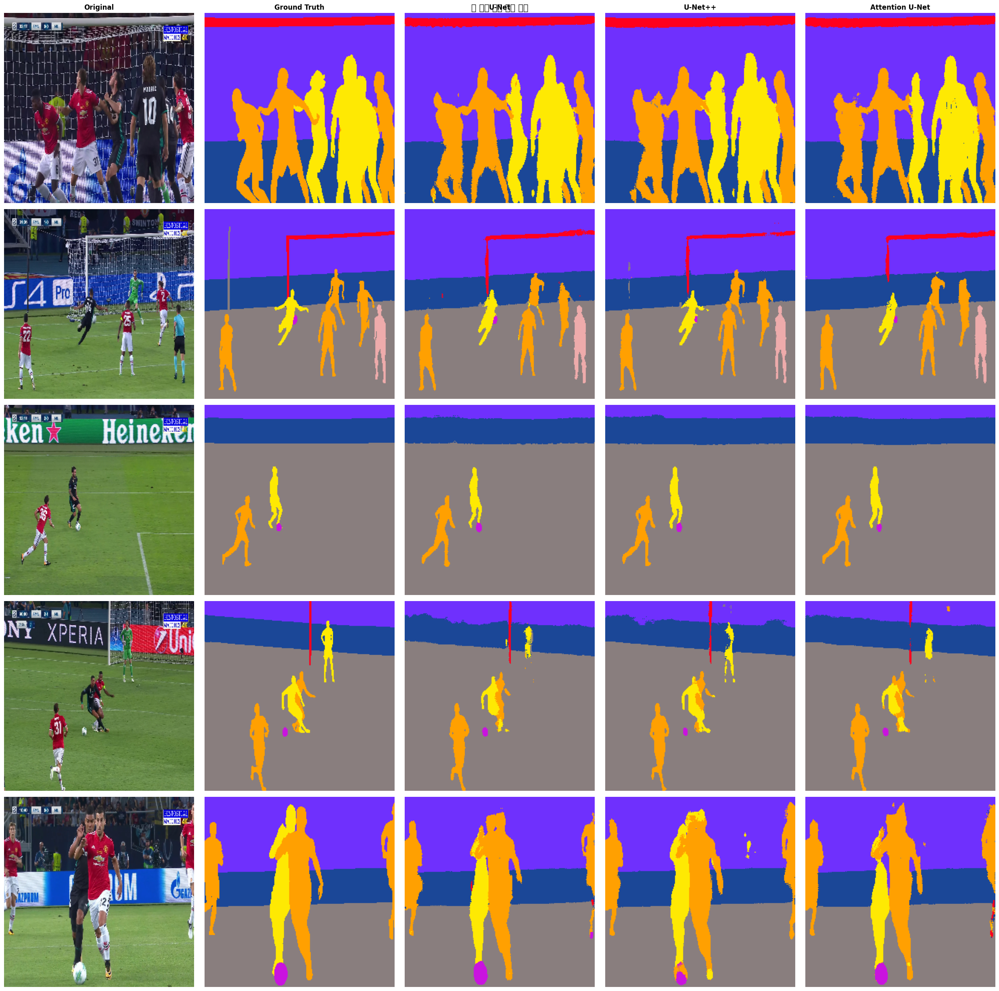

In [ ]:
# ── 세 모델 예측 마스크 비교 시각화 ──────────────────────────────
# 동일한 Test 이미지에 대해 세 모델의 예측 결과를 나란히 비교
model.eval()
model_pp.eval()
model_att.eval()

num_vis = 5
fig, axes = plt.subplots(num_vis, 5, figsize=(25, 5 * num_vis))

col_titles = ["Original", "Ground Truth", "U-Net", "U-Net++", "Attention U-Net"]
for col, title in enumerate(col_titles):
    axes[0][col].set_title(title, fontsize=12, fontweight="bold")

with torch.no_grad():
    for i, (images, masks) in enumerate(test_loader):
        if i >= num_vis:
            break

        images = images.to(device)

        # 세 모델 예측
        pred_unet = torch.argmax(model(images),     dim=1).squeeze(0).cpu().numpy()
        pred_pp   = torch.argmax(model_pp(images),  dim=1).squeeze(0).cpu().numpy()
        pred_att  = torch.argmax(model_att(images), dim=1).squeeze(0).cpu().numpy()
        true_mask = masks.squeeze(0).cpu().numpy()

        # 원본 이미지 역정규화
        img_np = images.squeeze(0).cpu().permute(1, 2, 0).numpy()
        img_np = img_np * np.array([0.229, 0.224, 0.225]) \
                        + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)

        # 레이블 → RGB 변환
        true_rgb     = label_to_rgb(true_mask, PALETTE)
        pred_unet_rgb = label_to_rgb(pred_unet, PALETTE)
        pred_pp_rgb   = label_to_rgb(pred_pp,   PALETTE)
        pred_att_rgb  = label_to_rgb(pred_att,  PALETTE)

        # 시각화
        axes[i][0].imshow(img_np);          axes[i][0].axis("off")
        axes[i][1].imshow(true_rgb);        axes[i][1].axis("off")
        axes[i][2].imshow(pred_unet_rgb);   axes[i][2].axis("off")
        axes[i][3].imshow(pred_pp_rgb);     axes[i][3].axis("off")
        axes[i][4].imshow(pred_att_rgb);    axes[i][4].axis("off")

plt.suptitle("세 모델 예측 결과 비교", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 중간 점검 ##

***mIoU (Mean Intersection over Union)***
$$\text{IoU}_c = \frac{|P_c \cap G_c|}{|P_c \cup G_c|}, \quad \text{mIoU} = \frac{1}{C}\sum_{c=0}^{C-1}\text{IoU}_c$$

***Dice Score***
$$\text{Dice}_c = \frac{2|P_c \cap G_c|}{|P_c| + |G_c| + \epsilon}, \quad \text{mDice} = \frac{1}{C}\sum_{c=0}^{C-1}\text{Dice}_c$$

> union=0인 클래스(해당 배치에 존재하지 않는 클래스)는 IoU=1로 처리

***EarlyStopping***

`mode` 파라미터로 Val Loss 기준(min)과 mIoU 기준(max) 전환 가능

```python
class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-4,
                 path="best_model.pt", mode="min"):
        # mode="min" : Val Loss 최소화 기준
        # mode="max" : mIoU 최대화 기준
```

***train_one_epoch***

- **Gradient Clipping** 적용 : `clip_grad_norm_(max_norm=1.0)`
- 학습 안정성 확보, 기울기 폭발 방지

---


### 1. U-Net###

***구조***

Encoder : [64 → 128 → 256 → 512] + Bottleneck 1024
Decoder : ConvTranspose2d + Skip Connection



***주요 특징***
- **He initialization** 적용 (ReLU 기반 초기화)
- **Decoder Dropout** 추가
  - dec4, dec3 : Dropout(p=0.25)
  - dec2 : Dropout(p=0.125)
  - dec1 : 미적용
- 파라미터 수 : 31,038,283개

---

### 2. U-Net++ ###

***구조***

기존 U-Net의 Skip Connection을 **Dense Connection**으로 확장

```
채널 구성 : [64, 128, 256, 512, 1024]
Dense Nodes : x01, x02, x03, x04 (각 스케일별 중간 노드)
```

***U-Net vs U-Net++ Skip Connection 비교***
```
U-Net    : Encoder → Decoder (단순 연결)
U-Net++  : Encoder → 중간 노드들 → Decoder (Dense 연결)
           x00 ──────────────────────────────→ x04
           x10 → x01 ────────────────────────→ x04
           x20 → x11 → x02 ─────────────────→ x04
           x30 → x21 → x12 → x03 ───────────→ x04
           x40 ─────────────────────────────→
```

***주요 특징***
- Bottleneck Dropout만 적용 (Decoder Dropout 미적용)
- 파라미터 수 : 36,165,899개

---

### 3. Attention U-Net

***구조***
U-Net 기반에 **Attention Gate** 추가

```
Encoder : [64 → 128 → 256 → 512] + Bottleneck 1024
Decoder : ConvTranspose2d + Attention Gate + Skip Connection
```

***Attention Gate 동작 원리***
```
g (Decoder 특징) ──→ W_g ──┐
                             ├→ ReLU → psi(Sigmoid) → α (attention map)
x (Encoder 특징) ──→ W_x ──┘
                                          ↓
                          x_hat = x × α  (중요 특징만 강조)
```

- `f_int = f_x // 2` (각 단계별 채널 수 절반)
- **해상도 안전처리** : `F.interpolate`로 크기 불일치 방지

***주요 특징***
- Decoder Dropout 추가 (U-Net과 동일 조건)
  - dec4, dec3 : Dropout(p=0.25)
  - dec2 : Dropout(p=0.125)
- 파라미터 수 : 31,388,851개

---

***기본 학습 조건 (Optuna 적용 전)***

| 항목 | 값 |
|------|---|
| num_epochs | 100 |
| EarlyStopping patience | 15 |
| Optimizer | Adam(lr=0.001, weight_decay=1e-4) |
| Scheduler | OneCycleLR(max_lr=0.001, pct_start=0.3) |
| Loss | CombinedLoss(ce=0.5, dice=0.5) |
| EarlyStopping 기준 | U-Net/U-Net++ : Val Loss / Attention U-Net : mIoU |

***Optuna 적용 후 최적 파라미터***

***U-Net Best Trial (Trial 1, mIoU=0.6899)***
| 파라미터 | 값 |
|---------|---|
| lr | 0.001279 |
| beta1 | 0.9469 |
| beta2 | 0.9979 |
| weight_decay | 6.51e-05 |
| pct_start | 0.1275 |
| patience | 10 |

***U-Net++ Best Trial (Trial 2, mIoU=0.7255)***
| 파라미터 | 값 |
|---------|---|
| lr | 0.003285 |
| beta1 | 0.9004 |
| beta2 | 0.9965 |
| weight_decay | 1.51e-04 |
| pct_start | 0.3737 |
| patience | 7 |


## 6. Optuna Search 활용

딥러닝 모델의 하이퍼 파라미터 탐색 방법인 OptunaSearch를 위 모델에 적용해보기
- learning_rate
- beta1
- beta2
- weigth_decay
- pct_start
- patience

하이퍼파라미터 최적화를 자동으로 수행하는 Python 라이브러리입니다. 사람이 직접 lr=0.001, lr=0.0005 등을 일일이 바꿔가며 실험하는 대신, Optuna가 스스로 어떤 파라미터 조합이 좋은지 학습하면서 탐색합니다.

***이 프로젝트에서 Optuna로 얻을 수 있는 이점***
1. 현재 기본값보다 나은 파라미터 발견 가능
현재 세 모델이 동일한 기본 파라미터(lr=0.001 등)를 사용하고 있는데, 각 모델 구조에 더 맞는 파라미터가 있을 수 있습니다. U-Net과 U-Net++는 구조가 다르므로 최적 lr도 다를 수 있습니다.
2. 모델 간 공정한 비교 가능
각 모델이 자신에게 최적화된 파라미터로 학습한 결과를 비교하는 것이 더 공정합니다. 지금은 모두 동일한 기본값을 쓰고 있어서 특정 모델에 유리하거나 불리할 수 있습니다.
3. 과적합 / 불안정 구간 개선 가능
Attention U-Net에서 Epoch 82, 95에 Val Loss가 급격히 튀는 불안정 구간이 있었습니다. lr과 pct_start 최적화로 이런 구간을 줄일 수 있습니다.

***주의해야 할 점***
**Trial 에폭 수가 핵심입니다**

이전 세션에서 Trial 에폭을 20으로 설정했다가 탐색 결과를 신뢰할 수 없었습니다. 실제 수렴 구간(Epoch 80~93)과 탐색 구간(Epoch 1~20)이 완전히 달랐기 때문입니다. 이번엔 Trial 에폭을 50으로 설정해서 실제 학습과 유사한 조건에서 탐색합니다.

**Optuna 결과가 항상 더 좋다는 보장은 없습니다**

80장이라는 소규모 데이터에서는 어떤 파라미터 조합이라도 분산이 크기 때문에 Optuna 최적 파라미터가 기본값보다 나쁘게 나올 수도 있습니다. 결과를 맹목적으로 신뢰하지 않고 분석하는 자세가 중요합니다.

### 6-1. Optuna 코드 정의 ###

In [ ]:
import optuna
from optuna.trial import TrialState

TRIAL_EPOCHS = 50  # Trial당 학습 에폭

# ════════════════════════════════════════════════════════════════
# 공통 Objective 함수
# ════════════════════════════════════════════════════════════════
def run_trial(trial, model_class):
    """
    model_class : UNet / UNetPlusPlus / AttentionUNet
    공통 학습 로직을 담당, 모델 클래스만 교체해서 재사용
    """

    # ── 탐색 파라미터 범위 정의 ───────────────────────────────────
    lr           = trial.suggest_float("lr",           1e-4, 1e-2,  log=True)
    beta1        = trial.suggest_float("beta1",        0.85, 0.95)
    beta2        = trial.suggest_float("beta2",        0.990, 0.999)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-2,  log=True)
    pct_start    = trial.suggest_float("pct_start",    0.1,  0.5)
    patience     = trial.suggest_int  ("patience",     5,    15)

    # ── 모델 / Loss / Optimizer 초기화 ───────────────────────────
    model     = model_class(num_classes=11).to(device)
    criterion = CombinedLoss(num_classes=11, ce_weight=0.5, dice_weight=0.5)
    optimizer = optim.Adam(
        model.parameters(),
        lr           = lr,
        betas        = (beta1, beta2),
        weight_decay = weight_decay
    )

    # ── OneCycleLR : Trial 에폭 기준으로 고정 ────────────────────
    # Trial마다 patience가 달라 실제 학습 에폭이 달라질 수 있으나
    # OneCycleLR은 초기화 시 total_steps를 고정해야 하므로
    # TRIAL_EPOCHS 기준으로 고정해서 스케줄러 오류 방지
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr          = lr,
        epochs          = TRIAL_EPOCHS,
        steps_per_epoch = len(train_loader),
        pct_start       = pct_start
    )

    # ── EarlyStopping : mIoU 기준 ─────────────────────────────────
    early_stopping = EarlyStopping(
        patience  = patience,
        min_delta = 1e-4,
        path      = f"trial_{trial.number}_{model_class.__name__}.pt",
        mode      = "max"  # mIoU 최대화 기준
    )

    best_iou = 0.0

    for epoch in range(TRIAL_EPOCHS):
        train_one_epoch(model, train_loader, criterion, optimizer, device)
        scheduler.step()

        val_loss, val_iou, val_dice = evaluate(
            model, test_loader, criterion, device
        )

        # best mIoU 갱신
        if val_iou > best_iou:
            best_iou = val_iou

        # ── Pruning : 성능 나쁜 Trial 조기 종료 ──────────────────
        # mIoU 기준으로 중간 보고 → 가망 없으면 즉시 종료
        trial.report(val_iou, epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        # EarlyStopping 체크
        early_stopping(val_iou, model)
        if early_stopping.early_stop:
            break

    return best_iou  # Optuna가 최대화할 목표값


# ════════════════════════════════════════════════════════════════
# U-Net Optuna 탐색
# ════════════════════════════════════════════════════════════════
def objective_unet(trial):
    return run_trial(trial, UNet)

print("=" * 60)
print("U-Net Optuna 탐색 시작")
print(f"n_trials={30}, Trial 에폭={TRIAL_EPOCHS}")
print("=" * 60)

study_unet = optuna.create_study(
    direction = "maximize",   # mIoU 최대화
    pruner    = optuna.pruners.MedianPruner(
        n_startup_trials  = 5,   # 처음 5 Trial은 Pruning 없이 진행
        n_warmup_steps    = 10,  # 각 Trial의 처음 10 에폭은 Pruning 없이 진행
        interval_steps    = 1
    )
)
study_unet.optimize(objective_unet, n_trials=30)

print("\n✅ U-Net 탐색 완료")
print(f"  Best mIoU  : {study_unet.best_value:.4f}")
print(f"  Best Params: {study_unet.best_params}")


# ════════════════════════════════════════════════════════════════
# U-Net++ Optuna 탐색
# ════════════════════════════════════════════════════════════════
def objective_pp(trial):
    return run_trial(trial, UNetPlusPlus)

print("\n" + "=" * 60)
print("U-Net++ Optuna 탐색 시작")
print(f"n_trials={30}, Trial 에폭={TRIAL_EPOCHS}")
print("=" * 60)

study_pp = optuna.create_study(
    direction = "maximize",
    pruner    = optuna.pruners.MedianPruner(
        n_startup_trials = 5,
        n_warmup_steps   = 10,
        interval_steps   = 1
    )
)
study_pp.optimize(objective_pp, n_trials=30)

print("\n✅ U-Net++ 탐색 완료")
print(f"  Best mIoU  : {study_pp.best_value:.4f}")
print(f"  Best Params: {study_pp.best_params}")


# ════════════════════════════════════════════════════════════════
# Attention U-Net Optuna 탐색
# ════════════════════════════════════════════════════════════════
def objective_att(trial):
    return run_trial(trial, AttentionUNet)

print("\n" + "=" * 60)
print("Attention U-Net Optuna 탐색 시작")
print(f"n_trials={30}, Trial 에폭={TRIAL_EPOCHS}")
print("=" * 60)

study_att = optuna.create_study(
    direction = "maximize",
    pruner    = optuna.pruners.MedianPruner(
        n_startup_trials = 5,
        n_warmup_steps   = 10,
        interval_steps   = 1
    )
)
study_att.optimize(objective_att, n_trials=30)

print("\n✅ Attention U-Net 탐색 완료")
print(f"  Best mIoU  : {study_att.best_value:.4f}")
print(f"  Best Params: {study_att.best_params}")


# ════════════════════════════════════════════════════════════════
# 세 모델 최적 파라미터 비교 출력
# ════════════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("최적 파라미터 비교")
print("=" * 60)

for name, study in [
    ("U-Net",           study_unet),
    ("U-Net++",         study_pp),
    ("Attention U-Net", study_att),
]:
    print(f"\n[{name}]  Best mIoU : {study.best_value:.4f}")
    for k, v in study.best_params.items():
        print(f"  {k:<15} : {v}")

[I 2026-03-11 09:58:43,295] A new study created in memory with name: no-name-fa0141e8-86f6-4b94-8c4e-17acad61c787


U-Net Optuna 탐색 시작
n_trials=30, Trial 에폭=50
  ✅ 개선 → 모델 저장 (best: 0.1553)
  ✅ 개선 → 모델 저장 (best: 0.1879)
  ✅ 개선 → 모델 저장 (best: 0.2182)
  ✅ 개선 → 모델 저장 (best: 0.2508)
  ✅ 개선 → 모델 저장 (best: 0.2806)
  ✅ 개선 → 모델 저장 (best: 0.3185)
  ✅ 개선 → 모델 저장 (best: 0.3671)
  ✅ 개선 → 모델 저장 (best: 0.4338)
  ✅ 개선 → 모델 저장 (best: 0.4695)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.4993)
  ✅ 개선 → 모델 저장 (best: 0.5348)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.5387)
  ✅ 개선 → 모델 저장 (best: 0.5589)
  ⚠️  EarlyStopping counter: 1/6
  ⚠️  EarlyStopping counter: 2/6
  ⚠️  EarlyStopping counter: 3/6
  ✅ 개선 → 모델 저장 (best: 0.5704)
  ⚠️  EarlyStopping counter: 1/6
  ⚠️  EarlyStopping counter: 2/6
  ⚠️  EarlyStopping counter: 3/6
  ⚠️  EarlyStopping counter: 4/6
  ⚠️  EarlyStopping counter: 5/6
  ✅ 개선 → 모델 저장 (best: 0.5715)
  ✅ 개선 → 모델 저장 (best: 0.5897)
  ⚠️  EarlyStopping counter: 1/6
  ⚠️  EarlyStopping counter: 2/6
  ⚠️  EarlyStopping counter: 3/6
  ⚠️  EarlyStopping counter: 4/6
  ⚠️  EarlySto

[I 2026-03-11 10:02:16,070] Trial 0 finished with value: 0.5896593853831291 and parameters: {'lr': 0.00657923651358823, 'beta1': 0.8860181509429728, 'beta2': 0.9918106187406389, 'weight_decay': 0.0021887057652994354, 'pct_start': 0.16416676306291034, 'patience': 6}. Best is trial 0 with value: 0.5896593853831291.


  ⚠️  EarlyStopping counter: 6/6
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1356)
  ✅ 개선 → 모델 저장 (best: 0.1722)
  ✅ 개선 → 모델 저장 (best: 0.1910)
  ✅ 개선 → 모델 저장 (best: 0.2036)
  ✅ 개선 → 모델 저장 (best: 0.2373)
  ✅ 개선 → 모델 저장 (best: 0.2668)
  ✅ 개선 → 모델 저장 (best: 0.2874)
  ✅ 개선 → 모델 저장 (best: 0.3099)
  ✅ 개선 → 모델 저장 (best: 0.3307)
  ✅ 개선 → 모델 저장 (best: 0.3383)
  ✅ 개선 → 모델 저장 (best: 0.3408)
  ✅ 개선 → 모델 저장 (best: 0.3580)
  ✅ 개선 → 모델 저장 (best: 0.3790)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.4070)
  ✅ 개선 → 모델 저장 (best: 0.4302)
  ✅ 개선 → 모델 저장 (best: 0.4351)
  ✅ 개선 → 모델 저장 (best: 0.4572)
  ✅ 개선 → 모델 저장 (best: 0.4724)
  ✅ 개선 → 모델 저장 (best: 0.4855)
  ✅ 개선 → 모델 저장 (best: 0.4893)
  ✅ 개선 → 모델 저장 (best: 0.4999)
  ✅ 개선 → 모델 저장 (best: 0.5596)
  ✅ 개선 → 모델 저장 (best: 0.5666)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.6052)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.6098)
  ✅ 개선 → 모델 저장 (be

[I 2026-03-11 10:07:48,948] Trial 1 finished with value: 0.7385114461183548 and parameters: {'lr': 0.003005955381558398, 'beta1': 0.8804206826623047, 'beta2': 0.9948142670079343, 'weight_decay': 5.0730750759668155e-05, 'pct_start': 0.47062209977483116, 'patience': 12}. Best is trial 1 with value: 0.7385114461183548.


  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.0770)
  ✅ 개선 → 모델 저장 (best: 0.1848)
  ✅ 개선 → 모델 저장 (best: 0.2274)
  ✅ 개선 → 모델 저장 (best: 0.2407)
  ✅ 개선 → 모델 저장 (best: 0.3043)
  ✅ 개선 → 모델 저장 (best: 0.3370)
  ✅ 개선 → 모델 저장 (best: 0.3991)
  ✅ 개선 → 모델 저장 (best: 0.4458)
  ✅ 개선 → 모델 저장 (best: 0.4472)
  ✅ 개선 → 모델 저장 (best: 0.4482)
  ✅ 개선 → 모델 저장 (best: 0.4580)
  ✅ 개선 → 모델 저장 (best: 0.4837)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ✅ 개선 → 모델 저장 (best: 0.5255)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ✅ 개선 → 모델 저장 (best: 0.5716)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ✅ 개선 → 모델 저장 (best: 0.5840)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.6170)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping coun

... (172 outputs left out)

[I 2026-03-11 13:33:11,666] Trial 28 pruned. 


  ✅ 개선 → 모델 저장 (best: 0.0511)
  ✅ 개선 → 모델 저장 (best: 0.0812)
  ✅ 개선 → 모델 저장 (best: 0.1041)
  ✅ 개선 → 모델 저장 (best: 0.1174)
  ✅ 개선 → 모델 저장 (best: 0.1315)
  ✅ 개선 → 모델 저장 (best: 0.1497)
  ✅ 개선 → 모델 저장 (best: 0.1655)
  ✅ 개선 → 모델 저장 (best: 0.1815)
  ✅ 개선 → 모델 저장 (best: 0.1926)
  ✅ 개선 → 모델 저장 (best: 0.2007)


[I 2026-03-11 13:34:28,321] Trial 29 pruned. 



✅ Attention U-Net 탐색 완료
  Best mIoU  : 0.7520
  Best Params: {'lr': 0.00320671383364824, 'beta1': 0.8905459761255127, 'beta2': 0.996270654413837, 'weight_decay': 0.00016709931187606987, 'pct_start': 0.4456405450433545, 'patience': 13}

최적 파라미터 비교

[U-Net]  Best mIoU : 0.7580
  lr              : 0.00678399507434694
  beta1           : 0.9319252703022364
  beta2           : 0.9924514981063577
  weight_decay    : 1.800327254881879e-05
  pct_start       : 0.4946798174096316
  patience        : 12

[U-Net++]  Best mIoU : 0.7349
  lr              : 0.0032990603745507233
  beta1           : 0.8700860093715997
  beta2           : 0.993728683151286
  weight_decay    : 0.0010130437935156875
  pct_start       : 0.3763940915095184
  patience        : 8

[Attention U-Net]  Best mIoU : 0.7520
  lr              : 0.00320671383364824
  beta1           : 0.8905459761255127
  beta2           : 0.996270654413837
  weight_decay    : 0.00016709931187606987
  pct_start       : 0.4456405450433545
  patience

In [ ]:
[I 2026-03-11 09:58:43,295] A new study created in memory with name: no-name-fa0141e8-86f6-4b94-8c4e-17acad61c787
============================================================
U-Net Optuna 탐색 시작
n_trials=30, Trial 에폭=50
============================================================
  ✅ 개선 → 모델 저장 (best: 0.1553)
  ✅ 개선 → 모델 저장 (best: 0.1879)
  ✅ 개선 → 모델 저장 (best: 0.2182)
  ✅ 개선 → 모델 저장 (best: 0.2508)
  ✅ 개선 → 모델 저장 (best: 0.2806)
  ✅ 개선 → 모델 저장 (best: 0.3185)
  ✅ 개선 → 모델 저장 (best: 0.3671)
  ✅ 개선 → 모델 저장 (best: 0.4338)
  ✅ 개선 → 모델 저장 (best: 0.4695)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.4993)
  ✅ 개선 → 모델 저장 (best: 0.5348)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.5387)
  ✅ 개선 → 모델 저장 (best: 0.5589)
  ⚠️  EarlyStopping counter: 1/6
  ⚠️  EarlyStopping counter: 2/6
  ⚠️  EarlyStopping counter: 3/6
  ✅ 개선 → 모델 저장 (best: 0.5704)
  ⚠️  EarlyStopping counter: 1/6
  ⚠️  EarlyStopping counter: 2/6
  ⚠️  EarlyStopping counter: 3/6
  ⚠️  EarlyStopping counter: 4/6
  ⚠️  EarlyStopping counter: 5/6
  ✅ 개선 → 모델 저장 (best: 0.5715)
  ✅ 개선 → 모델 저장 (best: 0.5897)
  ⚠️  EarlyStopping counter: 1/6
  ⚠️  EarlyStopping counter: 2/6
  ⚠️  EarlyStopping counter: 3/6
  ⚠️  EarlyStopping counter: 4/6
  ⚠️  EarlyStopping counter: 5/6
[I 2026-03-11 10:02:16,070] Trial 0 finished with value: 0.5896593853831291 and parameters: {'lr': 0.00657923651358823, 'beta1': 0.8860181509429728, 'beta2': 0.9918106187406389, 'weight_decay': 0.0021887057652994354, 'pct_start': 0.16416676306291034, 'patience': 6}. Best is trial 0 with value: 0.5896593853831291.
  ⚠️  EarlyStopping counter: 6/6
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1356)
  ✅ 개선 → 모델 저장 (best: 0.1722)
  ✅ 개선 → 모델 저장 (best: 0.1910)
  ✅ 개선 → 모델 저장 (best: 0.2036)
  ✅ 개선 → 모델 저장 (best: 0.2373)
  ✅ 개선 → 모델 저장 (best: 0.2668)
  ✅ 개선 → 모델 저장 (best: 0.2874)
  ✅ 개선 → 모델 저장 (best: 0.3099)
  ✅ 개선 → 모델 저장 (best: 0.3307)
  ✅ 개선 → 모델 저장 (best: 0.3383)
  ✅ 개선 → 모델 저장 (best: 0.3408)
  ✅ 개선 → 모델 저장 (best: 0.3580)
  ✅ 개선 → 모델 저장 (best: 0.3790)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.4070)
  ✅ 개선 → 모델 저장 (best: 0.4302)
  ✅ 개선 → 모델 저장 (best: 0.4351)
  ✅ 개선 → 모델 저장 (best: 0.4572)
  ✅ 개선 → 모델 저장 (best: 0.4724)
  ✅ 개선 → 모델 저장 (best: 0.4855)
  ✅ 개선 → 모델 저장 (best: 0.4893)
  ✅ 개선 → 모델 저장 (best: 0.4999)
  ✅ 개선 → 모델 저장 (best: 0.5596)
  ✅ 개선 → 모델 저장 (best: 0.5666)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.6052)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.6098)
  ✅ 개선 → 모델 저장 (best: 0.6383)
  ✅ 개선 → 모델 저장 (best: 0.6597)
  ✅ 개선 → 모델 저장 (best: 0.6756)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ✅ 개선 → 모델 저장 (best: 0.6866)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.7202)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ⚠️  EarlyStopping counter: 4/12
  ✅ 개선 → 모델 저장 (best: 0.7378)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.7385)
  ⚠️  EarlyStopping counter: 1/12
[I 2026-03-11 10:07:48,948] Trial 1 finished with value: 0.7385114461183548 and parameters: {'lr': 0.003005955381558398, 'beta1': 0.8804206826623047, 'beta2': 0.9948142670079343, 'weight_decay': 5.0730750759668155e-05, 'pct_start': 0.47062209977483116, 'patience': 12}. Best is trial 1 with value: 0.7385114461183548.
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.0770)
  ✅ 개선 → 모델 저장 (best: 0.1848)
  ✅ 개선 → 모델 저장 (best: 0.2274)
  ✅ 개선 → 모델 저장 (best: 0.2407)
  ✅ 개선 → 모델 저장 (best: 0.3043)
  ✅ 개선 → 모델 저장 (best: 0.3370)
  ✅ 개선 → 모델 저장 (best: 0.3991)
  ✅ 개선 → 모델 저장 (best: 0.4458)
  ✅ 개선 → 모델 저장 (best: 0.4472)
  ✅ 개선 → 모델 저장 (best: 0.4482)
  ✅ 개선 → 모델 저장 (best: 0.4580)
  ✅ 개선 → 모델 저장 (best: 0.4837)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ✅ 개선 → 모델 저장 (best: 0.5255)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ✅ 개선 → 모델 저장 (best: 0.5716)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ✅ 개선 → 모델 저장 (best: 0.5840)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.6170)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ✅ 개선 → 모델 저장 (best: 0.6230)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.6543)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.6796)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ⚠️  EarlyStopping counter: 5/7
  ⚠️  EarlyStopping counter: 6/7
[I 2026-03-11 10:12:33,000] Trial 2 finished with value: 0.6796228051185608 and parameters: {'lr': 0.006860231079953405, 'beta1': 0.8829094468716727, 'beta2': 0.9973376407774909, 'weight_decay': 9.771298500160672e-05, 'pct_start': 0.47192981227536246, 'patience': 7}. Best is trial 1 with value: 0.7385114461183548.
  ⚠️  EarlyStopping counter: 7/7
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.0114)
  ✅ 개선 → 모델 저장 (best: 0.0136)
  ✅ 개선 → 모델 저장 (best: 0.0174)
  ✅ 개선 → 모델 저장 (best: 0.0224)
  ✅ 개선 → 모델 저장 (best: 0.0266)
  ✅ 개선 → 모델 저장 (best: 0.0324)
  ✅ 개선 → 모델 저장 (best: 0.0380)
  ✅ 개선 → 모델 저장 (best: 0.0435)
  ✅ 개선 → 모델 저장 (best: 0.0504)
  ✅ 개선 → 모델 저장 (best: 0.0575)
  ✅ 개선 → 모델 저장 (best: 0.0609)
  ✅ 개선 → 모델 저장 (best: 0.0711)
  ✅ 개선 → 모델 저장 (best: 0.0790)
  ✅ 개선 → 모델 저장 (best: 0.0868)
  ✅ 개선 → 모델 저장 (best: 0.0943)
  ✅ 개선 → 모델 저장 (best: 0.1001)
  ✅ 개선 → 모델 저장 (best: 0.1051)
  ✅ 개선 → 모델 저장 (best: 0.1123)
  ✅ 개선 → 모델 저장 (best: 0.1198)
  ✅ 개선 → 모델 저장 (best: 0.1242)
  ✅ 개선 → 모델 저장 (best: 0.1284)
  ✅ 개선 → 모델 저장 (best: 0.1332)
  ✅ 개선 → 모델 저장 (best: 0.1381)
  ✅ 개선 → 모델 저장 (best: 0.1430)
  ✅ 개선 → 모델 저장 (best: 0.1468)
  ✅ 개선 → 모델 저장 (best: 0.1521)
  ✅ 개선 → 모델 저장 (best: 0.1565)
  ✅ 개선 → 모델 저장 (best: 0.1597)
  ✅ 개선 → 모델 저장 (best: 0.1652)
  ✅ 개선 → 모델 저장 (best: 0.1691)
  ✅ 개선 → 모델 저장 (best: 0.1722)
  ✅ 개선 → 모델 저장 (best: 0.1762)
  ✅ 개선 → 모델 저장 (best: 0.1807)
  ✅ 개선 → 모델 저장 (best: 0.1842)
  ✅ 개선 → 모델 저장 (best: 0.1889)
  ✅ 개선 → 모델 저장 (best: 0.1922)
  ✅ 개선 → 모델 저장 (best: 0.1949)
  ✅ 개선 → 모델 저장 (best: 0.1987)
  ✅ 개선 → 모델 저장 (best: 0.2033)
  ✅ 개선 → 모델 저장 (best: 0.2098)
  ✅ 개선 → 모델 저장 (best: 0.2154)
  ✅ 개선 → 모델 저장 (best: 0.2224)
  ✅ 개선 → 모델 저장 (best: 0.2293)
  ✅ 개선 → 모델 저장 (best: 0.2329)
  ✅ 개선 → 모델 저장 (best: 0.2411)
  ✅ 개선 → 모델 저장 (best: 0.2519)
  ✅ 개선 → 모델 저장 (best: 0.2588)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.2704)
[I 2026-03-11 10:18:09,259] Trial 3 finished with value: 0.27555822059512136 and parameters: {'lr': 0.00010657428239523789, 'beta1': 0.9103944703485745, 'beta2': 0.9968024073235018, 'weight_decay': 0.007548397276708802, 'pct_start': 0.2973431418024889, 'patience': 7}. Best is trial 1 with value: 0.7385114461183548.
  ✅ 개선 → 모델 저장 (best: 0.2756)
  ✅ 개선 → 모델 저장 (best: 0.1656)
  ✅ 개선 → 모델 저장 (best: 0.1957)
  ✅ 개선 → 모델 저장 (best: 0.2176)
  ✅ 개선 → 모델 저장 (best: 0.2479)
  ✅ 개선 → 모델 저장 (best: 0.2940)
  ✅ 개선 → 모델 저장 (best: 0.3769)
  ✅ 개선 → 모델 저장 (best: 0.4380)
  ✅ 개선 → 모델 저장 (best: 0.4472)
  ✅ 개선 → 모델 저장 (best: 0.4643)
  ✅ 개선 → 모델 저장 (best: 0.4942)
  ✅ 개선 → 모델 저장 (best: 0.4984)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.5288)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ✅ 개선 → 모델 저장 (best: 0.5521)
  ✅ 개선 → 모델 저장 (best: 0.5582)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ✅ 개선 → 모델 저장 (best: 0.5621)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.5694)
  ✅ 개선 → 모델 저장 (best: 0.5798)
  ✅ 개선 → 모델 저장 (best: 0.6053)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.6412)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.6486)
  ✅ 개선 → 모델 저장 (best: 0.6750)
  ✅ 개선 → 모델 저장 (best: 0.6954)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ✅ 개선 → 모델 저장 (best: 0.7041)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.7046)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.7174)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
[I 2026-03-11 10:23:41,006] Trial 4 finished with value: 0.717601215839386 and parameters: {'lr': 0.006585653029265568, 'beta1': 0.901617686220407, 'beta2': 0.9945874282841141, 'weight_decay': 0.00015283261858907101, 'pct_start': 0.4391068137355033, 'patience': 13}. Best is trial 1 with value: 0.7385114461183548.
  ✅ 개선 → 모델 저장 (best: 0.7176)
  ✅ 개선 → 모델 저장 (best: 0.0163)
  ✅ 개선 → 모델 저장 (best: 0.0211)
  ✅ 개선 → 모델 저장 (best: 0.0333)
  ✅ 개선 → 모델 저장 (best: 0.0484)
  ✅ 개선 → 모델 저장 (best: 0.0587)
  ✅ 개선 → 모델 저장 (best: 0.0735)
  ✅ 개선 → 모델 저장 (best: 0.0869)
  ✅ 개선 → 모델 저장 (best: 0.0985)
  ✅ 개선 → 모델 저장 (best: 0.1058)
  ✅ 개선 → 모델 저장 (best: 0.1113)
[I 2026-03-11 10:24:55,447] Trial 5 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0239)
  ✅ 개선 → 모델 저장 (best: 0.0278)
  ✅ 개선 → 모델 저장 (best: 0.0309)
  ✅ 개선 → 모델 저장 (best: 0.0339)
  ✅ 개선 → 모델 저장 (best: 0.0395)
  ✅ 개선 → 모델 저장 (best: 0.0480)
  ✅ 개선 → 모델 저장 (best: 0.0584)
  ✅ 개선 → 모델 저장 (best: 0.0730)
  ✅ 개선 → 모델 저장 (best: 0.0868)
  ✅ 개선 → 모델 저장 (best: 0.1007)
[I 2026-03-11 10:26:10,001] Trial 6 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0429)
  ✅ 개선 → 모델 저장 (best: 0.0664)
  ✅ 개선 → 모델 저장 (best: 0.0849)
  ✅ 개선 → 모델 저장 (best: 0.1115)
  ✅ 개선 → 모델 저장 (best: 0.1331)
  ✅ 개선 → 모델 저장 (best: 0.1506)
  ✅ 개선 → 모델 저장 (best: 0.1687)
  ✅ 개선 → 모델 저장 (best: 0.1844)
  ✅ 개선 → 모델 저장 (best: 0.1945)
  ✅ 개선 → 모델 저장 (best: 0.2071)
[I 2026-03-11 10:27:24,592] Trial 7 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0602)
  ✅ 개선 → 모델 저장 (best: 0.0812)
  ✅ 개선 → 모델 저장 (best: 0.1020)
  ✅ 개선 → 모델 저장 (best: 0.1205)
  ✅ 개선 → 모델 저장 (best: 0.1297)
  ✅ 개선 → 모델 저장 (best: 0.1363)
  ✅ 개선 → 모델 저장 (best: 0.1446)
  ✅ 개선 → 모델 저장 (best: 0.1519)
  ✅ 개선 → 모델 저장 (best: 0.1586)
  ✅ 개선 → 모델 저장 (best: 0.1651)
[I 2026-03-11 10:28:38,828] Trial 8 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0136)
  ✅ 개선 → 모델 저장 (best: 0.0200)
  ✅ 개선 → 모델 저장 (best: 0.0352)
  ✅ 개선 → 모델 저장 (best: 0.0541)
  ✅ 개선 → 모델 저장 (best: 0.0656)
  ✅ 개선 → 모델 저장 (best: 0.0729)
  ✅ 개선 → 모델 저장 (best: 0.0788)
  ✅ 개선 → 모델 저장 (best: 0.0840)
  ✅ 개선 → 모델 저장 (best: 0.0882)
  ✅ 개선 → 모델 저장 (best: 0.0927)
[I 2026-03-11 10:29:52,941] Trial 9 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0958)
  ✅ 개선 → 모델 저장 (best: 0.1451)
  ✅ 개선 → 모델 저장 (best: 0.1808)
  ✅ 개선 → 모델 저장 (best: 0.2045)
  ✅ 개선 → 모델 저장 (best: 0.2213)
  ✅ 개선 → 모델 저장 (best: 0.2367)
  ✅ 개선 → 모델 저장 (best: 0.2476)
  ✅ 개선 → 모델 저장 (best: 0.2540)
  ✅ 개선 → 모델 저장 (best: 0.2712)
  ✅ 개선 → 모델 저장 (best: 0.2960)
[I 2026-03-11 10:31:07,380] Trial 10 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1255)
  ✅ 개선 → 모델 저장 (best: 0.1606)
  ✅ 개선 → 모델 저장 (best: 0.1849)
  ✅ 개선 → 모델 저장 (best: 0.2066)
  ✅ 개선 → 모델 저장 (best: 0.2199)
  ✅ 개선 → 모델 저장 (best: 0.2389)
  ✅ 개선 → 모델 저장 (best: 0.2658)
  ✅ 개선 → 모델 저장 (best: 0.2707)
  ✅ 개선 → 모델 저장 (best: 0.2863)
  ✅ 개선 → 모델 저장 (best: 0.2974)
[I 2026-03-11 10:32:21,824] Trial 11 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0739)
  ✅ 개선 → 모델 저장 (best: 0.1410)
  ✅ 개선 → 모델 저장 (best: 0.1832)
  ✅ 개선 → 모델 저장 (best: 0.2068)
  ✅ 개선 → 모델 저장 (best: 0.2163)
  ✅ 개선 → 모델 저장 (best: 0.2328)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.2575)
  ✅ 개선 → 모델 저장 (best: 0.2700)
  ✅ 개선 → 모델 저장 (best: 0.2765)
[I 2026-03-11 10:33:35,503] Trial 12 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1255)
  ✅ 개선 → 모델 저장 (best: 0.1728)
  ✅ 개선 → 모델 저장 (best: 0.1792)
  ✅ 개선 → 모델 저장 (best: 0.2137)
  ✅ 개선 → 모델 저장 (best: 0.2293)
  ✅ 개선 → 모델 저장 (best: 0.2581)
  ✅ 개선 → 모델 저장 (best: 0.2782)
  ✅ 개선 → 모델 저장 (best: 0.2837)
  ✅ 개선 → 모델 저장 (best: 0.3021)
  ✅ 개선 → 모델 저장 (best: 0.3076)
[I 2026-03-11 10:34:49,785] Trial 13 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0678)
  ✅ 개선 → 모델 저장 (best: 0.1295)
  ✅ 개선 → 모델 저장 (best: 0.1538)
  ✅ 개선 → 모델 저장 (best: 0.1712)
  ✅ 개선 → 모델 저장 (best: 0.1812)
  ✅ 개선 → 모델 저장 (best: 0.1902)
  ✅ 개선 → 모델 저장 (best: 0.1981)
  ✅ 개선 → 모델 저장 (best: 0.2048)
  ✅ 개선 → 모델 저장 (best: 0.2107)
  ⚠️  EarlyStopping counter: 1/10
[I 2026-03-11 10:36:04,056] Trial 14 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0117)
  ✅ 개선 → 모델 저장 (best: 0.0190)
  ✅ 개선 → 모델 저장 (best: 0.0542)
  ✅ 개선 → 모델 저장 (best: 0.0822)
  ✅ 개선 → 모델 저장 (best: 0.0995)
  ✅ 개선 → 모델 저장 (best: 0.1163)
  ✅ 개선 → 모델 저장 (best: 0.1326)
  ✅ 개선 → 모델 저장 (best: 0.1469)
  ✅ 개선 → 모델 저장 (best: 0.1571)
  ✅ 개선 → 모델 저장 (best: 0.1661)
[I 2026-03-11 10:37:18,477] Trial 15 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1628)
  ✅ 개선 → 모델 저장 (best: 0.2117)
  ✅ 개선 → 모델 저장 (best: 0.2551)
  ✅ 개선 → 모델 저장 (best: 0.3506)
  ✅ 개선 → 모델 저장 (best: 0.4133)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.4355)
  ✅ 개선 → 모델 저장 (best: 0.4631)
  ✅ 개선 → 모델 저장 (best: 0.4819)
  ✅ 개선 → 모델 저장 (best: 0.4874)
  ✅ 개선 → 모델 저장 (best: 0.5311)
  ✅ 개선 → 모델 저장 (best: 0.5416)
  ✅ 개선 → 모델 저장 (best: 0.5608)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.5729)
  ✅ 개선 → 모델 저장 (best: 0.5754)
  ✅ 개선 → 모델 저장 (best: 0.5981)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ✅ 개선 → 모델 저장 (best: 0.6143)
  ✅ 개선 → 모델 저장 (best: 0.6148)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ✅ 개선 → 모델 저장 (best: 0.6393)
  ✅ 개선 → 모델 저장 (best: 0.6543)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.6563)
  ✅ 개선 → 모델 저장 (best: 0.6945)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.6952)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ⚠️  EarlyStopping counter: 4/15
  ✅ 개선 → 모델 저장 (best: 0.7081)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ✅ 개선 → 모델 저장 (best: 0.7275)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ⚠️  EarlyStopping counter: 4/15
  ⚠️  EarlyStopping counter: 5/15
  ✅ 개선 → 모델 저장 (best: 0.7483)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
[I 2026-03-11 10:42:50,147] Trial 16 finished with value: 0.7483376920223236 and parameters: {'lr': 0.00881952333146902, 'beta1': 0.924277486597952, 'beta2': 0.9953608509023959, 'weight_decay': 2.709066291686211e-05, 'pct_start': 0.42467017525412365, 'patience': 15}. Best is trial 16 with value: 0.7483376920223236.
  ⚠️  EarlyStopping counter: 4/15
  ✅ 개선 → 모델 저장 (best: 0.1426)
  ✅ 개선 → 모델 저장 (best: 0.1741)
  ✅ 개선 → 모델 저장 (best: 0.1948)
  ✅ 개선 → 모델 저장 (best: 0.2199)
  ✅ 개선 → 모델 저장 (best: 0.2415)
  ✅ 개선 → 모델 저장 (best: 0.2584)
  ✅ 개선 → 모델 저장 (best: 0.2775)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.3158)
  ⚠️  EarlyStopping counter: 1/15
[I 2026-03-11 10:44:03,998] Trial 17 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1612)
  ✅ 개선 → 모델 저장 (best: 0.1993)
  ✅ 개선 → 모델 저장 (best: 0.2243)
  ✅ 개선 → 모델 저장 (best: 0.2778)
  ✅ 개선 → 모델 저장 (best: 0.3676)
  ✅ 개선 → 모델 저장 (best: 0.4563)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.4622)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.4914)
  ✅ 개선 → 모델 저장 (best: 0.5749)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ⚠️  EarlyStopping counter: 3/14
  ⚠️  EarlyStopping counter: 4/14
  ⚠️  EarlyStopping counter: 5/14
  ⚠️  EarlyStopping counter: 6/14
  ⚠️  EarlyStopping counter: 7/14
  ⚠️  EarlyStopping counter: 8/14
  ✅ 개선 → 모델 저장 (best: 0.5840)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ⚠️  EarlyStopping counter: 3/14
  ⚠️  EarlyStopping counter: 4/14
  ⚠️  EarlyStopping counter: 5/14
  ⚠️  EarlyStopping counter: 6/14
[I 2026-03-11 10:47:02,852] Trial 18 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1005)
  ✅ 개선 → 모델 저장 (best: 0.1474)
  ✅ 개선 → 모델 저장 (best: 0.1783)
  ✅ 개선 → 모델 저장 (best: 0.1937)
  ✅ 개선 → 모델 저장 (best: 0.2049)
  ✅ 개선 → 모델 저장 (best: 0.2171)
  ✅ 개선 → 모델 저장 (best: 0.2279)
  ✅ 개선 → 모델 저장 (best: 0.2448)
  ✅ 개선 → 모델 저장 (best: 0.2633)
  ✅ 개선 → 모델 저장 (best: 0.2806)
[I 2026-03-11 10:48:17,102] Trial 19 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0725)
  ✅ 개선 → 모델 저장 (best: 0.1048)
  ✅ 개선 → 모델 저장 (best: 0.1271)
  ✅ 개선 → 모델 저장 (best: 0.1361)
  ✅ 개선 → 모델 저장 (best: 0.1488)
  ✅ 개선 → 모델 저장 (best: 0.1551)
  ✅ 개선 → 모델 저장 (best: 0.1641)
  ✅ 개선 → 모델 저장 (best: 0.1727)
  ✅ 개선 → 모델 저장 (best: 0.1827)
  ✅ 개선 → 모델 저장 (best: 0.1873)
[I 2026-03-11 10:49:31,363] Trial 20 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0784)
  ✅ 개선 → 모델 저장 (best: 0.1547)
  ✅ 개선 → 모델 저장 (best: 0.2473)
  ✅ 개선 → 모델 저장 (best: 0.2477)
  ✅ 개선 → 모델 저장 (best: 0.2863)
  ✅ 개선 → 모델 저장 (best: 0.3209)
  ✅ 개선 → 모델 저장 (best: 0.3261)
  ✅ 개선 → 모델 저장 (best: 0.3735)
  ✅ 개선 → 모델 저장 (best: 0.3965)
  ✅ 개선 → 모델 저장 (best: 0.4086)
[I 2026-03-11 10:50:45,819] Trial 21 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1636)
  ✅ 개선 → 모델 저장 (best: 0.2027)
  ✅ 개선 → 모델 저장 (best: 0.2060)
  ✅ 개선 → 모델 저장 (best: 0.2258)
  ✅ 개선 → 모델 저장 (best: 0.2488)
  ✅ 개선 → 모델 저장 (best: 0.2858)
  ✅ 개선 → 모델 저장 (best: 0.3108)
  ✅ 개선 → 모델 저장 (best: 0.3251)
  ✅ 개선 → 모델 저장 (best: 0.3520)
  ✅ 개선 → 모델 저장 (best: 0.3639)
[I 2026-03-11 10:51:59,977] Trial 22 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1783)
  ✅ 개선 → 모델 저장 (best: 0.2146)
  ✅ 개선 → 모델 저장 (best: 0.2293)
  ✅ 개선 → 모델 저장 (best: 0.2699)
  ✅ 개선 → 모델 저장 (best: 0.3079)
  ✅ 개선 → 모델 저장 (best: 0.3086)
  ✅ 개선 → 모델 저장 (best: 0.3482)
  ✅ 개선 → 모델 저장 (best: 0.3501)
  ✅ 개선 → 모델 저장 (best: 0.3694)
  ✅ 개선 → 모델 저장 (best: 0.4192)
[I 2026-03-11 10:53:14,648] Trial 23 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1293)
  ✅ 개선 → 모델 저장 (best: 0.1743)
  ✅ 개선 → 모델 저장 (best: 0.1984)
  ✅ 개선 → 모델 저장 (best: 0.2202)
  ✅ 개선 → 모델 저장 (best: 0.2384)
  ✅ 개선 → 모델 저장 (best: 0.2638)
  ✅ 개선 → 모델 저장 (best: 0.3034)
  ✅ 개선 → 모델 저장 (best: 0.3331)
  ✅ 개선 → 모델 저장 (best: 0.3432)
  ✅ 개선 → 모델 저장 (best: 0.3770)
[I 2026-03-11 10:54:28,996] Trial 24 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1067)
  ✅ 개선 → 모델 저장 (best: 0.1450)
  ✅ 개선 → 모델 저장 (best: 0.1786)
  ✅ 개선 → 모델 저장 (best: 0.1938)
  ✅ 개선 → 모델 저장 (best: 0.2046)
  ✅ 개선 → 모델 저장 (best: 0.2186)
  ✅ 개선 → 모델 저장 (best: 0.2230)
  ✅ 개선 → 모델 저장 (best: 0.2437)
  ✅ 개선 → 모델 저장 (best: 0.2690)
  ✅ 개선 → 모델 저장 (best: 0.2787)
[I 2026-03-11 10:55:43,117] Trial 25 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1183)
  ✅ 개선 → 모델 저장 (best: 0.1708)
  ✅ 개선 → 모델 저장 (best: 0.2089)
  ✅ 개선 → 모델 저장 (best: 0.2312)
  ✅ 개선 → 모델 저장 (best: 0.2415)
  ✅ 개선 → 모델 저장 (best: 0.2438)
  ✅ 개선 → 모델 저장 (best: 0.2500)
  ✅ 개선 → 모델 저장 (best: 0.2922)
  ✅ 개선 → 모델 저장 (best: 0.3142)
  ✅ 개선 → 모델 저장 (best: 0.3259)
[I 2026-03-11 10:56:57,213] Trial 26 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1772)
  ✅ 개선 → 모델 저장 (best: 0.2277)
  ✅ 개선 → 모델 저장 (best: 0.2648)
  ✅ 개선 → 모델 저장 (best: 0.2938)
  ✅ 개선 → 모델 저장 (best: 0.3280)
  ✅ 개선 → 모델 저장 (best: 0.4005)
  ✅ 개선 → 모델 저장 (best: 0.4285)
  ✅ 개선 → 모델 저장 (best: 0.5364)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ⚠️  EarlyStopping counter: 5/13
  ⚠️  EarlyStopping counter: 6/13
  ⚠️  EarlyStopping counter: 7/13
  ⚠️  EarlyStopping counter: 8/13
  ⚠️  EarlyStopping counter: 9/13
  ⚠️  EarlyStopping counter: 10/13
  ⚠️  EarlyStopping counter: 11/13
  ✅ 개선 → 모델 저장 (best: 0.5622)
  ✅ 개선 → 모델 저장 (best: 0.5745)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ⚠️  EarlyStopping counter: 5/13
[I 2026-03-11 10:59:55,424] Trial 27 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0680)
  ✅ 개선 → 모델 저장 (best: 0.1053)
  ✅ 개선 → 모델 저장 (best: 0.1460)
  ✅ 개선 → 모델 저장 (best: 0.1621)
  ✅ 개선 → 모델 저장 (best: 0.1780)
  ✅ 개선 → 모델 저장 (best: 0.1941)
  ✅ 개선 → 모델 저장 (best: 0.2096)
  ✅ 개선 → 모델 저장 (best: 0.2221)
  ✅ 개선 → 모델 저장 (best: 0.2380)
  ✅ 개선 → 모델 저장 (best: 0.2518)
[I 2026-03-11 11:01:09,481] Trial 28 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1569)
  ✅ 개선 → 모델 저장 (best: 0.1784)
  ✅ 개선 → 모델 저장 (best: 0.2359)
  ✅ 개선 → 모델 저장 (best: 0.2940)
  ✅ 개선 → 모델 저장 (best: 0.3623)
  ✅ 개선 → 모델 저장 (best: 0.3692)
  ✅ 개선 → 모델 저장 (best: 0.4160)
  ✅ 개선 → 모델 저장 (best: 0.4398)
  ✅ 개선 → 모델 저장 (best: 0.4614)
  ✅ 개선 → 모델 저장 (best: 0.4644)
  ✅ 개선 → 모델 저장 (best: 0.4867)
  ✅ 개선 → 모델 저장 (best: 0.5220)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.5385)
  ✅ 개선 → 모델 저장 (best: 0.5664)
  ✅ 개선 → 모델 저장 (best: 0.5764)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.5931)
  ✅ 개선 → 모델 저장 (best: 0.6180)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.6220)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ⚠️  EarlyStopping counter: 4/12
  ✅ 개선 → 모델 저장 (best: 0.6347)
  ✅ 개선 → 모델 저장 (best: 0.6596)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.6652)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.7288)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ⚠️  EarlyStopping counter: 4/12
  ✅ 개선 → 모델 저장 (best: 0.7361)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ⚠️  EarlyStopping counter: 4/12
  ⚠️  EarlyStopping counter: 5/12
  ⚠️  EarlyStopping counter: 6/12
  ⚠️  EarlyStopping counter: 7/12
  ⚠️  EarlyStopping counter: 8/12
  ⚠️  EarlyStopping counter: 9/12
  ⚠️  EarlyStopping counter: 10/12
  ✅ 개선 → 모델 저장 (best: 0.7485)
[I 2026-03-11 11:06:40,175] Trial 29 finished with value: 0.7580048412084579 and parameters: {'lr': 0.00678399507434694, 'beta1': 0.9319252703022364, 'beta2': 0.9924514981063577, 'weight_decay': 1.800327254881879e-05, 'pct_start': 0.4946798174096316, 'patience': 12}. Best is trial 29 with value: 0.7580048412084579.
[I 2026-03-11 11:06:40,177] A new study created in memory with name: no-name-b1c9cf97-0aa1-424d-84bf-b5e062630e86
  ✅ 개선 → 모델 저장 (best: 0.7580)

✅ U-Net 탐색 완료
  Best mIoU  : 0.7580
  Best Params: {'lr': 0.00678399507434694, 'beta1': 0.9319252703022364, 'beta2': 0.9924514981063577, 'weight_decay': 1.800327254881879e-05, 'pct_start': 0.4946798174096316, 'patience': 12}

============================================================
U-Net++ Optuna 탐색 시작
n_trials=30, Trial 에폭=50
============================================================
  ✅ 개선 → 모델 저장 (best: 0.0471)
  ✅ 개선 → 모델 저장 (best: 0.0975)
  ✅ 개선 → 모델 저장 (best: 0.1287)
  ✅ 개선 → 모델 저장 (best: 0.1431)
  ✅ 개선 → 모델 저장 (best: 0.1512)
  ✅ 개선 → 모델 저장 (best: 0.1615)
  ✅ 개선 → 모델 저장 (best: 0.1767)
  ✅ 개선 → 모델 저장 (best: 0.1878)
  ✅ 개선 → 모델 저장 (best: 0.2006)
  ✅ 개선 → 모델 저장 (best: 0.2131)
  ✅ 개선 → 모델 저장 (best: 0.2217)
  ✅ 개선 → 모델 저장 (best: 0.2386)
  ✅ 개선 → 모델 저장 (best: 0.2504)
  ✅ 개선 → 모델 저장 (best: 0.2625)
  ✅ 개선 → 모델 저장 (best: 0.2732)
  ✅ 개선 → 모델 저장 (best: 0.2911)
  ✅ 개선 → 모델 저장 (best: 0.2944)
  ✅ 개선 → 모델 저장 (best: 0.3069)
  ✅ 개선 → 모델 저장 (best: 0.3116)
  ✅ 개선 → 모델 저장 (best: 0.3229)
  ✅ 개선 → 모델 저장 (best: 0.3315)
  ✅ 개선 → 모델 저장 (best: 0.3406)
  ✅ 개선 → 모델 저장 (best: 0.3501)
  ⚠️  EarlyStopping counter: 1/11
  ⚠️  EarlyStopping counter: 2/11
  ✅ 개선 → 모델 저장 (best: 0.3653)
  ✅ 개선 → 모델 저장 (best: 0.3735)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.3787)
  ✅ 개선 → 모델 저장 (best: 0.3954)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.4037)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.4110)
  ✅ 개선 → 모델 저장 (best: 0.4214)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.4348)
  ✅ 개선 → 모델 저장 (best: 0.4440)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.4601)
  ⚠️  EarlyStopping counter: 1/11
  ⚠️  EarlyStopping counter: 2/11
  ⚠️  EarlyStopping counter: 3/11
  ✅ 개선 → 모델 저장 (best: 0.4807)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.4873)
  ⚠️  EarlyStopping counter: 1/11
  ⚠️  EarlyStopping counter: 2/11
  ✅ 개선 → 모델 저장 (best: 0.5269)
[I 2026-03-11 11:12:55,621] Trial 0 finished with value: 0.5441184431314469 and parameters: {'lr': 0.0007220819323973798, 'beta1': 0.8934702209999155, 'beta2': 0.9911395157948782, 'weight_decay': 1.1636259813222713e-05, 'pct_start': 0.47193167666533864, 'patience': 11}. Best is trial 0 with value: 0.5441184431314469.
  ✅ 개선 → 모델 저장 (best: 0.5441)
  ✅ 개선 → 모델 저장 (best: 0.1579)
  ✅ 개선 → 모델 저장 (best: 0.1871)
  ✅ 개선 → 모델 저장 (best: 0.2158)
  ✅ 개선 → 모델 저장 (best: 0.2450)
  ✅ 개선 → 모델 저장 (best: 0.2586)
  ✅ 개선 → 모델 저장 (best: 0.2788)
  ✅ 개선 → 모델 저장 (best: 0.3075)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.3333)
  ✅ 개선 → 모델 저장 (best: 0.3343)
  ✅ 개선 → 모델 저장 (best: 0.3783)
  ✅ 개선 → 모델 저장 (best: 0.4257)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ✅ 개선 → 모델 저장 (best: 0.5156)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.5224)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ✅ 개선 → 모델 저장 (best: 0.5401)
  ✅ 개선 → 모델 저장 (best: 0.5801)
  ✅ 개선 → 모델 저장 (best: 0.6026)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.6148)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ✅ 개선 → 모델 저장 (best: 0.6716)
  ✅ 개선 → 모델 저장 (best: 0.6813)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ⚠️  EarlyStopping counter: 4/8
  ⚠️  EarlyStopping counter: 5/8
  ⚠️  EarlyStopping counter: 6/8
  ⚠️  EarlyStopping counter: 7/8
  ✅ 개선 → 모델 저장 (best: 0.7036)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ⚠️  EarlyStopping counter: 4/8
  ✅ 개선 → 모델 저장 (best: 0.7349)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ⚠️  EarlyStopping counter: 4/8
  ⚠️  EarlyStopping counter: 5/8
  ⚠️  EarlyStopping counter: 6/8
  ⚠️  EarlyStopping counter: 7/8
[I 2026-03-11 11:19:06,058] Trial 1 finished with value: 0.7349365800619125 and parameters: {'lr': 0.0032990603745507233, 'beta1': 0.8700860093715997, 'beta2': 0.993728683151286, 'weight_decay': 0.0010130437935156875, 'pct_start': 0.3763940915095184, 'patience': 8}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 8/8
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1680)
  ✅ 개선 → 모델 저장 (best: 0.1901)
  ✅ 개선 → 모델 저장 (best: 0.2048)
  ✅ 개선 → 모델 저장 (best: 0.2289)
  ✅ 개선 → 모델 저장 (best: 0.2470)
  ✅ 개선 → 모델 저장 (best: 0.2643)
  ✅ 개선 → 모델 저장 (best: 0.3246)
  ✅ 개선 → 모델 저장 (best: 0.3786)
  ✅ 개선 → 모델 저장 (best: 0.4355)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.4690)
  ✅ 개선 → 모델 저장 (best: 0.5399)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ✅ 개선 → 모델 저장 (best: 0.5606)
  ✅ 개선 → 모델 저장 (best: 0.6110)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ⚠️  EarlyStopping counter: 5/13
  ⚠️  EarlyStopping counter: 6/13
  ⚠️  EarlyStopping counter: 7/13
  ⚠️  EarlyStopping counter: 8/13
  ⚠️  EarlyStopping counter: 9/13
  ⚠️  EarlyStopping counter: 10/13
  ⚠️  EarlyStopping counter: 11/13
  ⚠️  EarlyStopping counter: 12/13
[I 2026-03-11 11:22:49,046] Trial 2 finished with value: 0.6109517559409141 and parameters: {'lr': 0.005441033427062903, 'beta1': 0.9457242753827841, 'beta2': 0.9941394246747589, 'weight_decay': 0.005002031108279685, 'pct_start': 0.1679509067356261, 'patience': 13}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 13/13
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.0555)
  ✅ 개선 → 모델 저장 (best: 0.0632)
  ✅ 개선 → 모델 저장 (best: 0.0755)
  ✅ 개선 → 모델 저장 (best: 0.0879)
  ✅ 개선 → 모델 저장 (best: 0.0992)
  ✅ 개선 → 모델 저장 (best: 0.1090)
  ✅ 개선 → 모델 저장 (best: 0.1164)
  ✅ 개선 → 모델 저장 (best: 0.1263)
  ✅ 개선 → 모델 저장 (best: 0.1344)
  ✅ 개선 → 모델 저장 (best: 0.1418)
  ✅ 개선 → 모델 저장 (best: 0.1485)
  ✅ 개선 → 모델 저장 (best: 0.1533)
  ✅ 개선 → 모델 저장 (best: 0.1596)
  ✅ 개선 → 모델 저장 (best: 0.1649)
  ✅ 개선 → 모델 저장 (best: 0.1698)
  ✅ 개선 → 모델 저장 (best: 0.1751)
  ✅ 개선 → 모델 저장 (best: 0.1812)
  ✅ 개선 → 모델 저장 (best: 0.1861)
  ✅ 개선 → 모델 저장 (best: 0.1920)
  ✅ 개선 → 모델 저장 (best: 0.1998)
  ✅ 개선 → 모델 저장 (best: 0.2055)
  ✅ 개선 → 모델 저장 (best: 0.2189)
  ✅ 개선 → 모델 저장 (best: 0.2314)
  ✅ 개선 → 모델 저장 (best: 0.2422)
  ✅ 개선 → 모델 저장 (best: 0.2451)
  ✅ 개선 → 모델 저장 (best: 0.2589)
  ✅ 개선 → 모델 저장 (best: 0.2665)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.2755)
  ✅ 개선 → 모델 저장 (best: 0.2802)
  ✅ 개선 → 모델 저장 (best: 0.2951)
  ✅ 개선 → 모델 저장 (best: 0.2998)
  ✅ 개선 → 모델 저장 (best: 0.3059)
  ✅ 개선 → 모델 저장 (best: 0.3126)
  ✅ 개선 → 모델 저장 (best: 0.3201)
  ✅ 개선 → 모델 저장 (best: 0.3251)
  ✅ 개선 → 모델 저장 (best: 0.3303)
  ✅ 개선 → 모델 저장 (best: 0.3320)
  ✅ 개선 → 모델 저장 (best: 0.3482)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ✅ 개선 → 모델 저장 (best: 0.3641)
  ✅ 개선 → 모델 저장 (best: 0.3757)
  ✅ 개선 → 모델 저장 (best: 0.3850)
  ✅ 개선 → 모델 저장 (best: 0.3877)
  ✅ 개선 → 모델 저장 (best: 0.3917)
  ✅ 개선 → 모델 저장 (best: 0.4017)
  ✅ 개선 → 모델 저장 (best: 0.4348)
  ⚠️  EarlyStopping counter: 1/10
[I 2026-03-11 11:29:07,084] Trial 3 finished with value: 0.4424491301178932 and parameters: {'lr': 0.00014159471626574402, 'beta1': 0.9370288392225474, 'beta2': 0.9951341820478583, 'weight_decay': 2.1486227625713496e-05, 'pct_start': 0.2177404610877464, 'patience': 10}. Best is trial 1 with value: 0.7349365800619125.
  ✅ 개선 → 모델 저장 (best: 0.4424)
  ✅ 개선 → 모델 저장 (best: 0.1771)
  ✅ 개선 → 모델 저장 (best: 0.2035)
  ✅ 개선 → 모델 저장 (best: 0.2470)
  ✅ 개선 → 모델 저장 (best: 0.2745)
  ✅ 개선 → 모델 저장 (best: 0.3263)
  ✅ 개선 → 모델 저장 (best: 0.3424)
  ✅ 개선 → 모델 저장 (best: 0.4093)
  ✅ 개선 → 모델 저장 (best: 0.4495)
  ✅ 개선 → 모델 저장 (best: 0.5085)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.5371)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ✅ 개선 → 모델 저장 (best: 0.5384)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.5677)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.6169)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ✅ 개선 → 모델 저장 (best: 0.6413)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ⚠️  EarlyStopping counter: 3/10
  ⚠️  EarlyStopping counter: 4/10
  ⚠️  EarlyStopping counter: 5/10
  ⚠️  EarlyStopping counter: 6/10
  ⚠️  EarlyStopping counter: 7/10
  ✅ 개선 → 모델 저장 (best: 0.6976)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ⚠️  EarlyStopping counter: 3/10
  ⚠️  EarlyStopping counter: 4/10
  ⚠️  EarlyStopping counter: 5/10
  ⚠️  EarlyStopping counter: 6/10
  ✅ 개선 → 모델 저장 (best: 0.7030)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ⚠️  EarlyStopping counter: 3/10
  ⚠️  EarlyStopping counter: 4/10
  ⚠️  EarlyStopping counter: 5/10
  ⚠️  EarlyStopping counter: 6/10
  ⚠️  EarlyStopping counter: 7/10
  ⚠️  EarlyStopping counter: 8/10
  ⚠️  EarlyStopping counter: 9/10
[I 2026-03-11 11:34:47,346] Trial 4 finished with value: 0.7029686629772186 and parameters: {'lr': 0.005785940434353089, 'beta1': 0.900049678515567, 'beta2': 0.9919666522235586, 'weight_decay': 0.0014297131854275147, 'pct_start': 0.3250918535913567, 'patience': 10}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 10/10
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1706)
  ✅ 개선 → 모델 저장 (best: 0.2081)
  ✅ 개선 → 모델 저장 (best: 0.2532)
  ✅ 개선 → 모델 저장 (best: 0.3054)
  ✅ 개선 → 모델 저장 (best: 0.3367)
  ✅ 개선 → 모델 저장 (best: 0.4043)
  ✅ 개선 → 모델 저장 (best: 0.4331)
  ✅ 개선 → 모델 저장 (best: 0.4628)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ✅ 개선 → 모델 저장 (best: 0.5147)
  ✅ 개선 → 모델 저장 (best: 0.5313)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.5448)
  ✅ 개선 → 모델 저장 (best: 0.5477)
  ✅ 개선 → 모델 저장 (best: 0.5693)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.5835)
  ✅ 개선 → 모델 저장 (best: 0.6152)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ⚠️  EarlyStopping counter: 3/14
  ✅ 개선 → 모델 저장 (best: 0.6388)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.6672)
  ✅ 개선 → 모델 저장 (best: 0.6825)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ⚠️  EarlyStopping counter: 3/14
  ⚠️  EarlyStopping counter: 4/14
  ⚠️  EarlyStopping counter: 5/14
  ⚠️  EarlyStopping counter: 6/14
  ⚠️  EarlyStopping counter: 7/14
  ⚠️  EarlyStopping counter: 8/14
  ⚠️  EarlyStopping counter: 9/14
  ⚠️  EarlyStopping counter: 10/14
  ✅ 개선 → 모델 저장 (best: 0.6846)
  ✅ 개선 → 모델 저장 (best: 0.7161)
  ✅ 개선 → 모델 저장 (best: 0.7182)
  ✅ 개선 → 모델 저장 (best: 0.7229)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ⚠️  EarlyStopping counter: 3/14
  ⚠️  EarlyStopping counter: 4/14
  ⚠️  EarlyStopping counter: 5/14
  ⚠️  EarlyStopping counter: 6/14
  ⚠️  EarlyStopping counter: 7/14
  ⚠️  EarlyStopping counter: 8/14
  ⚠️  EarlyStopping counter: 9/14
[I 2026-03-11 11:40:59,491] Trial 5 finished with value: 0.7228812083601952 and parameters: {'lr': 0.0051505887444641685, 'beta1': 0.893803941929318, 'beta2': 0.9945073831280061, 'weight_decay': 4.971614187533379e-05, 'pct_start': 0.24794636772468165, 'patience': 14}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 10/14
  ✅ 개선 → 모델 저장 (best: 0.0135)
  ✅ 개선 → 모델 저장 (best: 0.0251)
  ✅ 개선 → 모델 저장 (best: 0.0498)
  ✅ 개선 → 모델 저장 (best: 0.0696)
  ✅ 개선 → 모델 저장 (best: 0.0856)
  ✅ 개선 → 모델 저장 (best: 0.0993)
  ✅ 개선 → 모델 저장 (best: 0.1116)
  ✅ 개선 → 모델 저장 (best: 0.1212)
  ✅ 개선 → 모델 저장 (best: 0.1316)
  ✅ 개선 → 모델 저장 (best: 0.1409)
[I 2026-03-11 11:42:23,008] Trial 6 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0669)
  ✅ 개선 → 모델 저장 (best: 0.1218)
  ✅ 개선 → 모델 저장 (best: 0.1570)
  ✅ 개선 → 모델 저장 (best: 0.1722)
  ✅ 개선 → 모델 저장 (best: 0.1807)
  ✅ 개선 → 모델 저장 (best: 0.1879)
  ✅ 개선 → 모델 저장 (best: 0.1920)
  ✅ 개선 → 모델 저장 (best: 0.1992)
  ✅ 개선 → 모델 저장 (best: 0.2040)
  ✅ 개선 → 모델 저장 (best: 0.2121)
[I 2026-03-11 11:43:46,472] Trial 7 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1680)
  ✅ 개선 → 모델 저장 (best: 0.2158)
  ✅ 개선 → 모델 저장 (best: 0.2355)
  ✅ 개선 → 모델 저장 (best: 0.2733)
  ✅ 개선 → 모델 저장 (best: 0.2965)
  ✅ 개선 → 모델 저장 (best: 0.3235)
  ✅ 개선 → 모델 저장 (best: 0.3756)
  ✅ 개선 → 모델 저장 (best: 0.4259)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.4296)
  ✅ 개선 → 모델 저장 (best: 0.4332)
[I 2026-03-11 11:45:17,095] Trial 8 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1809)
  ✅ 개선 → 모델 저장 (best: 0.2172)
  ✅ 개선 → 모델 저장 (best: 0.2545)
  ✅ 개선 → 모델 저장 (best: 0.2683)
  ✅ 개선 → 모델 저장 (best: 0.3167)
  ✅ 개선 → 모델 저장 (best: 0.3225)
  ✅ 개선 → 모델 저장 (best: 0.4281)
  ✅ 개선 → 모델 저장 (best: 0.4524)
  ✅ 개선 → 모델 저장 (best: 0.5024)
  ✅ 개선 → 모델 저장 (best: 0.5288)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.5425)
  ✅ 개선 → 모델 저장 (best: 0.5658)
  ✅ 개선 → 모델 저장 (best: 0.6246)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ⚠️  EarlyStopping counter: 4/12
  ⚠️  EarlyStopping counter: 5/12
  ⚠️  EarlyStopping counter: 6/12
  ⚠️  EarlyStopping counter: 7/12
  ⚠️  EarlyStopping counter: 8/12
  ⚠️  EarlyStopping counter: 9/12
  ⚠️  EarlyStopping counter: 10/12
  ⚠️  EarlyStopping counter: 11/12
[I 2026-03-11 11:48:31,113] Trial 9 finished with value: 0.6245541960000992 and parameters: {'lr': 0.006401119286871972, 'beta1': 0.9284301260734427, 'beta2': 0.9969155892608499, 'weight_decay': 0.0019827512656267286, 'pct_start': 0.4931661399987275, 'patience': 12}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 12/12
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1267)
  ✅ 개선 → 모델 저장 (best: 0.1684)
  ✅ 개선 → 모델 저장 (best: 0.1915)
  ✅ 개선 → 모델 저장 (best: 0.2022)
  ✅ 개선 → 모델 저장 (best: 0.2146)
  ✅ 개선 → 모델 저장 (best: 0.2271)
  ✅ 개선 → 모델 저장 (best: 0.2457)
  ✅ 개선 → 모델 저장 (best: 0.2526)
  ✅ 개선 → 모델 저장 (best: 0.2752)
  ✅ 개선 → 모델 저장 (best: 0.2882)
[I 2026-03-11 11:49:54,920] Trial 10 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1178)
  ✅ 개선 → 모델 저장 (best: 0.1559)
  ✅ 개선 → 모델 저장 (best: 0.1944)
  ✅ 개선 → 모델 저장 (best: 0.2160)
  ✅ 개선 → 모델 저장 (best: 0.2402)
  ✅ 개선 → 모델 저장 (best: 0.2533)
  ✅ 개선 → 모델 저장 (best: 0.2776)
  ✅ 개선 → 모델 저장 (best: 0.2864)
  ✅ 개선 → 모델 저장 (best: 0.3048)
  ✅ 개선 → 모델 저장 (best: 0.3260)
[I 2026-03-11 11:51:18,305] Trial 11 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1100)
  ✅ 개선 → 모델 저장 (best: 0.1756)
  ✅ 개선 → 모델 저장 (best: 0.1971)
  ✅ 개선 → 모델 저장 (best: 0.2275)
  ✅ 개선 → 모델 저장 (best: 0.2530)
  ✅ 개선 → 모델 저장 (best: 0.2776)
  ✅ 개선 → 모델 저장 (best: 0.2939)
  ✅ 개선 → 모델 저장 (best: 0.3073)
  ✅ 개선 → 모델 저장 (best: 0.3232)
  ✅ 개선 → 모델 저장 (best: 0.3377)
[I 2026-03-11 11:52:41,875] Trial 12 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1745)
  ✅ 개선 → 모델 저장 (best: 0.2260)
  ✅ 개선 → 모델 저장 (best: 0.2364)
  ✅ 개선 → 모델 저장 (best: 0.3627)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.4326)
  ✅ 개선 → 모델 저장 (best: 0.4511)
  ✅ 개선 → 모델 저장 (best: 0.5117)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.5573)
  ⚠️  EarlyStopping counter: 1/15
  ✅ 개선 → 모델 저장 (best: 0.5595)
  ✅ 개선 → 모델 저장 (best: 0.5801)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ✅ 개선 → 모델 저장 (best: 0.6035)
  ✅ 개선 → 모델 저장 (best: 0.6449)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ⚠️  EarlyStopping counter: 4/15
  ⚠️  EarlyStopping counter: 5/15
  ⚠️  EarlyStopping counter: 6/15
  ⚠️  EarlyStopping counter: 7/15
  ⚠️  EarlyStopping counter: 8/15
  ✅ 개선 → 모델 저장 (best: 0.6498)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ✅ 개선 → 모델 저장 (best: 0.6695)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ⚠️  EarlyStopping counter: 4/15
  ⚠️  EarlyStopping counter: 5/15
  ⚠️  EarlyStopping counter: 6/15
  ⚠️  EarlyStopping counter: 7/15
  ⚠️  EarlyStopping counter: 8/15
  ✅ 개선 → 모델 저장 (best: 0.6750)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
  ⚠️  EarlyStopping counter: 4/15
  ⚠️  EarlyStopping counter: 5/15
  ⚠️  EarlyStopping counter: 6/15
  ✅ 개선 → 모델 저장 (best: 0.6873)
  ⚠️  EarlyStopping counter: 1/15
  ⚠️  EarlyStopping counter: 2/15
  ⚠️  EarlyStopping counter: 3/15
[I 2026-03-11 11:58:52,918] Trial 13 finished with value: 0.6873433247208596 and parameters: {'lr': 0.00983661101679481, 'beta1': 0.8760921302699771, 'beta2': 0.9928890758121562, 'weight_decay': 0.00065508181028842, 'pct_start': 0.2760306996600463, 'patience': 15}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 4/15
  ✅ 개선 → 모델 저장 (best: 0.1334)
  ✅ 개선 → 모델 저장 (best: 0.1891)
  ✅ 개선 → 모델 저장 (best: 0.2293)
  ✅ 개선 → 모델 저장 (best: 0.2509)
  ✅ 개선 → 모델 저장 (best: 0.2707)
  ✅ 개선 → 모델 저장 (best: 0.2844)
  ✅ 개선 → 모델 저장 (best: 0.3008)
  ✅ 개선 → 모델 저장 (best: 0.3129)
  ✅ 개선 → 모델 저장 (best: 0.3285)
  ✅ 개선 → 모델 저장 (best: 0.3422)
[I 2026-03-11 12:00:16,847] Trial 14 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1613)
  ✅ 개선 → 모델 저장 (best: 0.1899)
  ✅ 개선 → 모델 저장 (best: 0.2217)
  ✅ 개선 → 모델 저장 (best: 0.2584)
  ✅ 개선 → 모델 저장 (best: 0.2732)
  ✅ 개선 → 모델 저장 (best: 0.3079)
  ✅ 개선 → 모델 저장 (best: 0.3257)
  ✅ 개선 → 모델 저장 (best: 0.3452)
  ✅ 개선 → 모델 저장 (best: 0.3541)
  ✅ 개선 → 모델 저장 (best: 0.4035)
[I 2026-03-11 12:01:40,798] Trial 15 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1026)
  ✅ 개선 → 모델 저장 (best: 0.1535)
  ✅ 개선 → 모델 저장 (best: 0.1800)
  ✅ 개선 → 모델 저장 (best: 0.1890)
  ✅ 개선 → 모델 저장 (best: 0.2013)
  ✅ 개선 → 모델 저장 (best: 0.2142)
  ✅ 개선 → 모델 저장 (best: 0.2318)
  ✅ 개선 → 모델 저장 (best: 0.2521)
  ✅ 개선 → 모델 저장 (best: 0.2727)
  ✅ 개선 → 모델 저장 (best: 0.2808)
[I 2026-03-11 12:03:04,591] Trial 16 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0690)
  ✅ 개선 → 모델 저장 (best: 0.0987)
  ✅ 개선 → 모델 저장 (best: 0.1303)
  ✅ 개선 → 모델 저장 (best: 0.1436)
  ✅ 개선 → 모델 저장 (best: 0.1521)
  ✅ 개선 → 모델 저장 (best: 0.1615)
  ✅ 개선 → 모델 저장 (best: 0.1728)
  ✅ 개선 → 모델 저장 (best: 0.1807)
  ✅ 개선 → 모델 저장 (best: 0.1881)
  ✅ 개선 → 모델 저장 (best: 0.1945)
[I 2026-03-11 12:04:28,380] Trial 17 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1430)
  ✅ 개선 → 모델 저장 (best: 0.1768)
  ✅ 개선 → 모델 저장 (best: 0.2099)
  ✅ 개선 → 모델 저장 (best: 0.2260)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.2356)
  ✅ 개선 → 모델 저장 (best: 0.2611)
  ✅ 개선 → 모델 저장 (best: 0.2992)
  ✅ 개선 → 모델 저장 (best: 0.3311)
  ✅ 개선 → 모델 저장 (best: 0.3907)
[I 2026-03-11 12:05:51,707] Trial 18 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1885)
  ✅ 개선 → 모델 저장 (best: 0.2405)
  ✅ 개선 → 모델 저장 (best: 0.3056)
  ✅ 개선 → 모델 저장 (best: 0.3290)
  ✅ 개선 → 모델 저장 (best: 0.4107)
  ✅ 개선 → 모델 저장 (best: 0.4493)
  ✅ 개선 → 모델 저장 (best: 0.5046)
  ✅ 개선 → 모델 저장 (best: 0.5396)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.5985)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ⚠️  EarlyStopping counter: 3/9
  ✅ 개선 → 모델 저장 (best: 0.6215)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ✅ 개선 → 모델 저장 (best: 0.6291)
  ✅ 개선 → 모델 저장 (best: 0.6385)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ⚠️  EarlyStopping counter: 3/9
  ⚠️  EarlyStopping counter: 4/9
  ⚠️  EarlyStopping counter: 5/9
  ✅ 개선 → 모델 저장 (best: 0.6416)
  ✅ 개선 → 모델 저장 (best: 0.6999)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ⚠️  EarlyStopping counter: 3/9
  ⚠️  EarlyStopping counter: 4/9
  ⚠️  EarlyStopping counter: 5/9
  ⚠️  EarlyStopping counter: 6/9
  ⚠️  EarlyStopping counter: 7/9
  ✅ 개선 → 모델 저장 (best: 0.7119)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ⚠️  EarlyStopping counter: 3/9
  ⚠️  EarlyStopping counter: 4/9
  ⚠️  EarlyStopping counter: 5/9
  ⚠️  EarlyStopping counter: 6/9
  ⚠️  EarlyStopping counter: 7/9
  ⚠️  EarlyStopping counter: 8/9
[I 2026-03-11 12:11:03,788] Trial 19 finished with value: 0.7119336947798729 and parameters: {'lr': 0.008437650397986352, 'beta1': 0.8843411450269335, 'beta2': 0.9918718865523989, 'weight_decay': 0.0001893819660521901, 'pct_start': 0.30505161069370523, 'patience': 9}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 9/9
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1116)
  ✅ 개선 → 모델 저장 (best: 0.1686)
  ✅ 개선 → 모델 저장 (best: 0.2007)
  ✅ 개선 → 모델 저장 (best: 0.2148)
  ✅ 개선 → 모델 저장 (best: 0.2231)
  ✅ 개선 → 모델 저장 (best: 0.2352)
  ✅ 개선 → 모델 저장 (best: 0.2510)
  ✅ 개선 → 모델 저장 (best: 0.2577)
  ✅ 개선 → 모델 저장 (best: 0.2764)
  ✅ 개선 → 모델 저장 (best: 0.2903)
[I 2026-03-11 12:12:27,493] Trial 20 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1927)
  ✅ 개선 → 모델 저장 (best: 0.2186)
  ✅ 개선 → 모델 저장 (best: 0.2807)
  ✅ 개선 → 모델 저장 (best: 0.3166)
  ✅ 개선 → 모델 저장 (best: 0.4157)
  ✅ 개선 → 모델 저장 (best: 0.4584)
  ✅ 개선 → 모델 저장 (best: 0.4666)
  ✅ 개선 → 모델 저장 (best: 0.4974)
  ✅ 개선 → 모델 저장 (best: 0.5436)
  ✅ 개선 → 모델 저장 (best: 0.5689)
  ✅ 개선 → 모델 저장 (best: 0.5949)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.6162)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ⚠️  EarlyStopping counter: 3/9
  ⚠️  EarlyStopping counter: 4/9
  ⚠️  EarlyStopping counter: 5/9
  ⚠️  EarlyStopping counter: 6/9
  ⚠️  EarlyStopping counter: 7/9
  ⚠️  EarlyStopping counter: 8/9
[I 2026-03-11 12:15:12,591] Trial 21 finished with value: 0.616217702627182 and parameters: {'lr': 0.009750197892493578, 'beta1': 0.8866761581431358, 'beta2': 0.9918832913850255, 'weight_decay': 0.00020439668259111113, 'pct_start': 0.30745505169023357, 'patience': 9}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 9/9
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1865)
  ✅ 개선 → 모델 저장 (best: 0.2444)
  ✅ 개선 → 모델 저장 (best: 0.2750)
  ✅ 개선 → 모델 저장 (best: 0.2959)
  ✅ 개선 → 모델 저장 (best: 0.4094)
  ✅ 개선 → 모델 저장 (best: 0.4195)
  ✅ 개선 → 모델 저장 (best: 0.4656)
  ✅ 개선 → 모델 저장 (best: 0.4931)
  ✅ 개선 → 모델 저장 (best: 0.5037)
  ✅ 개선 → 모델 저장 (best: 0.5203)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.5415)
  ✅ 개선 → 모델 저장 (best: 0.5523)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.5669)
  ✅ 개선 → 모델 저장 (best: 0.6027)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ✅ 개선 → 모델 저장 (best: 0.6200)
  ✅ 개선 → 모델 저장 (best: 0.6461)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ✅ 개선 → 모델 저장 (best: 0.6754)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.6828)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.7157)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ✅ 개선 → 모델 저장 (best: 0.7297)
  ⚠️  EarlyStopping counter: 1/7
  ⚠️  EarlyStopping counter: 2/7
  ⚠️  EarlyStopping counter: 3/7
  ⚠️  EarlyStopping counter: 4/7
  ⚠️  EarlyStopping counter: 5/7
  ⚠️  EarlyStopping counter: 6/7
[I 2026-03-11 12:20:18,606] Trial 22 finished with value: 0.7297145068645478 and parameters: {'lr': 0.007810250359932215, 'beta1': 0.8997431616432693, 'beta2': 0.9920465561617314, 'weight_decay': 3.22491933562394e-05, 'pct_start': 0.26550328380444493, 'patience': 7}. Best is trial 1 with value: 0.7349365800619125.
  ⚠️  EarlyStopping counter: 7/7
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1416)
  ✅ 개선 → 모델 저장 (best: 0.1779)
  ✅ 개선 → 모델 저장 (best: 0.2097)
  ✅ 개선 → 모델 저장 (best: 0.2540)
  ✅ 개선 → 모델 저장 (best: 0.2723)
  ✅ 개선 → 모델 저장 (best: 0.3004)
  ✅ 개선 → 모델 저장 (best: 0.3462)
  ⚠️  EarlyStopping counter: 1/7
  ✅ 개선 → 모델 저장 (best: 0.3663)
  ✅ 개선 → 모델 저장 (best: 0.4071)
[I 2026-03-11 12:21:42,624] Trial 23 pruned.
  ✅ 개선 → 모델 저장 (best: 0.2186)
  ✅ 개선 → 모델 저장 (best: 0.3107)
  ✅ 개선 → 모델 저장 (best: 0.3710)
  ✅ 개선 → 모델 저장 (best: 0.3857)
  ✅ 개선 → 모델 저장 (best: 0.4099)
  ✅ 개선 → 모델 저장 (best: 0.4176)
  ✅ 개선 → 모델 저장 (best: 0.5078)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.5142)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.5397)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.5606)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.5656)
[I 2026-03-11 12:23:43,554] Trial 24 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1699)
  ✅ 개선 → 모델 저장 (best: 0.2468)
  ✅ 개선 → 모델 저장 (best: 0.2973)
  ✅ 개선 → 모델 저장 (best: 0.3306)
  ✅ 개선 → 모델 저장 (best: 0.3500)
  ✅ 개선 → 모델 저장 (best: 0.3885)
  ✅ 개선 → 모델 저장 (best: 0.4205)
  ✅ 개선 → 모델 저장 (best: 0.4407)
  ✅ 개선 → 모델 저장 (best: 0.4823)
  ✅ 개선 → 모델 저장 (best: 0.5112)
  ⚠️  EarlyStopping counter: 1/7
[I 2026-03-11 12:25:15,187] Trial 25 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1308)
  ✅ 개선 → 모델 저장 (best: 0.1813)
  ✅ 개선 → 모델 저장 (best: 0.2021)
  ✅ 개선 → 모델 저장 (best: 0.2172)
  ✅ 개선 → 모델 저장 (best: 0.2516)
  ✅ 개선 → 모델 저장 (best: 0.2578)
  ✅ 개선 → 모델 저장 (best: 0.2654)
  ✅ 개선 → 모델 저장 (best: 0.3047)
  ✅ 개선 → 모델 저장 (best: 0.3401)
  ⚠️  EarlyStopping counter: 1/11
[I 2026-03-11 12:26:38,967] Trial 26 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1292)
  ✅ 개선 → 모델 저장 (best: 0.1698)
  ✅ 개선 → 모델 저장 (best: 0.1882)
  ✅ 개선 → 모델 저장 (best: 0.2268)
  ✅ 개선 → 모델 저장 (best: 0.2380)
  ✅ 개선 → 모델 저장 (best: 0.2584)
  ✅ 개선 → 모델 저장 (best: 0.2709)
  ✅ 개선 → 모델 저장 (best: 0.2813)
  ✅ 개선 → 모델 저장 (best: 0.3219)
  ✅ 개선 → 모델 저장 (best: 0.3368)
[I 2026-03-11 12:28:03,379] Trial 27 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1958)
  ✅ 개선 → 모델 저장 (best: 0.2337)
  ✅ 개선 → 모델 저장 (best: 0.2719)
  ✅ 개선 → 모델 저장 (best: 0.3236)
  ✅ 개선 → 모델 저장 (best: 0.4296)
  ✅ 개선 → 모델 저장 (best: 0.4723)
  ✅ 개선 → 모델 저장 (best: 0.4736)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.5152)
  ✅ 개선 → 모델 저장 (best: 0.5193)
  ⚠️  EarlyStopping counter: 1/8
[I 2026-03-11 12:29:34,498] Trial 28 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0779)
  ✅ 개선 → 모델 저장 (best: 0.0951)
  ✅ 개선 → 모델 저장 (best: 0.1216)
  ✅ 개선 → 모델 저장 (best: 0.1471)
  ✅ 개선 → 모델 저장 (best: 0.1623)
  ✅ 개선 → 모델 저장 (best: 0.1766)
  ✅ 개선 → 모델 저장 (best: 0.1946)
  ✅ 개선 → 모델 저장 (best: 0.2165)
  ✅ 개선 → 모델 저장 (best: 0.2370)
  ✅ 개선 → 모델 저장 (best: 0.2503)
[I 2026-03-11 12:30:58,210] Trial 29 pruned.
[I 2026-03-11 12:30:58,212] A new study created in memory with name: no-name-27e348f5-efad-49ed-946d-f988435bf3cf

✅ U-Net++ 탐색 완료
  Best mIoU  : 0.7349
  Best Params: {'lr': 0.0032990603745507233, 'beta1': 0.8700860093715997, 'beta2': 0.993728683151286, 'weight_decay': 0.0010130437935156875, 'pct_start': 0.3763940915095184, 'patience': 8}

============================================================
Attention U-Net Optuna 탐색 시작
n_trials=30, Trial 에폭=50
============================================================
  ✅ 개선 → 모델 저장 (best: 0.0888)
  ✅ 개선 → 모델 저장 (best: 0.1570)
  ✅ 개선 → 모델 저장 (best: 0.1928)
  ✅ 개선 → 모델 저장 (best: 0.2203)
  ✅ 개선 → 모델 저장 (best: 0.2344)
  ✅ 개선 → 모델 저장 (best: 0.2520)
  ✅ 개선 → 모델 저장 (best: 0.2754)
  ✅ 개선 → 모델 저장 (best: 0.2929)
  ✅ 개선 → 모델 저장 (best: 0.3540)
  ✅ 개선 → 모델 저장 (best: 0.3575)
  ✅ 개선 → 모델 저장 (best: 0.3712)
  ✅ 개선 → 모델 저장 (best: 0.4069)
  ✅ 개선 → 모델 저장 (best: 0.4162)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.4515)
  ✅ 개선 → 모델 저장 (best: 0.4755)
  ✅ 개선 → 모델 저장 (best: 0.5165)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ✅ 개선 → 모델 저장 (best: 0.5330)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.5500)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.5536)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.5720)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.5993)
  ✅ 개선 → 모델 저장 (best: 0.6234)
  ✅ 개선 → 모델 저장 (best: 0.6390)
  ✅ 개선 → 모델 저장 (best: 0.6627)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ⚠️  EarlyStopping counter: 5/13
  ⚠️  EarlyStopping counter: 6/13
  ✅ 개선 → 모델 저장 (best: 0.6740)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.7115)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ✅ 개선 → 모델 저장 (best: 0.7520)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
[I 2026-03-11 12:36:39,407] Trial 0 finished with value: 0.7519706830382347 and parameters: {'lr': 0.00320671383364824, 'beta1': 0.8905459761255127, 'beta2': 0.996270654413837, 'weight_decay': 0.00016709931187606987, 'pct_start': 0.4456405450433545, 'patience': 13}. Best is trial 0 with value: 0.7519706830382347.
  ⚠️  EarlyStopping counter: 3/13
  ✅ 개선 → 모델 저장 (best: 0.1753)
  ✅ 개선 → 모델 저장 (best: 0.1756)
  ✅ 개선 → 모델 저장 (best: 0.1894)
  ✅ 개선 → 모델 저장 (best: 0.2183)
  ✅ 개선 → 모델 저장 (best: 0.2529)
  ✅ 개선 → 모델 저장 (best: 0.2829)
  ✅ 개선 → 모델 저장 (best: 0.3212)
  ✅ 개선 → 모델 저장 (best: 0.3705)
  ✅ 개선 → 모델 저장 (best: 0.3997)
  ✅ 개선 → 모델 저장 (best: 0.4151)
  ✅ 개선 → 모델 저장 (best: 0.4854)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.4980)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.5012)
  ✅ 개선 → 모델 저장 (best: 0.5413)
  ✅ 개선 → 모델 저장 (best: 0.5551)
  ✅ 개선 → 모델 저장 (best: 0.5579)
  ⚠️  EarlyStopping counter: 1/10
  ⚠️  EarlyStopping counter: 2/10
  ⚠️  EarlyStopping counter: 3/10
  ⚠️  EarlyStopping counter: 4/10
  ⚠️  EarlyStopping counter: 5/10
  ⚠️  EarlyStopping counter: 6/10
  ⚠️  EarlyStopping counter: 7/10
  ⚠️  EarlyStopping counter: 8/10
  ⚠️  EarlyStopping counter: 9/10
[I 2026-03-11 12:39:51,539] Trial 1 finished with value: 0.5578637003898621 and parameters: {'lr': 0.002756885575754181, 'beta1': 0.8687940845535511, 'beta2': 0.9911802010306159, 'weight_decay': 0.0005080612583911588, 'pct_start': 0.30199586015703506, 'patience': 10}. Best is trial 0 with value: 0.7519706830382347.
  ⚠️  EarlyStopping counter: 10/10
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.0187)
  ✅ 개선 → 모델 저장 (best: 0.0297)
  ✅ 개선 → 모델 저장 (best: 0.0475)
  ✅ 개선 → 모델 저장 (best: 0.0610)
  ✅ 개선 → 모델 저장 (best: 0.0743)
  ✅ 개선 → 모델 저장 (best: 0.0895)
  ✅ 개선 → 모델 저장 (best: 0.1056)
  ✅ 개선 → 모델 저장 (best: 0.1188)
  ✅ 개선 → 모델 저장 (best: 0.1283)
  ✅ 개선 → 모델 저장 (best: 0.1386)
  ✅ 개선 → 모델 저장 (best: 0.1480)
  ✅ 개선 → 모델 저장 (best: 0.1554)
  ✅ 개선 → 모델 저장 (best: 0.1637)
  ✅ 개선 → 모델 저장 (best: 0.1725)
  ✅ 개선 → 모델 저장 (best: 0.1781)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.1821)
  ✅ 개선 → 모델 저장 (best: 0.1905)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.1920)
  ✅ 개선 → 모델 저장 (best: 0.2127)
  ✅ 개선 → 모델 저장 (best: 0.2137)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.2340)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.2505)
  ✅ 개선 → 모델 저장 (best: 0.2538)
  ✅ 개선 → 모델 저장 (best: 0.2673)
  ✅ 개선 → 모델 저장 (best: 0.2731)
  ✅ 개선 → 모델 저장 (best: 0.2876)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.2959)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.3168)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.3319)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ✅ 개선 → 모델 저장 (best: 0.3397)
  ⚠️  EarlyStopping counter: 1/9
  ⚠️  EarlyStopping counter: 2/9
  ⚠️  EarlyStopping counter: 3/9
  ⚠️  EarlyStopping counter: 4/9
  ✅ 개선 → 모델 저장 (best: 0.3622)
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.3800)
  ✅ 개선 → 모델 저장 (best: 0.4029)
  ✅ 개선 → 모델 저장 (best: 0.4321)
  ✅ 개선 → 모델 저장 (best: 0.4558)
[I 2026-03-11 12:45:36,288] Trial 2 finished with value: 0.45575992316007613 and parameters: {'lr': 0.00024980497540858453, 'beta1': 0.8806619625302681, 'beta2': 0.992497888970011, 'weight_decay': 5.271137125641241e-05, 'pct_start': 0.3189022171118864, 'patience': 9}. Best is trial 0 with value: 0.7519706830382347.
  ⚠️  EarlyStopping counter: 1/9
  ✅ 개선 → 모델 저장 (best: 0.1637)
  ✅ 개선 → 모델 저장 (best: 0.2118)
  ✅ 개선 → 모델 저장 (best: 0.2610)
  ✅ 개선 → 모델 저장 (best: 0.4107)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.4717)
  ✅ 개선 → 모델 저장 (best: 0.5106)
  ✅ 개선 → 모델 저장 (best: 0.5218)
  ✅ 개선 → 모델 저장 (best: 0.5685)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.5944)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ✅ 개선 → 모델 저장 (best: 0.6085)
  ✅ 개선 → 모델 저장 (best: 0.6228)
  ✅ 개선 → 모델 저장 (best: 0.6286)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ⚠️  EarlyStopping counter: 4/8
  ⚠️  EarlyStopping counter: 5/8
  ⚠️  EarlyStopping counter: 6/8
  ⚠️  EarlyStopping counter: 7/8
[I 2026-03-11 12:48:20,084] Trial 3 finished with value: 0.6286344558000565 and parameters: {'lr': 0.009284910577994384, 'beta1': 0.8714085778855495, 'beta2': 0.9960291312449299, 'weight_decay': 0.00010042989100311376, 'pct_start': 0.47344531841878157, 'patience': 8}. Best is trial 0 with value: 0.7519706830382347.
  ⚠️  EarlyStopping counter: 8/8
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.0170)
  ✅ 개선 → 모델 저장 (best: 0.0176)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.0193)
  ✅ 개선 → 모델 저장 (best: 0.0230)
  ✅ 개선 → 모델 저장 (best: 0.0345)
  ✅ 개선 → 모델 저장 (best: 0.0488)
  ✅ 개선 → 모델 저장 (best: 0.0589)
  ✅ 개선 → 모델 저장 (best: 0.0710)
  ✅ 개선 → 모델 저장 (best: 0.0807)
  ✅ 개선 → 모델 저장 (best: 0.0856)
  ✅ 개선 → 모델 저장 (best: 0.0895)
  ✅ 개선 → 모델 저장 (best: 0.0942)
  ✅ 개선 → 모델 저장 (best: 0.0997)
  ✅ 개선 → 모델 저장 (best: 0.1035)
  ✅ 개선 → 모델 저장 (best: 0.1092)
  ✅ 개선 → 모델 저장 (best: 0.1127)
  ✅ 개선 → 모델 저장 (best: 0.1168)
  ✅ 개선 → 모델 저장 (best: 0.1221)
  ✅ 개선 → 모델 저장 (best: 0.1276)
  ✅ 개선 → 모델 저장 (best: 0.1323)
  ✅ 개선 → 모델 저장 (best: 0.1392)
  ✅ 개선 → 모델 저장 (best: 0.1484)
  ✅ 개선 → 모델 저장 (best: 0.1501)
  ✅ 개선 → 모델 저장 (best: 0.1565)
  ✅ 개선 → 모델 저장 (best: 0.1659)
  ✅ 개선 → 모델 저장 (best: 0.1729)
  ✅ 개선 → 모델 저장 (best: 0.1750)
  ✅ 개선 → 모델 저장 (best: 0.1793)
  ✅ 개선 → 모델 저장 (best: 0.1836)
  ✅ 개선 → 모델 저장 (best: 0.1893)
  ✅ 개선 → 모델 저장 (best: 0.1958)
  ✅ 개선 → 모델 저장 (best: 0.2012)
  ✅ 개선 → 모델 저장 (best: 0.2091)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.2168)
  ✅ 개선 → 모델 저장 (best: 0.2247)
  ✅ 개선 → 모델 저장 (best: 0.2262)
  ✅ 개선 → 모델 저장 (best: 0.2384)
  ✅ 개선 → 모델 저장 (best: 0.2394)
  ✅ 개선 → 모델 저장 (best: 0.2446)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ✅ 개선 → 모델 저장 (best: 0.2521)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.2545)
  ✅ 개선 → 모델 저장 (best: 0.2556)
  ✅ 개선 → 모델 저장 (best: 0.2620)
  ✅ 개선 → 모델 저장 (best: 0.2688)
[I 2026-03-11 12:54:04,262] Trial 4 finished with value: 0.2710822708904743 and parameters: {'lr': 0.00020263528648300995, 'beta1': 0.9175405458312, 'beta2': 0.9974798702700869, 'weight_decay': 0.0007421717305690412, 'pct_start': 0.4182146507319765, 'patience': 12}. Best is trial 0 with value: 0.7519706830382347.
  ✅ 개선 → 모델 저장 (best: 0.2711)
  ✅ 개선 → 모델 저장 (best: 0.0212)
  ✅ 개선 → 모델 저장 (best: 0.0418)
  ✅ 개선 → 모델 저장 (best: 0.0756)
  ✅ 개선 → 모델 저장 (best: 0.0985)
  ✅ 개선 → 모델 저장 (best: 0.1082)
  ✅ 개선 → 모델 저장 (best: 0.1210)
  ✅ 개선 → 모델 저장 (best: 0.1343)
  ✅ 개선 → 모델 저장 (best: 0.1410)
  ✅ 개선 → 모델 저장 (best: 0.1497)
  ✅ 개선 → 모델 저장 (best: 0.1577)
[I 2026-03-11 12:55:20,536] Trial 5 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0677)
  ✅ 개선 → 모델 저장 (best: 0.1360)
  ✅ 개선 → 모델 저장 (best: 0.1647)
  ✅ 개선 → 모델 저장 (best: 0.1835)
  ✅ 개선 → 모델 저장 (best: 0.2058)
  ✅ 개선 → 모델 저장 (best: 0.2140)
  ✅ 개선 → 모델 저장 (best: 0.2348)
  ✅ 개선 → 모델 저장 (best: 0.2670)
  ⚠️  EarlyStopping counter: 1/6
  ✅ 개선 → 모델 저장 (best: 0.2985)
[I 2026-03-11 12:56:36,445] Trial 6 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0586)
  ✅ 개선 → 모델 저장 (best: 0.0671)
  ✅ 개선 → 모델 저장 (best: 0.0829)
  ✅ 개선 → 모델 저장 (best: 0.0983)
  ✅ 개선 → 모델 저장 (best: 0.1093)
  ✅ 개선 → 모델 저장 (best: 0.1198)
  ✅ 개선 → 모델 저장 (best: 0.1280)
  ✅ 개선 → 모델 저장 (best: 0.1353)
  ✅ 개선 → 모델 저장 (best: 0.1431)
  ✅ 개선 → 모델 저장 (best: 0.1493)
[I 2026-03-11 12:57:52,505] Trial 7 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0165)
  ✅ 개선 → 모델 저장 (best: 0.0224)
  ✅ 개선 → 모델 저장 (best: 0.0237)
  ✅ 개선 → 모델 저장 (best: 0.0268)
  ⚠️  EarlyStopping counter: 1/5
  ✅ 개선 → 모델 저장 (best: 0.0303)
  ✅ 개선 → 모델 저장 (best: 0.0362)
  ⚠️  EarlyStopping counter: 1/5
  ✅ 개선 → 모델 저장 (best: 0.0397)
  ✅ 개선 → 모델 저장 (best: 0.0412)
[I 2026-03-11 12:59:08,132] Trial 8 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0161)
  ✅ 개선 → 모델 저장 (best: 0.0289)
  ✅ 개선 → 모델 저장 (best: 0.0492)
  ✅ 개선 → 모델 저장 (best: 0.0723)
  ✅ 개선 → 모델 저장 (best: 0.0960)
  ✅ 개선 → 모델 저장 (best: 0.1156)
  ✅ 개선 → 모델 저장 (best: 0.1322)
  ✅ 개선 → 모델 저장 (best: 0.1418)
  ✅ 개선 → 모델 저장 (best: 0.1493)
  ✅ 개선 → 모델 저장 (best: 0.1581)
[I 2026-03-11 13:00:24,267] Trial 9 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0384)
  ✅ 개선 → 모델 저장 (best: 0.0873)
  ✅ 개선 → 모델 저장 (best: 0.1233)
  ✅ 개선 → 모델 저장 (best: 0.1535)
  ✅ 개선 → 모델 저장 (best: 0.1709)
  ✅ 개선 → 모델 저장 (best: 0.1822)
  ✅ 개선 → 모델 저장 (best: 0.2200)
  ✅ 개선 → 모델 저장 (best: 0.2414)
  ✅ 개선 → 모델 저장 (best: 0.2740)
  ✅ 개선 → 모델 저장 (best: 0.2772)
[I 2026-03-11 13:01:40,480] Trial 10 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1530)
  ✅ 개선 → 모델 저장 (best: 0.2277)
  ✅ 개선 → 모델 저장 (best: 0.2308)
  ✅ 개선 → 모델 저장 (best: 0.2991)
  ✅ 개선 → 모델 저장 (best: 0.3069)
  ✅ 개선 → 모델 저장 (best: 0.3077)
  ✅ 개선 → 모델 저장 (best: 0.3813)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.3922)
  ✅ 개선 → 모델 저장 (best: 0.3935)
  ✅ 개선 → 모델 저장 (best: 0.4444)
  ⚠️  EarlyStopping counter: 1/12
  ⚠️  EarlyStopping counter: 2/12
  ⚠️  EarlyStopping counter: 3/12
  ✅ 개선 → 모델 저장 (best: 0.4768)
  ✅ 개선 → 모델 저장 (best: 0.4854)
[I 2026-03-11 13:03:36,911] Trial 11 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0753)
  ✅ 개선 → 모델 저장 (best: 0.1725)
  ✅ 개선 → 모델 저장 (best: 0.2209)
  ✅ 개선 → 모델 저장 (best: 0.2608)
  ✅ 개선 → 모델 저장 (best: 0.3081)
  ✅ 개선 → 모델 저장 (best: 0.3471)
  ✅ 개선 → 모델 저장 (best: 0.3620)
  ✅ 개선 → 모델 저장 (best: 0.3849)
  ✅ 개선 → 모델 저장 (best: 0.4887)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.4899)
  ✅ 개선 → 모델 저장 (best: 0.5131)
  ✅ 개선 → 모델 저장 (best: 0.5418)
  ✅ 개선 → 모델 저장 (best: 0.5696)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.5818)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ⚠️  EarlyStopping counter: 4/8
  ⚠️  EarlyStopping counter: 5/8
  ⚠️  EarlyStopping counter: 6/8
  ⚠️  EarlyStopping counter: 7/8
[I 2026-03-11 13:06:21,138] Trial 12 finished with value: 0.5817896485328674 and parameters: {'lr': 0.00996641846335797, 'beta1': 0.8614434778016882, 'beta2': 0.9951870593900657, 'weight_decay': 4.2139544247485936e-05, 'pct_start': 0.22138887991384837, 'patience': 8}. Best is trial 0 with value: 0.7519706830382347.
  ⚠️  EarlyStopping counter: 8/8
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.0887)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.2043)
  ✅ 개선 → 모델 저장 (best: 0.2402)
  ✅ 개선 → 모델 저장 (best: 0.2636)
  ✅ 개선 → 모델 저장 (best: 0.2871)
  ✅ 개선 → 모델 저장 (best: 0.3651)
  ✅ 개선 → 모델 저장 (best: 0.4332)
  ✅ 개선 → 모델 저장 (best: 0.4527)
  ✅ 개선 → 모델 저장 (best: 0.5015)
  ✅ 개선 → 모델 저장 (best: 0.5392)
  ✅ 개선 → 모델 저장 (best: 0.5398)
  ✅ 개선 → 모델 저장 (best: 0.5644)
  ✅ 개선 → 모델 저장 (best: 0.5725)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.5786)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.6003)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.6200)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ⚠️  EarlyStopping counter: 5/13
  ⚠️  EarlyStopping counter: 6/13
  ⚠️  EarlyStopping counter: 7/13
  ⚠️  EarlyStopping counter: 8/13
  ⚠️  EarlyStopping counter: 9/13
  ✅ 개선 → 모델 저장 (best: 0.6622)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.6839)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ⚠️  EarlyStopping counter: 3/13
  ⚠️  EarlyStopping counter: 4/13
  ⚠️  EarlyStopping counter: 5/13
  ⚠️  EarlyStopping counter: 6/13
  ⚠️  EarlyStopping counter: 7/13
  ⚠️  EarlyStopping counter: 8/13
  ⚠️  EarlyStopping counter: 9/13
  ⚠️  EarlyStopping counter: 10/13
  ⚠️  EarlyStopping counter: 11/13
  ✅ 개선 → 모델 저장 (best: 0.7007)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
[I 2026-03-11 13:11:59,594] Trial 13 finished with value: 0.7083261489868165 and parameters: {'lr': 0.004764325809098383, 'beta1': 0.875329018823437, 'beta2': 0.9940155581945643, 'weight_decay': 0.00016119803136446895, 'pct_start': 0.370637553197786, 'patience': 13}. Best is trial 0 with value: 0.7519706830382347.
  ✅ 개선 → 모델 저장 (best: 0.7083)
  ✅ 개선 → 모델 저장 (best: 0.1737)
  ✅ 개선 → 모델 저장 (best: 0.2464)
  ✅ 개선 → 모델 저장 (best: 0.2772)
  ✅ 개선 → 모델 저장 (best: 0.2965)
  ✅ 개선 → 모델 저장 (best: 0.2997)
  ✅ 개선 → 모델 저장 (best: 0.3741)
  ✅ 개선 → 모델 저장 (best: 0.4096)
  ⚠️  EarlyStopping counter: 1/13
  ✅ 개선 → 모델 저장 (best: 0.4479)
  ⚠️  EarlyStopping counter: 1/13
[I 2026-03-11 13:13:15,437] Trial 14 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0162)
  ✅ 개선 → 모델 저장 (best: 0.0486)
  ✅ 개선 → 모델 저장 (best: 0.1163)
  ✅ 개선 → 모델 저장 (best: 0.1468)
  ✅ 개선 → 모델 저장 (best: 0.1657)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.1810)
  ✅ 개선 → 모델 저장 (best: 0.2023)
  ✅ 개선 → 모델 저장 (best: 0.2167)
  ✅ 개선 → 모델 저장 (best: 0.2335)
[I 2026-03-11 13:14:31,330] Trial 15 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1047)
  ✅ 개선 → 모델 저장 (best: 0.1670)
  ✅ 개선 → 모델 저장 (best: 0.1804)
  ✅ 개선 → 모델 저장 (best: 0.1902)
  ✅ 개선 → 모델 저장 (best: 0.2034)
  ✅ 개선 → 모델 저장 (best: 0.2121)
  ✅ 개선 → 모델 저장 (best: 0.2290)
  ✅ 개선 → 모델 저장 (best: 0.2560)
  ✅ 개선 → 모델 저장 (best: 0.2651)
  ⚠️  EarlyStopping counter: 1/11
[I 2026-03-11 13:15:47,000] Trial 16 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1535)
  ✅ 개선 → 모델 저장 (best: 0.1856)
  ✅ 개선 → 모델 저장 (best: 0.2216)
  ✅ 개선 → 모델 저장 (best: 0.2506)
  ✅ 개선 → 모델 저장 (best: 0.2757)
  ✅ 개선 → 모델 저장 (best: 0.3503)
  ✅ 개선 → 모델 저장 (best: 0.3834)
  ✅ 개선 → 모델 저장 (best: 0.5234)
  ⚠️  EarlyStopping counter: 1/14
  ✅ 개선 → 모델 저장 (best: 0.5298)
  ✅ 개선 → 모델 저장 (best: 0.5545)
  ⚠️  EarlyStopping counter: 1/14
  ⚠️  EarlyStopping counter: 2/14
  ⚠️  EarlyStopping counter: 3/14
  ⚠️  EarlyStopping counter: 4/14
  ⚠️  EarlyStopping counter: 5/14
[I 2026-03-11 13:17:43,138] Trial 17 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0570)
  ✅ 개선 → 모델 저장 (best: 0.1011)
  ✅ 개선 → 모델 저장 (best: 0.1324)
  ✅ 개선 → 모델 저장 (best: 0.1480)
  ✅ 개선 → 모델 저장 (best: 0.1648)
  ✅ 개선 → 모델 저장 (best: 0.1785)
  ✅ 개선 → 모델 저장 (best: 0.1864)
  ✅ 개선 → 모델 저장 (best: 0.1942)
  ✅ 개선 → 모델 저장 (best: 0.2017)
  ✅ 개선 → 모델 저장 (best: 0.2126)
[I 2026-03-11 13:18:59,369] Trial 18 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1431)
  ✅ 개선 → 모델 저장 (best: 0.1706)
  ✅ 개선 → 모델 저장 (best: 0.2033)
  ✅ 개선 → 모델 저장 (best: 0.2353)
  ✅ 개선 → 모델 저장 (best: 0.2641)
  ✅ 개선 → 모델 저장 (best: 0.3337)
  ✅ 개선 → 모델 저장 (best: 0.3950)
  ✅ 개선 → 모델 저장 (best: 0.3981)
  ✅ 개선 → 모델 저장 (best: 0.4131)
  ✅ 개선 → 모델 저장 (best: 0.4660)
[I 2026-03-11 13:20:15,119] Trial 19 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0392)
  ✅ 개선 → 모델 저장 (best: 0.1012)
  ✅ 개선 → 모델 저장 (best: 0.1614)
  ✅ 개선 → 모델 저장 (best: 0.1868)
  ✅ 개선 → 모델 저장 (best: 0.1996)
  ✅ 개선 → 모델 저장 (best: 0.2192)
  ✅ 개선 → 모델 저장 (best: 0.2290)
  ⚠️  EarlyStopping counter: 1/11
  ✅ 개선 → 모델 저장 (best: 0.2438)
  ✅ 개선 → 모델 저장 (best: 0.2446)
[I 2026-03-11 13:21:30,685] Trial 20 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1511)
  ✅ 개선 → 모델 저장 (best: 0.1909)
  ✅ 개선 → 모델 저장 (best: 0.2092)
  ✅ 개선 → 모델 저장 (best: 0.2257)
  ✅ 개선 → 모델 저장 (best: 0.2727)
  ✅ 개선 → 모델 저장 (best: 0.2757)
  ✅ 개선 → 모델 저장 (best: 0.3268)
  ✅ 개선 → 모델 저장 (best: 0.3706)
  ✅ 개선 → 모델 저장 (best: 0.4175)
  ✅ 개선 → 모델 저장 (best: 0.4575)
[I 2026-03-11 13:22:46,660] Trial 21 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1560)
  ✅ 개선 → 모델 저장 (best: 0.1999)
  ✅ 개선 → 모델 저장 (best: 0.2814)
  ✅ 개선 → 모델 저장 (best: 0.4271)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.4481)
  ✅ 개선 → 모델 저장 (best: 0.4526)
  ✅ 개선 → 모델 저장 (best: 0.5442)
  ✅ 개선 → 모델 저장 (best: 0.5946)
  ⚠️  EarlyStopping counter: 1/8
  ✅ 개선 → 모델 저장 (best: 0.6027)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ✅ 개선 → 모델 저장 (best: 0.6044)
  ✅ 개선 → 모델 저장 (best: 0.6060)
  ⚠️  EarlyStopping counter: 1/8
  ⚠️  EarlyStopping counter: 2/8
  ⚠️  EarlyStopping counter: 3/8
  ⚠️  EarlyStopping counter: 4/8
  ⚠️  EarlyStopping counter: 5/8
  ⚠️  EarlyStopping counter: 6/8
  ⚠️  EarlyStopping counter: 7/8
[I 2026-03-11 13:25:22,426] Trial 22 finished with value: 0.6059500306844712 and parameters: {'lr': 0.00741166053649624, 'beta1': 0.8776620598380056, 'beta2': 0.9978943065482101, 'weight_decay': 0.0003800435673220458, 'pct_start': 0.38805110099984214, 'patience': 8}. Best is trial 0 with value: 0.7519706830382347.
  ⚠️  EarlyStopping counter: 8/8
  🛑 EarlyStopping 발동 → 학습 중단
  ✅ 개선 → 모델 저장 (best: 0.1024)
  ✅ 개선 → 모델 저장 (best: 0.1364)
  ✅ 개선 → 모델 저장 (best: 0.1653)
  ✅ 개선 → 모델 저장 (best: 0.2020)
  ✅ 개선 → 모델 저장 (best: 0.2273)
  ✅ 개선 → 모델 저장 (best: 0.2556)
  ✅ 개선 → 모델 저장 (best: 0.2699)
  ✅ 개선 → 모델 저장 (best: 0.2931)
  ✅ 개선 → 모델 저장 (best: 0.3089)
  ✅ 개선 → 모델 저장 (best: 0.3507)
[I 2026-03-11 13:26:38,387] Trial 23 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0655)
  ✅ 개선 → 모델 저장 (best: 0.1136)
  ✅ 개선 → 모델 저장 (best: 0.1751)
  ✅ 개선 → 모델 저장 (best: 0.1998)
  ✅ 개선 → 모델 저장 (best: 0.2115)
  ✅ 개선 → 모델 저장 (best: 0.2139)
  ✅ 개선 → 모델 저장 (best: 0.2189)
  ✅ 개선 → 모델 저장 (best: 0.2275)
  ✅ 개선 → 모델 저장 (best: 0.2542)
  ✅ 개선 → 모델 저장 (best: 0.2682)
[I 2026-03-11 13:27:54,462] Trial 24 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1537)
  ✅ 개선 → 모델 저장 (best: 0.2063)
  ✅ 개선 → 모델 저장 (best: 0.2238)
  ✅ 개선 → 모델 저장 (best: 0.2774)
  ✅ 개선 → 모델 저장 (best: 0.3695)
  ✅ 개선 → 모델 저장 (best: 0.4117)
  ✅ 개선 → 모델 저장 (best: 0.4130)
  ⚠️  EarlyStopping counter: 1/13
  ⚠️  EarlyStopping counter: 2/13
  ✅ 개선 → 모델 저장 (best: 0.4654)
  ✅ 개선 → 모델 저장 (best: 0.5126)
  ⚠️  EarlyStopping counter: 1/13
[I 2026-03-11 13:29:23,556] Trial 25 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0843)
  ✅ 개선 → 모델 저장 (best: 0.1490)
  ✅ 개선 → 모델 저장 (best: 0.1603)
  ✅ 개선 → 모델 저장 (best: 0.2094)
  ✅ 개선 → 모델 저장 (best: 0.2588)
  ✅ 개선 → 모델 저장 (best: 0.3000)
  ✅ 개선 → 모델 저장 (best: 0.3295)
  ⚠️  EarlyStopping counter: 1/11
  ⚠️  EarlyStopping counter: 2/11
  ✅ 개선 → 모델 저장 (best: 0.3495)
[I 2026-03-11 13:30:39,234] Trial 26 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1044)
  ✅ 개선 → 모델 저장 (best: 0.1295)
  ✅ 개선 → 모델 저장 (best: 0.1531)
  ✅ 개선 → 모델 저장 (best: 0.1721)
  ✅ 개선 → 모델 저장 (best: 0.1822)
  ✅ 개선 → 모델 저장 (best: 0.1925)
  ✅ 개선 → 모델 저장 (best: 0.2084)
  ✅ 개선 → 모델 저장 (best: 0.2446)
  ✅ 개선 → 모델 저장 (best: 0.2912)
  ✅ 개선 → 모델 저장 (best: 0.3330)
[I 2026-03-11 13:31:55,416] Trial 27 pruned.
  ✅ 개선 → 모델 저장 (best: 0.1200)
  ✅ 개선 → 모델 저장 (best: 0.1739)
  ✅ 개선 → 모델 저장 (best: 0.1985)
  ⚠️  EarlyStopping counter: 1/10
  ✅ 개선 → 모델 저장 (best: 0.2181)
  ✅ 개선 → 모델 저장 (best: 0.2314)
  ✅ 개선 → 모델 저장 (best: 0.2487)
  ✅ 개선 → 모델 저장 (best: 0.2788)
  ✅ 개선 → 모델 저장 (best: 0.3064)
  ✅ 개선 → 모델 저장 (best: 0.3631)
[I 2026-03-11 13:33:11,666] Trial 28 pruned.
  ✅ 개선 → 모델 저장 (best: 0.0511)
  ✅ 개선 → 모델 저장 (best: 0.0812)
  ✅ 개선 → 모델 저장 (best: 0.1041)
  ✅ 개선 → 모델 저장 (best: 0.1174)
  ✅ 개선 → 모델 저장 (best: 0.1315)
  ✅ 개선 → 모델 저장 (best: 0.1497)
  ✅ 개선 → 모델 저장 (best: 0.1655)
  ✅ 개선 → 모델 저장 (best: 0.1815)
  ✅ 개선 → 모델 저장 (best: 0.1926)
  ✅ 개선 → 모델 저장 (best: 0.2007)
[I 2026-03-11 13:34:28,321] Trial 29 pruned.

✅ Attention U-Net 탐색 완료
  Best mIoU  : 0.7520
  Best Params: {'lr': 0.00320671383364824, 'beta1': 0.8905459761255127, 'beta2': 0.996270654413837, 'weight_decay': 0.00016709931187606987, 'pct_start': 0.4456405450433545, 'patience': 13}

============================================================
최적 파라미터 비교
============================================================

[U-Net]  Best mIoU : 0.7580
  lr              : 0.00678399507434694
  beta1           : 0.9319252703022364
  beta2           : 0.9924514981063577
  weight_decay    : 1.800327254881879e-05
  pct_start       : 0.4946798174096316
  patience        : 12

[U-Net++]  Best mIoU : 0.7349
  lr              : 0.0032990603745507233
  beta1           : 0.8700860093715997
  beta2           : 0.993728683151286
  weight_decay    : 0.0010130437935156875
  pct_start       : 0.3763940915095184
  patience        : 8

[Attention U-Net]  Best mIoU : 0.7520
  lr              : 0.00320671383364824
  beta1           : 0.8905459761255127
  beta2           : 0.996270654413837
  weight_decay    : 0.00016709931187606987
  pct_start       : 0.4456405450433545
  patience        : 13

In [ ]:
# ============================================================
# 최종 풀 학습 - GPU Optuna 최적 파라미터 적용
# 3모델 공통: mIoU 기준 EarlyStopping, 150 Epoch
# ============================================================

FINAL_EPOCHS = 150

# ── 최적 파라미터 ──────────────────────────────────────────
best_params = {
    'unet': {
        'lr': 0.00678399507434694,
        'beta1': 0.9319252703022364,
        'beta2': 0.9924514981063577,
        'weight_decay': 1.800327254881879e-05,
        'pct_start': 0.4946798174096316,
        'patience': 12,
    },
    'unet_pp': {
        'lr': 0.0032990603745507233,
        'beta1': 0.8700860093715997,
        'beta2': 0.993728683151286,
        'weight_decay': 0.0010130437935156875,
        'pct_start': 0.3763940915095184,
        'patience': 8,
    },
    'att_unet': {
        'lr': 0.00320671383364824,
        'beta1': 0.8905459761255127,
        'beta2': 0.996270654413837,
        'weight_decay': 0.00016709931187606987,
        'pct_start': 0.4456405450433545,
        'patience': 13,
    },
}

# ── 학습 함수 ──────────────────────────────────────────────
def run_final_training(model, params, model_name, save_path):
    print("=" * 60)
    print(f"{model_name} 최종 풀 학습 시작")
    print(f"  Epochs={FINAL_EPOCHS}, EarlyStopping=mIoU 기준")
    print("=" * 60)

    model = model.to(DEVICE)
    criterion = CombinedLoss(num_classes=11, ce_weight=0.5, dice_weight=0.5)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=params['lr'],
        betas=(params['beta1'], params['beta2']),
        weight_decay=params['weight_decay'],
    )
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=params['lr'],
        epochs=FINAL_EPOCHS,
        steps_per_epoch=len(train_loader),
        pct_start=params['pct_start'],
    )
    early_stopping = EarlyStopping(
        patience=params['patience'],
        mode='max',        # mIoU 기준
        path=save_path,
    )

    history = {'train_loss': [], 'val_loss': [], 'val_miou': [], 'val_dice': []}

    for epoch in range(1, FINAL_EPOCHS + 1):
        # train_one_epoch : scheduler 없이 5인자
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        # scheduler는 epoch 단위로 별도 호출
        scheduler.step()

        val_loss, val_miou, val_dice = evaluate(model, test_loader, criterion, DEVICE)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_miou'].append(val_miou)
        history['val_dice'].append(val_dice)

        if epoch % 10 == 0 or epoch == 1:
            print(f"  Epoch {epoch:>3} | "
                  f"Train Loss: {train_loss:.4f} | "
                  f"Val Loss: {val_loss:.4f} | "
                  f"Val mIoU: {val_miou:.4f} | "
                  f"Val Dice: {val_dice:.4f}")

        early_stopping(val_miou, model)
        if early_stopping.early_stop:
            print(f"\n  🛑 EarlyStopping 발동 → Epoch {epoch}에서 중단")
            break

    # 최적 모델 로드
    model.load_state_dict(torch.load(save_path, weights_only=True))

    best_epoch = int(torch.tensor(history['val_miou']).argmax()) + 1
    best_miou  = max(history['val_miou'])
    best_dice  = history['val_dice'][best_epoch - 1]
    best_loss  = history['val_loss'][best_epoch - 1]

    print(f"\n  ✅ {model_name} 완료")
    print(f"     Best Epoch : {best_epoch}")
    print(f"     Val Loss   : {best_loss:.4f}")
    print(f"     Val mIoU   : {best_miou:.4f}")
    print(f"     Val Dice   : {best_dice:.4f}")

    return history


# ── U-Net ─────────────────────────────────────────────────
model_final      = UNet(num_classes=11).to(DEVICE)
history_final    = run_final_training(
    model_final, best_params['unet'],
    'U-Net', 'best_unet_final.pt'
)

# ── U-Net++ ───────────────────────────────────────────────
model_pp_final   = UNetPlusPlus(num_classes=11).to(DEVICE)
history_pp_final = run_final_training(
    model_pp_final, best_params['unet_pp'],
    'U-Net++', 'best_unet_pp_final.pt'
)

# ── Attention U-Net ───────────────────────────────────────
model_att_final   = AttentionUNet(num_classes=11).to(DEVICE)
history_att_final = run_final_training(
    model_att_final, best_params['att_unet'],
    'Attention U-Net', 'best_att_unet_final.pt'
)

# ── 최종 결과 비교 ─────────────────────────────────────────
print("\n" + "=" * 60)
print("최종 성능 비교 (GPU Optuna 파라미터 적용)")
print("=" * 60)

for name, hist in [
    ('U-Net',           history_final),
    ('U-Net++',         history_pp_final),
    ('Attention U-Net', history_att_final),
]:
    best_epoch = int(torch.tensor(hist['val_miou']).argmax()) + 1
    print(f"\n[{name}]")
    print(f"  Best Epoch : {best_epoch}")
    print(f"  Val Loss   : {hist['val_loss'][best_epoch-1]:.4f}")
    print(f"  Val mIoU   : {max(hist['val_miou']):.4f}")
    print(f"  Val Dice   : {hist['val_dice'][best_epoch-1]:.4f}")

U-Net 최종 풀 학습 시작
  Epochs=150, EarlyStopping=mIoU 기준
  Epoch   1 | Train Loss: 1.5504 | Val Loss: 1.1079 | Val mIoU: 0.1743 | Val Dice: 0.2273
  ✅ 개선 → 모델 저장 (best: 0.1743)
  ✅ 개선 → 모델 저장 (best: 0.2069)
  ✅ 개선 → 모델 저장 (best: 0.2235)
  ✅ 개선 → 모델 저장 (best: 0.2612)
  ✅ 개선 → 모델 저장 (best: 0.2727)
  ✅ 개선 → 모델 저장 (best: 0.2860)
  ✅ 개선 → 모델 저장 (best: 0.3247)
  ✅ 개선 → 모델 저장 (best: 0.3637)
  ✅ 개선 → 모델 저장 (best: 0.3923)
  Epoch  10 | Train Loss: 0.4814 | Val Loss: 0.4991 | Val mIoU: 0.4255 | Val Dice: 0.4883
  ✅ 개선 → 모델 저장 (best: 0.4255)
  ✅ 개선 → 모델 저장 (best: 0.4264)
  ✅ 개선 → 모델 저장 (best: 0.4830)
  ✅ 개선 → 모델 저장 (best: 0.5200)
  ✅ 개선 → 모델 저장 (best: 0.5366)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.5414)
  ⚠️  EarlyStopping counter: 1/12
  ✅ 개선 → 모델 저장 (best: 0.5641)
  ✅ 개선 → 모델 저장 (best: 0.5776)
  Epoch  20 | Train Loss: 0.3845 | Val Loss: 0.3890 | Val mIoU: 0.5871 | Val Dice: 0.6478
  ✅ 개선 → 모델 저장 (best: 0.5871)
  ✅ 개선 → 모델 저장 (best: 0.5994)
  ✅ 개선 → 모델 저장 (best: 0.6037)
  ✅ 개선 → 

## 전체 결과 정리 ##

> U-Net / U-Net++ / Attention U-Net 비교 연구  
> 데이터셋 : Kaggle `sadhliroomyprime/football-semantic-segmentation` (UEFA 슈퍼컵 2017, 100장)  
> 작성 기준 : GPU Optuna 탐색 완료 + 최종 풀 학습 완료 (2026-03-12)


### 클래스 정의 (11개) ###

| ID | 클래스명 | RGB 색상 |
|----|---------|---------|
| 0 | Background | (0, 0, 0) |
| 1 | Team A | (27, 71, 151) |
| 2 | Goalkeeper A | (111, 48, 253) |
| 3 | Audience | (137, 126, 126) |
| 4 | Coaches & Officials | (201, 19, 223) |
| 5 | Advertisement | (238, 171, 171) |
| 6 | Ground | (254, 233, 3) |
| 7 | Referee | (255, 0, 29) |
| 8 | Ball | (255, 159, 0) |
| 9 | Team B | (255, 160, 1) |
| 10 | Goal Bar | (255, 235, 0) |


## 모델 설계 요약 ##

### 3종 모델 비교

| 항목 | U-Net | U-Net++ | Attention U-Net |
|------|-------|---------|----------------|
| 핵심 전략 | 단순 Skip Connection | Dense Skip Connection | Attention Gate |
| Encoder 채널 | [64, 128, 256, 512] | [64, 128, 256, 512] | [64, 128, 256, 512] |
| Bottleneck | 1024 | 1024 | 1024 |
| Dropout | Bottleneck + Decoder | Bottleneck only | Bottleneck + Decoder |
| 파라미터 수 | 31,038,283 | 36,165,899 | 31,388,851 |
| 가중치 초기화 | He (Kaiming Normal) | He (Kaiming Normal) | He (Kaiming Normal) |

### Decoder Dropout 설정 (U-Net / Attention U-Net 공통)

| 레이어 | Dropout p |
|--------|-----------|
| dec4 | 0.25 |
| dec3 | 0.25 |
| dec2 | 0.125 |
| dec1 | 미적용 |


### 학습 안정화 기법 ###

| 기법 | 설정 | 목적 |
|------|------|------|
| Gradient Clipping | max_norm=1.0 | 기울기 폭발 방지 |
| EarlyStopping | mode="max" (mIoU 기준) | 과적합 방지 및 최적 모델 저장 |
| OneCycleLR | 모델별 최적 lr, pct_start | 학습률 사이클 스케줄링 |
| AdamW | 모델별 최적 β₁, β₂, weight_decay | 파라미터 최적화 |

---

## Optuna 하이퍼파라미터 탐색 ##

### 탐색 설계 ###

| 항목 | 값 |
|------|---|
| n_trials | 30 (모델별) |
| Trial 에폭 | 50 |
| 최적화 방향 | mIoU 최대화 (`direction="maximize"`) |
| EarlyStopping 기준 | mIoU (`mode="max"`) |
| Pruner | MedianPruner(n_startup=5, n_warmup=10) |
| 환경 | GPU (A100) |

### 탐색 파라미터 범위 ###

| 파라미터 | 범위 | 탐색 방식 |
|---------|------|---------|
| lr | 1e-4 ~ 1e-2 | log scale |
| beta1 | 0.85 ~ 0.95 | uniform |
| beta2 | 0.990 ~ 0.999 | uniform |
| weight_decay | 1e-5 ~ 1e-2 | log scale |
| pct_start | 0.1 ~ 0.5 | uniform |
| patience | 5 ~ 15 | int |

### GPU 탐색 결과 (3모델 × 30 Trial 완료) ###

| 모델 | Best Trial | Trial mIoU (50 Epoch) |
|------|-----------|----------------------|
| U-Net | Trial 29 | 0.7580 |
| U-Net++ | Trial 1 | 0.7349 |
| Attention U-Net | Trial 0 | 0.7520 |

### 최적 파라미터 (풀 학습 적용값) ###

| 파라미터 | U-Net | U-Net++ | Attention U-Net |
|---------|-------|---------|----------------|
| lr | 0.006784 | 0.003299 | 0.003207 |
| beta1 | 0.9319 | 0.8701 | 0.8905 |
| beta2 | 0.9925 | 0.9937 | 0.9963 |
| weight_decay | 1.80e-05 | 1.01e-03 | 1.67e-04 |
| pct_start | 0.4947 | 0.3764 | 0.4456 |
| patience | 12 | 8 | 13 |

### Optuna 확인 결과 ###

- Trial 에폭 50은 실제 수렴 구간(Epoch 77~108) 대비 짧아 Trial mIoU는 풀 학습 성능을 **과소 추정**
- Test 20장의 소규모 샘플로 인해 mIoU 진폭에 노이즈 존재
- GPU 환경에서 3모델 전부 완료하여 **신뢰도 높은 파라미터 확보**

---

##  최종 풀 학습 결과 ##

### 학습 설정 (공통)

| 항목 | 값 |
|------|---|
| 최대 에폭 | 150 |
| EarlyStopping 기준 | mIoU (`mode="max"`) — 3모델 통일 |
| Optimizer | AdamW |
| Scheduler | OneCycleLR |
| Loss | CombinedLoss (CE×0.5 + Dice×0.5) |

### 최종 성능 결과

| 모델 | Val Loss | Val mIoU | Val Dice | 최적 Epoch | 종료 Epoch |
|------|---------|---------|---------|-----------|-----------|
| U-Net | 0.2631 | 0.8666 | 0.9071 | 91 | 103 |
| **U-Net++** | **0.2627** | **0.8743** | **0.9133** | **77** | **85** |
| Attention U-Net | 0.2689 | 0.8699 | 0.9098 | 108 | 121 |

### 모델별 학습 특성

| 모델 | 수렴 패턴 | 특이사항 |
|------|---------|---------|
| U-Net | 안정적 상승, Epoch 91 수렴 | 초반 빠른 상승 후 후반 완만 |
| U-Net++ | 가장 빠른 Epoch 77 수렴 | patience=8 공격적 탐색 효과 |
| Attention U-Net | 초반 느리고 후반 강한 개선, Epoch 108 수렴 | 가장 긴 학습, 후반 안정적 |

---

## 단계별 성능 변화 추이 ##

### mIoU 단계별 비교 ###

| 단계 | U-Net | U-Net++ | Attention U-Net |
|------|-------|---------|----------------|
| ① 기본 파라미터 풀 학습 (CPU) | 0.7265 | 0.7696 | 0.7517 |
| ② GPU Optuna 탐색 (Trial mIoU, 50 Epoch) | 0.7580 | 0.7349 | 0.7520 |
| ③ **최종 풀 학습 (GPU, mIoU EarlyStopping)** | **0.8666** | **0.8743** | **0.8699** |

### 기본 대비 최종 개선폭 ###

| 모델 | 기본 mIoU | 최종 mIoU | 총 개선폭 | Optuna 기여 | EarlyStopping 기준 기여 |
|------|---------|---------|---------|-----------|----------------------|
| U-Net | 0.7265 | 0.8666 | **+0.1401** | +0.0315 | +0.0672 |
| U-Net++ | 0.7696 | 0.8743 | **+0.1047** | — | +0.0126 |
| Attention U-Net | 0.7517 | 0.8699 | **+0.1182** | +0.0003 | +0.0946 |

> U-Net++의 경우 Trial mIoU(0.7349)가 기본보다 낮은 것은 Trial 에폭 50의 한계로,  
> 풀 학습에서는 Dense Connection의 강점이 충분히 발휘됨

---

## 시각화 분석 ##

### 클래스별 예측 성능 ###

| 클래스 | U-Net | U-Net++ | Attention U-Net |
|--------|-------|---------|----------------|
| Ground | ✅ 우수 | ✅ 우수 | ✅ 우수 |
| Team A | ✅ 우수 | ✅ 우수 | ✅ 우수 |
| Team B | ✅ 우수 | ✅ 우수 | ✅ 우수 |
| Background | ✅ 우수 | ✅ 우수 | ✅ 우수 |
| Goal Bar | ✅ 양호 | ✅ 양호 | ✅ 양호 |
| Ball | ✅ 검출 | ✅ 검출 | ✅ 검출 |
| Audience | ⚠️ Background 혼동 | ✅ 정확 | ✅ 대체로 정확 |
| Goalkeeper | ⚠️ Team B 혼동 | ⚠️ 혼동 일부 | ⚠️ 혼동 일부 |
| 선수 경계선 | ⚠️ 뭉개짐 | ✅ 선명 | ⚠️ 일부 뭉개짐 |

### 주요 발견 ###

1. **Audience vs Background 혼동** : U-Net에서 두드러짐 → U-Net++에서 개선
2. **Ball 검출** : 픽셀 수가 매우 적은 클래스임에도 3모델 모두 검출 성공
3. **Goal Bar 검출** : 얇은 선 구조임에도 3모델 모두 위치·형태 정확히 예측
4. **경계선 선명도** : U-Net++ > Attention U-Net > U-Net 순

---

## 결론 ##

### 최종(최고) 성능 모델 : U-Net++ ###

| 지표 | 값 | 순위 |
|------|---|------|
| Val mIoU | 0.8743 | 1위 |
| Val Dice | 0.9133 | 1위 |
| Val Loss | 0.2627 | 1위 |
| 최적 Epoch | 77 | 가장 빠른 수렴 |

### 모델별 최종 특성 정리

| 모델 | 강점 | 약점 |
|------|------|------|
| U-Net | 구조 단순, 파라미터 효율적 (31M) | 경계선 뭉개짐, Audience 혼동 |
| **U-Net++** | **3개 지표 모두 1위, 빠른 수렴, 경계선 선명** | 파라미터 최다 (36M) |
| Attention U-Net | 학습 안정, 후반 강한 개선, mIoU 2위 | 초반 느림, 수렴 가장 늦음 (Epoch 108) |

### 추가 결론 ###

**1. Optuna 하이퍼파라미터 탐색의 효과**
- 3모델 모두 기본 파라미터 대비 mIoU 유의미하게 향상
- 모델 구조 변경 없이도 탐색만으로 성능 개선 가능

**2. EarlyStopping 기준 통일의 중요성**
- Segmentation 태스크에서 Val Loss와 mIoU는 **항상 같은 방향으로 움직이지 않음**
- Val Loss 기준 저장 시 실제 최고 mIoU 모델이 저장되지 않는 문제 발생
- **mIoU 기준으로 통일하는 것이 필수적** (이번 실험으로 검증 완료)

**3. Test 20장 한계**
- mIoU 진폭 ±0.05~0.10 발생 → 신뢰도 낮음
- K-Fold Cross Validation 적용 시 더 안정적인 평가 가능

### 개선 방향 ###

| 방향 | 내용 |
|------|------|
| 데이터 확보 | K-Fold Cross Validation 도입으로 평가 신뢰도 향상 |
| 클래스 불균형 | Weighted Loss 적용 (Goalkeeper, Ball 등 소수 클래스 성능 안정화) |
| 추가 탐색 | Trial 에폭을 80~100으로 늘린 재탐색으로 탐색 정밀도 향상 |
